# Periodogram, Bartlett และ Welch — จากพื้นฐานถึงการพิสูจน์

**การประมาณค่าความหนาแน่นสเปกตรัมกำลัง (Power Spectral Density Estimation)**

---

โน้ตบุ๊กนี้พาไล่เรื่อง *การประมาณสเปกตรัม* ตั้งแต่ต้น โดยยึดคำถามเดียว:

> เรามีข้อมูลแค่ $N$ จุด จากสัญญาณสุ่มที่ยาวไม่รู้จบ
> เราจะบอกได้แค่ไหนว่า "กำลังของสัญญาณกระจายอยู่ที่ความถี่ไหนบ้าง"?

คำตอบแรกที่ทุกคนคิดถึงคือ **periodogram** — เอา FFT มายกกำลังสอง จบ
แต่มันมีปัญหาร้ายแรงที่มองไม่เห็นถ้าไม่พิสูจน์ และ **Bartlett** กับ **Welch**
คือวิธีแก้ปัญหานั้น

### สิ่งที่จะได้จากโน้ตบุ๊กนี้

| ส่วน | เนื้อหา |
|---|---|
| 1 | สัญญาณ, การสุ่ม, DTFT → DFT |
| 2 | Autocorrelation, PSD และทฤษฎีบท Wiener–Khinchin |
| 3 | **พิสูจน์** ว่า periodogram คือ DTFT ของ ACF แบบ biased |
| 4 | **พิสูจน์ bias** (Fejér kernel) และ **พิสูจน์ variance** → periodogram *ไม่* consistent |
| 5 | Spectral leakage, หน้าต่าง (window), resolution กับ dynamic range |
| 6 | **Bartlett's method** + พิสูจน์ว่า variance ลดลง $K$ เท่า |
| 7 | **Welch's method** + การ normalize และผลของ overlap |
| 8 | เปรียบเทียบทั้งสามวิธีด้วย Monte Carlo (bias / variance / MSE) |
| 9 | ใช้งานจริงด้วย `scipy.signal` และตรวจสอบกับโค้ดที่เราเขียนเอง |
| 10 | สรุป + ตารางช่วยตัดสินใจ |

> **วิธีอ่าน:** ทุกการพิสูจน์ทางคณิตศาสตร์ในโน้ตบุ๊กนี้ จะมีเซลล์โค้ด
> ที่ *ยืนยันผลด้วยตัวเลข* ตามมาเสมอ ถ้าพิสูจน์แล้วงง ให้ดูกราฟ
> ถ้าดูกราฟแล้วไม่เชื่อ ให้กลับไปดูพิสูจน์

In [1]:
# ============================================================
# Setup — รันเซลล์นี้ก่อนเสมอ
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as sig
from scipy import stats

# ---- จานสีที่ใช้ร่วมกันทุกกราฟในโน้ตบุ๊ก ----------------------
# กำหนดสีตายตัวต่อ "ความหมาย" ไม่ใช่ต่อลำดับการวาด
# เพื่อให้สีเดิม = ของเดิมเสมอ ไม่ว่าจะอยู่กราฟไหน
C_TRUE = "#0b0b0b"   # PSD จริง (เส้นอ้างอิง) — เส้นประสีดำ
C_PER  = "#2a78d6"   # Periodogram        (น้ำเงิน)
C_BAR  = "#eb6834"   # Bartlett           (ส้ม)
C_WEL  = "#1baf7a"   # Welch              (เขียวน้ำทะเล)
C_ALT  = "#eda100"   # ซีรีส์ที่ 4         (เหลือง)
C_MUTE = "#8a8a85"   # เส้นประกอบ/พื้นหลัง
GRID   = "#e3e2de"

# ไล่เฉดน้ำเงิน สำหรับกรณี "ปริมาณเพิ่มขึ้น" เช่น N หรือ K เพิ่มขึ้น
BLUES = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5",
         "#256abf", "#184f95", "#0d366b"]

plt.rcParams.update({
    "font.family":        ["DejaVu Sans", "Noto Sans Thai"],  # fallback ภาษาไทย
    "figure.dpi":         110,
    "figure.figsize":     (11, 4),
    "savefig.bbox":       "tight",
    "axes.grid":          True,
    "grid.color":         GRID,
    "grid.linewidth":     0.8,
    "axes.edgecolor":     "#c9c8c3",
    "axes.labelcolor":    "#52514e",
    "text.color":         "#0b0b0b",
    "xtick.color":        "#52514e",
    "ytick.color":        "#52514e",
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "lines.linewidth":    1.6,
    "legend.frameon":     False,
    "axes.titleweight":   "bold",
    "axes.titlesize":     11,
    "font.size":          9.5,
})

rng = np.random.default_rng(2026)   # seed คงที่ → ผลลัพธ์ทำซ้ำได้

print("พร้อมใช้งาน — numpy", np.__version__, "| scipy", sig.__name__)

พร้อมใช้งาน — numpy 2.5.1 | scipy scipy.signal


---
# ส่วนที่ 1 — พื้นฐาน: สัญญาณ, การสุ่ม และการมองในโดเมนความถี่

## 1.1 ทำไมต้องมองในโดเมนความถี่

สัญญาณจริงมักเป็นผลรวมขององค์ประกอบหลายอย่างที่ทับกันอยู่ ในโดเมนเวลา
มันจะดูเหมือน "เส้นยึกยือ" ที่อ่านอะไรไม่ออก แต่ถ้าเปลี่ยนไปมองว่า
*กำลังของมันกระจายอยู่ที่ความถี่ไหนบ้าง* โครงสร้างจะโผล่ขึ้นมาทันที

ลองดูตัวอย่าง: สัญญาณที่ประกอบด้วยคลื่นไซน์ 2 ความถี่ จมอยู่ในสัญญาณรบกวน

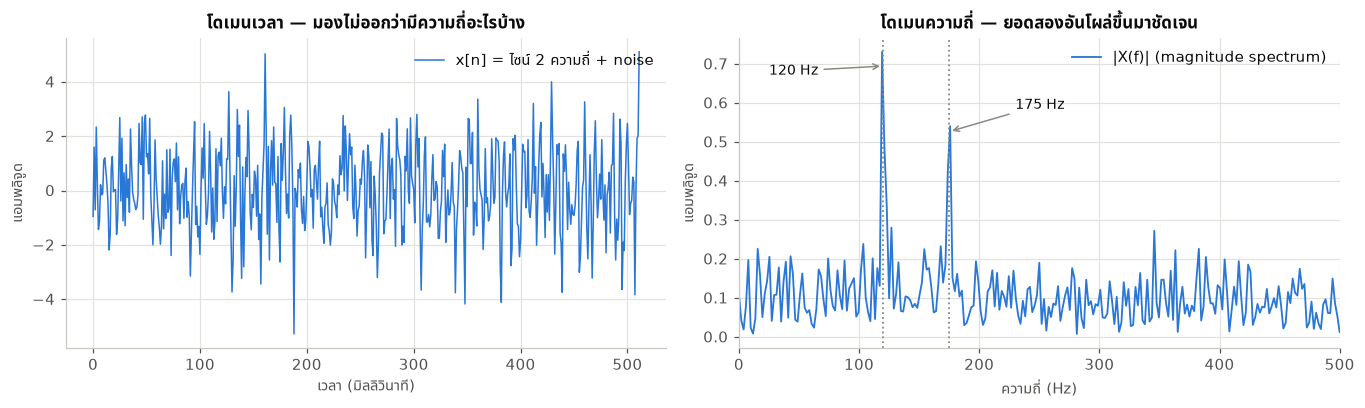

ความถี่จริง: 120 Hz และ 175 Hz
ความละเอียดความถี่ของ DFT: Δf = fs/N = 1.953 Hz


In [2]:
# ---- สัญญาณตัวอย่าง: ไซน์ 2 ความถี่ + white noise ----
fs   = 1000.0                 # ความถี่สุ่ม (Hz)
N    = 512                    # จำนวนจุดข้อมูล
n    = np.arange(N)
t    = n / fs                 # แกนเวลา (วินาที)

f1, f2 = 120.0, 175.0         # ความถี่จริงที่ซ่อนอยู่ (Hz)
clean  = 1.0 * np.sin(2*np.pi*f1*t) + 0.7 * np.sin(2*np.pi*f2*t)
noise  = 1.2 * rng.standard_normal(N)
x      = clean + noise

# สเปกตรัมขนาด (magnitude spectrum) แบบด้านเดียว
X    = np.fft.rfft(x)
freq = np.fft.rfftfreq(N, d=1/fs)
mag  = np.abs(X) / N * 2                       # สเกลให้เป็นแอมพลิจูด

fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.8))

ax[0].plot(t*1000, x, color=C_PER, lw=1.0, label="x[n] = ไซน์ 2 ความถี่ + noise")
ax[0].set_xlabel("เวลา (มิลลิวินาที)")
ax[0].set_ylabel("แอมพลิจูด")
ax[0].set_title("โดเมนเวลา — มองไม่ออกว่ามีความถี่อะไรบ้าง")
ax[0].legend(loc="upper right")

ax[1].plot(freq, mag, color=C_PER, lw=1.2, label="|X(f)| (magnitude spectrum)")
ax[1].axvline(f1, color=C_MUTE, ls=":", lw=1.2)
ax[1].axvline(f2, color=C_MUTE, ls=":", lw=1.2)
ax[1].annotate(f"{f1:.0f} Hz", xy=(f1, mag.max()*0.95), xytext=(f1-95, mag.max()*0.92),
               color=C_TRUE, fontsize=9,
               arrowprops=dict(arrowstyle="->", color=C_MUTE, lw=1))
ax[1].annotate(f"{f2:.0f} Hz", xy=(f2, mag.max()*0.72), xytext=(f2+55, mag.max()*0.80),
               color=C_TRUE, fontsize=9,
               arrowprops=dict(arrowstyle="->", color=C_MUTE, lw=1))
ax[1].set_xlabel("ความถี่ (Hz)")
ax[1].set_ylabel("แอมพลิจูด")
ax[1].set_title("โดเมนความถี่ — ยอดสองอันโผล่ขึ้นมาชัดเจน")
ax[1].set_xlim(0, fs/2)
ax[1].legend(loc="upper right")

plt.tight_layout(); plt.show()

print(f"ความถี่จริง: {f1:.0f} Hz และ {f2:.0f} Hz")
print(f"ความละเอียดความถี่ของ DFT: Δf = fs/N = {fs/N:.3f} Hz")

### สิ่งที่เห็นจากกราฟ

ในโดเมนเวลาแทบมองไม่ออกเลยว่ามีอะไรอยู่ข้างใน แต่พอแปลงเป็นโดเมนความถี่
ยอดสองยอดที่ 120 Hz กับ 175 Hz ก็โผล่ขึ้นมาเหนือพื้นสัญญาณรบกวนทันที

แต่สังเกตให้ดี — **พื้นของสัญญาณรบกวนไม่ได้เรียบ** มันเป็นหญ้าหยาบ ๆ ที่กระโดดขึ้นลง
ตรงนี้แหละคือปมของทั้งโน้ตบุ๊ก และเราจะกลับมาพิสูจน์ในส่วนที่ 4 ว่า
หญ้านี้ **ไม่มีวันเรียบขึ้น** ไม่ว่าจะเก็บข้อมูลนานแค่ไหน

## 1.2 จาก DTFT สู่ DFT

สำหรับสัญญาณเวลาไม่ต่อเนื่อง $x[n]$ นิยาม **DTFT** (Discrete-Time Fourier Transform) คือ

$$X(f) \;=\; \sum_{n=-\infty}^{\infty} x[n]\, e^{-j 2\pi f n}$$

โดย $f$ คือความถี่ปรกติ (normalized frequency, หน่วยรอบต่อตัวอย่าง) ซึ่ง $X(f)$
เป็นฟังก์ชัน **ต่อเนื่อง** และมีคาบเท่ากับ 1

ปัญหาคือคอมพิวเตอร์เก็บฟังก์ชันต่อเนื่องไม่ได้ และเราก็มีข้อมูลแค่ $N$ จุด
ดังนั้นเราจึงคำนวณ **DFT** ซึ่งคือการ *สุ่มค่า* $X(f)$ ที่ความถี่ $N$ จุดเท่า ๆ กัน:

$$X[k] \;=\; \sum_{n=0}^{N-1} x[n]\, e^{-j 2\pi k n / N}
\;=\; X(f)\Big|_{f = k/N}, \qquad k = 0,1,\dots,N-1$$

**DFT ไม่ใช่การแปลงคนละอัน — มันคือ DTFT ที่ถูกสุ่มค่าบนตะแกรงความถี่**
เราตรวจสอบข้อนี้ด้วยตัวเลขได้เลย โดยประมาณ DTFT ด้วยการเติมศูนย์ (zero-padding) เยอะ ๆ

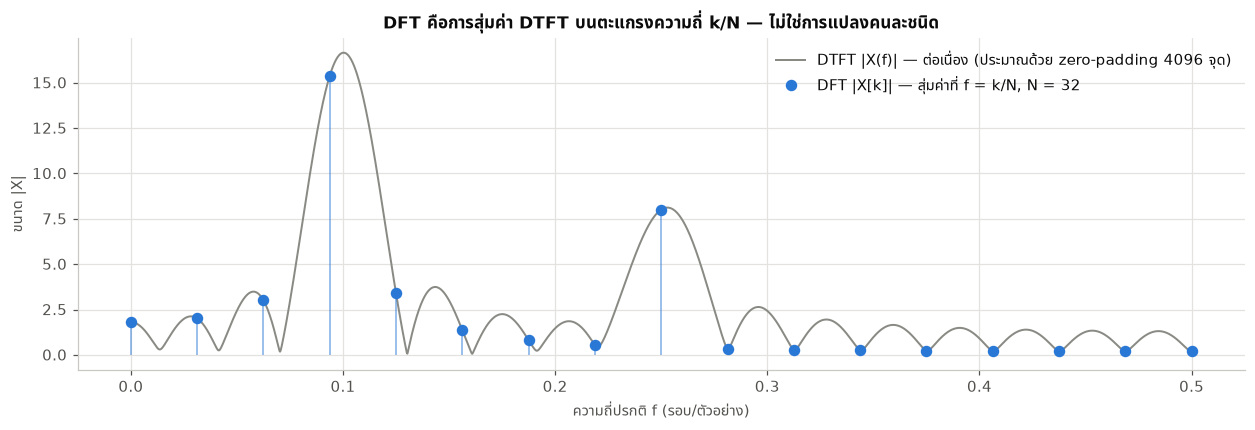

ผลต่างสูงสุดระหว่างจุด DFT กับ DTFT ที่ความถี่เดียวกัน = 1.776e-15
→ ศูนย์ในระดับความละเอียดของเครื่อง ยืนยันว่า DFT = ตัวอย่างของ DTFT


In [3]:
# ---- DFT คือ DTFT ที่ถูกสุ่มค่า ----
Ns = 32
ns = np.arange(Ns)
xs = np.cos(2*np.pi*0.1*ns) + 0.5*np.cos(2*np.pi*0.25*ns)

# DTFT (โดยประมาณ) = เติมศูนย์เยอะ ๆ แล้วทำ FFT → ได้เส้นเกือบต่อเนื่อง
NFFT_dense = 4096
X_dtft = np.fft.rfft(xs, NFFT_dense)
f_dtft = np.fft.rfftfreq(NFFT_dense)          # 0 … 0.5

# DFT ขนาด N จุด = สุ่มค่าที่ f = k/N
X_dft = np.fft.rfft(xs)
f_dft = np.fft.rfftfreq(Ns)

fig, ax = plt.subplots(figsize=(11.5, 4))
ax.plot(f_dtft, np.abs(X_dtft), color=C_MUTE, lw=1.3,
        label="DTFT |X(f)| — ต่อเนื่อง (ประมาณด้วย zero-padding 4096 จุด)")
ax.plot(f_dft, np.abs(X_dft), "o", color=C_PER, ms=6.5, zorder=3,
        label=f"DFT |X[k]| — สุ่มค่าที่ f = k/N, N = {Ns}")
ax.vlines(f_dft, 0, np.abs(X_dft), color=C_PER, lw=1.1, alpha=0.55)
ax.set_xlabel("ความถี่ปรกติ f (รอบ/ตัวอย่าง)")
ax.set_ylabel("ขนาด |X|")
ax.set_title("DFT คือการสุ่มค่า DTFT บนตะแกรงความถี่ k/N — ไม่ใช่การแปลงคนละชนิด")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

# ยืนยันเชิงตัวเลข: จุด DFT ต้องตรงกับ DTFT ที่ตำแหน่งเดียวกันเป๊ะ
idx  = (f_dft * NFFT_dense).astype(int)
err  = np.max(np.abs(X_dtft[idx] - X_dft))
print(f"ผลต่างสูงสุดระหว่างจุด DFT กับ DTFT ที่ความถี่เดียวกัน = {err:.3e}")
print("→ ศูนย์ในระดับความละเอียดของเครื่อง ยืนยันว่า DFT = ตัวอย่างของ DTFT")

ผลต่างอยู่ในระดับ $10^{-14}$ ซึ่งคือความคลาดเคลื่อนปัดเศษของเลขทศนิยม —
ยืนยันว่า DFT คือค่าของ DTFT ที่จุด $f = k/N$ พอดี

**ข้อควรระวังที่จะสำคัญมากในส่วนที่ 5:** การเติมศูนย์ทำให้เส้นกราฟ *ละเอียดขึ้น*
แต่ไม่ได้ทำให้ *แยกแยะความถี่ได้ดีขึ้น* เพราะมันไม่ได้เพิ่มข้อมูลใหม่เลย
มันแค่วาดเส้นเดิมด้วยจุดที่ถี่ขึ้น

---
# ส่วนที่ 2 — Autocorrelation, PSD และทฤษฎีบท Wiener–Khinchin

## 2.1 ปัญหาของสัญญาณสุ่ม

สิ่งที่ทำมาในส่วนที่ 1 ใช้ได้ดีกับสัญญาณ **ที่กำหนดได้แน่นอน (deterministic)**
เช่นคลื่นไซน์ แต่สัญญาณรบกวนเป็น **กระบวนการสุ่ม (random process)** ซึ่งมีปัญหาสองข้อ:

1. **พลังงานไม่จำกัด** — สัญญาณสุ่มที่ดำเนินไปเรื่อย ๆ มี $\sum |x[n]|^2 = \infty$
   ดังนั้น DTFT ในความหมายปกติ *ไม่ลู่เข้า* จะพูดถึง "$X(f)$ ของ white noise" ไม่ได้
2. **ทุกครั้งที่วัดได้ไม่เหมือนกัน** — วัดสองรอบได้ $X(f)$ คนละอัน
   แล้วอันไหนคือ "สเปกตรัมที่ถูกต้อง"?

ทางออกคือ **เลิกอธิบายสัญญาณเป็นราย realization แล้วหันไปอธิบายด้วยค่าสถิติแทน**

## 2.2 กระบวนการ WSS และ Autocorrelation

เราจะสมมติว่าสัญญาณเป็นแบบ **Wide-Sense Stationary (WSS)** คือ

- ค่าเฉลี่ยคงที่:  $E\{x[n]\} = \mu$  (ต่อไปจะให้ $\mu = 0$)
- **ความสัมพันธ์ขึ้นกับระยะห่างเท่านั้น ไม่ขึ้นกับตำแหน่งสัมบูรณ์**

นิยาม **ฟังก์ชันสหสัมพันธ์อัตโนมัติ (autocorrelation function, ACF)**:

$$\boxed{\;r_{xx}[m] \;=\; E\{\,x[n+m]\,x^{*}[n]\,\}\;}$$

$r_{xx}[m]$ ตอบว่า "ค่าที่ห่างกัน $m$ ตัวอย่าง เกี่ยวข้องกันแค่ไหน"

- $r_{xx}[0] = E\{|x[n]|^2\}$ = **กำลังเฉลี่ยของสัญญาณ**
- $|r_{xx}[m]| \le r_{xx}[0]$ ทุก $m$
- $r_{xx}[-m] = r_{xx}^{*}[m]$ (สมมาตรเฮอร์มิเชียน)

## 2.3 นิยาม PSD และทฤษฎีบท Wiener–Khinchin

**ความหนาแน่นสเปกตรัมกำลัง (Power Spectral Density, PSD)** นิยามเป็น
DTFT ของ ACF:

$$\boxed{\;S_{xx}(f) \;=\; \sum_{m=-\infty}^{\infty} r_{xx}[m]\, e^{-j2\pi f m}\;}$$

นี่คือ **ทฤษฎีบท Wiener–Khinchin** ซึ่งบอกว่านิยามข้างบนสมมูลกับอีกนิยามหนึ่ง:

$$S_{xx}(f) \;=\; \lim_{N\to\infty} E\left\{ \frac{1}{N}
\left| \sum_{n=0}^{N-1} x[n] e^{-j2\pi f n} \right|^{2} \right\}$$

**ความสำคัญของสมการที่สอง:** ในวงเล็บปีกกาคือสิ่งที่เราจะเรียกว่า *periodogram* พอดี
ทฤษฎีบทนี้จึงเป็นใบอนุญาตให้เราใช้ periodogram ประมาณ PSD ได้ —
แต่สังเกตเงื่อนไขสองข้อที่ติดมาด้วย และเงื่อนไขทั้งสองนี้เองที่จะเป็นต้นเหตุของปัญหาทั้งหมด:

- $\lim_{N\to\infty}$ — ต้องใช้ข้อมูล **ยาวไม่จำกัด** (เรามีแค่ $N$ จุด → เกิด **bias**)
- $E\{\cdot\}$ — ต้อง **เฉลี่ยหลายรอบ** (เรามีรอบเดียว → เกิด **variance**)

> 💡 ทั้ง Bartlett และ Welch คือความพยายามที่จะ "สร้าง $E\{\cdot\}$ ขึ้นมา"
> จากข้อมูลชุดเดียวที่เรามี

ลองดู ACF ของสัญญาณสามแบบ

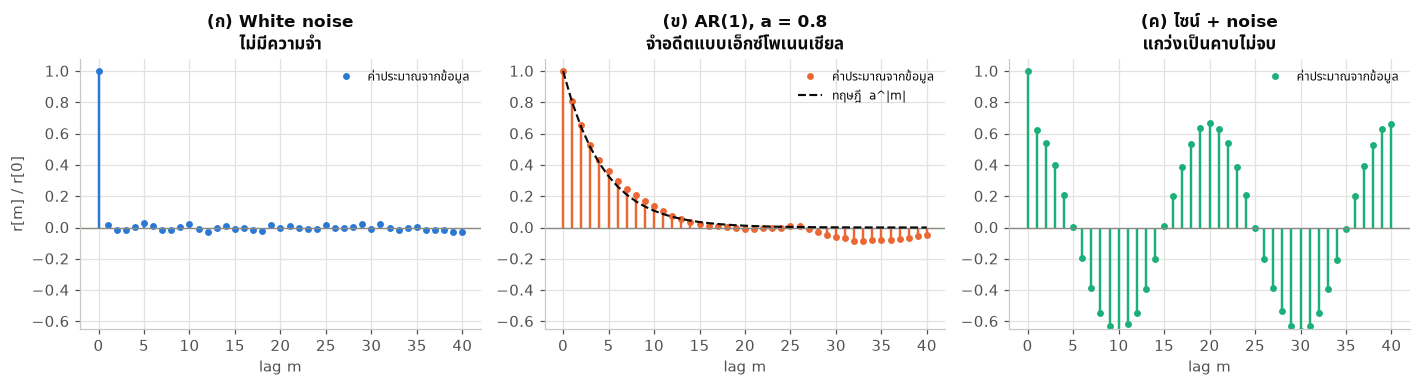

ข้อสังเกต:
  (ก) white noise: r[m] ≈ 0 ทุก m ≠ 0  → สเปกตรัมจะแบนราบ
  (ข) AR(1): r[m] ลดแบบ a^|m| = 0.8^|m| → สเปกตรัมจะเอียงไปทางความถี่ต่ำ
  (ค) ไซน์: r[m] ไม่ลดลง แกว่งเป็นคาบตลอด → สเปกตรัมจะมียอดแหลม


In [4]:
# ---- ACF ของสัญญาณ 3 แบบ ----
M = 4000
lag_max = 40

# (ก) white noise — ไม่มีความสัมพันธ์ข้ามเวลาเลย
w = rng.standard_normal(M)

# (ข) AR(1): x[n] = a·x[n-1] + w[n] — "noise สีชมพู" ที่จำอดีตได้บ้าง
a_ar = 0.8
x_ar = sig.lfilter([1.0], [1.0, -a_ar], rng.standard_normal(M + 500))[500:]

# (ค) ไซน์ + noise — ACF จะแกว่งเป็นคาบไม่จบสิ้น
x_sin = np.sin(2*np.pi*0.05*np.arange(M)) + 0.5*rng.standard_normal(M)

def acf_biased(x, lag_max):
    """ประมาณ ACF แบบ biased: r[m] = (1/N) Σ x[n+m] x*[n], คืนค่า lag 0…lag_max"""
    x = x - x.mean()
    N = len(x)
    r = np.correlate(x, x, mode="full") / N          # index กลาง = lag 0
    mid = N - 1
    return r[mid: mid + lag_max + 1]

lags = np.arange(lag_max + 1)
titles = ["(ก) White noise\nไม่มีความจำ",
          f"(ข) AR(1), a = {a_ar}\nจำอดีตแบบเอ็กซ์โพเนนเชียล",
          "(ค) ไซน์ + noise\nแกว่งเป็นคาบไม่จบ"]
signals = [w, x_ar, x_sin]
colors  = [C_PER, C_BAR, C_WEL]

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for k, (s, ttl, col) in enumerate(zip(signals, titles, colors)):
    r = acf_biased(s, lag_max)
    r = r / r[0]                                     # normalize ให้ r[0] = 1
    ax[k].vlines(lags, 0, r, color=col, lw=1.6)
    ax[k].plot(lags, r, "o", color=col, ms=3.5, label="ค่าประมาณจากข้อมูล")
    ax[k].axhline(0, color=C_MUTE, lw=0.9)
    ax[k].set_title(ttl)
    ax[k].set_xlabel("lag m")
    ax[k].set_ylim(-0.65, 1.08)
    if k == 0:
        ax[k].set_ylabel("r[m] / r[0]")

# ทับเส้นทฤษฎีของ AR(1): r[m] ∝ a^|m|
ax[1].plot(lags, a_ar**lags, "--", color=C_TRUE, lw=1.4, label="ทฤษฎี  a^|m|")
ax[0].legend(loc="upper right", fontsize=8)
ax[1].legend(loc="upper right", fontsize=8)
ax[2].legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

print("ข้อสังเกต:")
print("  (ก) white noise: r[m] ≈ 0 ทุก m ≠ 0  → สเปกตรัมจะแบนราบ")
print(f"  (ข) AR(1): r[m] ลดแบบ a^|m| = {a_ar}^|m| → สเปกตรัมจะเอียงไปทางความถี่ต่ำ")
print("  (ค) ไซน์: r[m] ไม่ลดลง แกว่งเป็นคาบตลอด → สเปกตรัมจะมียอดแหลม")

### ยืนยันทฤษฎีบท Wiener–Khinchin ด้วยตัวเลข

สำหรับกระบวนการ AR(1) ที่ $x[n] = a\,x[n-1] + w[n]$ โดย $w$ เป็น white noise
ที่มีความแปรปรวน $\sigma^2$ เรามีสูตรปิดทั้งสองฝั่ง:

$$r_{xx}[m] = \frac{\sigma^{2}}{1-a^{2}}\, a^{|m|}
\qquad\text{และ}\qquad
S_{xx}(f) = \frac{\sigma^{2}}{\left|1 - a\,e^{-j2\pi f}\right|^{2}}$$

ถ้าทฤษฎีบทเป็นจริง การเอา DTFT ใส่ $r_{xx}[m]$ ต้องได้ $S_{xx}(f)$ ออกมาเป๊ะ ๆ

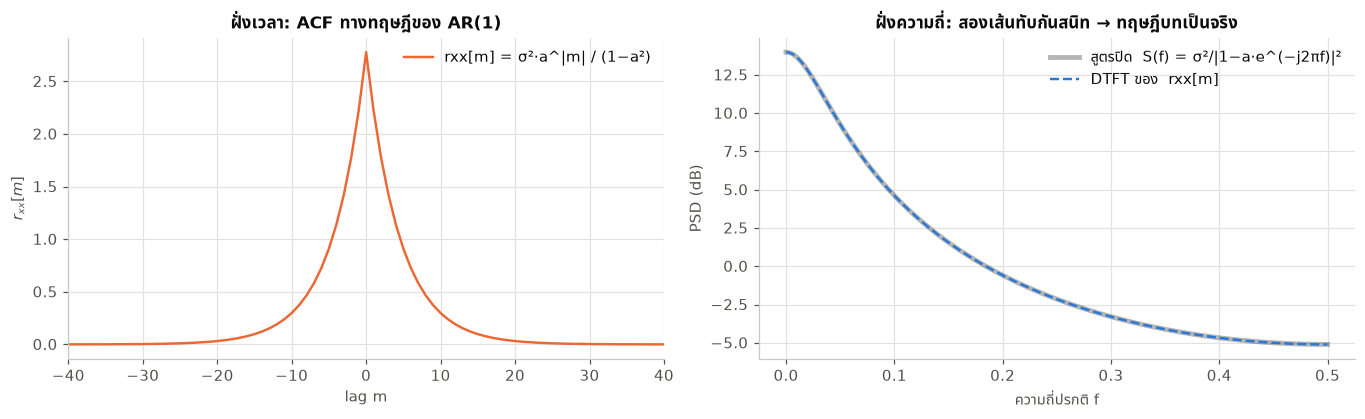

ผลต่างสูงสุดระหว่างสองฝั่ง = 2.487e-14
→ DTFT ของ autocorrelation ให้ PSD ออกมาจริง (Wiener–Khinchin)


In [5]:
# ---- ยืนยัน Wiener–Khinchin: DTFT{ r[m] } == S(f) ----
a_wk, sigma2 = 0.8, 1.0
f_grid = np.linspace(0, 0.5, 1024)

# ฝั่งขวา: สูตรปิดของ PSD
S_closed = sigma2 / np.abs(1 - a_wk*np.exp(-2j*np.pi*f_grid))**2

# ฝั่งซ้าย: เอา DTFT ใส่ ACF ทางทฤษฎีตรง ๆ (ตัดที่ lag ใหญ่พอจนไม่มีผล)
Mmax = 300
m    = np.arange(-Mmax, Mmax + 1)
r_th = sigma2 / (1 - a_wk**2) * a_wk**np.abs(m)
S_from_acf = np.real(r_th @ np.exp(-2j*np.pi*np.outer(m, f_grid)))

fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.9))

ax[0].plot(m, r_th, color=C_BAR, lw=1.6,
           label="rxx[m] = σ²·a^|m| / (1−a²)")
ax[0].set_xlim(-40, 40)
ax[0].set_xlabel("lag m"); ax[0].set_ylabel(r"$r_{xx}[m]$")
ax[0].set_title("ฝั่งเวลา: ACF ทางทฤษฎีของ AR(1)")
ax[0].legend(loc="upper right")

ax[1].plot(f_grid, 10*np.log10(S_closed), color=C_TRUE, lw=3.2, alpha=0.30,
           label="สูตรปิด  S(f) = σ²/|1−a·e^(−j2πf)|²")
ax[1].plot(f_grid, 10*np.log10(S_from_acf), "--", color=C_PER, lw=1.6,
           label="DTFT ของ  rxx[m]")
ax[1].set_xlabel("ความถี่ปรกติ f"); ax[1].set_ylabel("PSD (dB)")
ax[1].set_title("ฝั่งความถี่: สองเส้นทับกันสนิท → ทฤษฎีบทเป็นจริง")
ax[1].legend(loc="upper right")

plt.tight_layout(); plt.show()

print(f"ผลต่างสูงสุดระหว่างสองฝั่ง = {np.max(np.abs(S_closed - S_from_acf)):.3e}")
print("→ DTFT ของ autocorrelation ให้ PSD ออกมาจริง (Wiener–Khinchin)")

สองเส้นทับกันจนแทบแยกไม่ออก (จึงต้องวาดเส้นหนึ่งหนา ๆ จาง ๆ อีกเส้นเป็นเส้นประ)
นี่คือหัวใจที่ทำให้เรื่องทั้งหมดเดินต่อได้:

$$\text{ACF} \;\xleftrightarrow{\;\;\text{DTFT}\;\;}\; \text{PSD}$$

ถ้าเราประมาณ ACF ได้ เราก็ประมาณ PSD ได้ — และนั่นคือสิ่งที่ periodogram ทำอยู่
โดยที่หลายคนไม่รู้ตัว ซึ่งเราจะพิสูจน์ในส่วนถัดไป

---
# ส่วนที่ 3 — Periodogram: นิยามและการพิสูจน์

## 3.1 นิยาม

**Periodogram** ของข้อมูล $N$ จุด คือ

$$\boxed{\;\hat{S}_{\text{per}}(f) \;=\; \frac{1}{N}\left|\,\sum_{n=0}^{N-1} x[n]\,e^{-j2\pi f n}\right|^{2}
\;=\; \frac{1}{N}\left|X(f)\right|^{2}\;}$$

ชื่อนี้มาจาก Arthur Schuster (ค.ศ. 1898) ที่ใช้หาคาบ (period) ที่ซ่อนอยู่ในข้อมูลจุดดับบนดวงอาทิตย์

หน้าตาดูเหมือน "แค่เอา FFT มายกกำลังสองแล้วหารด้วย N" ซึ่งก็ใช่ —
แต่คำถามที่ต้องตอบให้ได้คือ **แล้วทำไมการทำแบบนั้นถึงประมาณ PSD ได้?**

## 3.2 ทฤษฎีบท: periodogram คือ DTFT ของ ACF แบบ biased

> **ทฤษฎีบท** — periodogram เท่ากับ DTFT ของตัวประมาณ autocorrelation แบบ biased:
> $$\hat{S}_{\text{per}}(f) \;=\; \sum_{m=-(N-1)}^{N-1} \hat{r}_{xx}[m]\, e^{-j2\pi f m}
> \qquad\text{โดย}\qquad
> \hat{r}_{xx}[m] \;=\; \frac{1}{N}\sum_{n} x[n+m]\,x^{*}[n]$$

### พิสูจน์

เริ่มจากนิยาม แล้วกระจาย $|X(f)|^2 = X(f)X^{*}(f)$ ออกเป็นผลรวมสองชั้น:

$$\hat{S}_{\text{per}}(f)
= \frac{1}{N} \left(\sum_{n=0}^{N-1} x[n]e^{-j2\pi f n}\right)
             \left(\sum_{k=0}^{N-1} x^{*}[k]e^{+j2\pi f k}\right)
= \frac{1}{N} \sum_{n=0}^{N-1}\sum_{k=0}^{N-1} x[n]\,x^{*}[k]\; e^{-j2\pi f (n-k)}$$

**กุญแจของการพิสูจน์คือเปลี่ยนตัวแปร** ให้ $m = n - k$ (คือ *ระยะห่าง* ระหว่างสองดัชนี)
แล้วจัดกลุ่มพจน์ทั้งหมดที่มีระยะห่าง $m$ เท่ากันไว้ด้วยกัน เขียน $n = k+m$ ได้

$$\hat{S}_{\text{per}}(f)
= \sum_{m=-(N-1)}^{N-1} e^{-j2\pi f m}
  \underbrace{\left[\frac{1}{N}\sum_{k} x[k+m]\,x^{*}[k]\right]}_{\textstyle \hat{r}_{xx}[m]}$$

ขอบเขตของ $m$ คือ $-(N-1)$ ถึง $N-1$ เพราะดัชนีทั้งสองวิ่งอยู่ใน $[0, N-1]$
ผลต่างจึงห่างกันได้มากที่สุด $N-1$ และผลรวมด้านในวิ่งเฉพาะ $k$ ที่ทำให้ทั้ง
$k$ และ $k+m$ ยังอยู่ในช่วงข้อมูล นั่นคือมีพจน์ทั้งหมด $N - |m|$ พจน์  $\blacksquare$

### ทำไมเรียกว่า "biased"

สังเกตว่าผลรวมมี $N - |m|$ พจน์ **แต่หารด้วย $N$** (ไม่ใช่ $N-|m|$)
นี่คือจุดที่ bias เกิดขึ้น และเป็นสิ่งที่จะเป็นตัวเอกของส่วนที่ 4

มาตรวจสอบทฤษฎีบทด้วยตัวเลขกันก่อน — คำนวณสองทางแล้วเทียบกัน

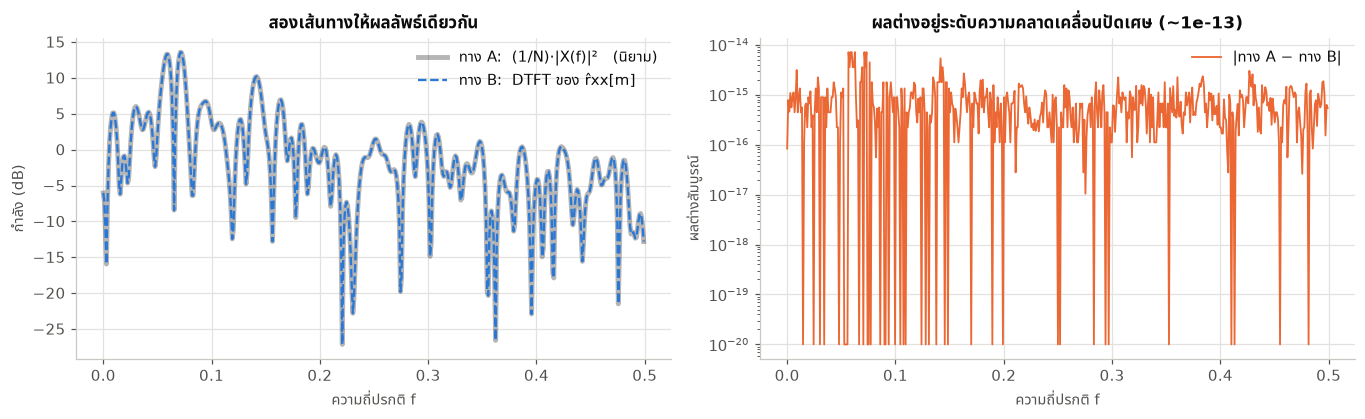

ผลต่างสูงสุด        = 7.105e-15
ขนาดทั่วไปของสัญญาณ = 1.707e+00
ผลต่างสัมพัทธ์       = 4.162e-15  → ยืนยันทฤษฎีบท


In [6]:
# ---- ยืนยันทฤษฎีบท: periodogram == DTFT ของ ACF แบบ biased ----
N_pf  = 128
NFFT  = 1024
x_pf  = sig.lfilter([1.0], [1.0, -0.7], rng.standard_normal(N_pf + 300))[300:]

# ---- ทาง A: ตามนิยามตรง ๆ  (1/N)|FFT|² ----
P_direct = np.abs(np.fft.fft(x_pf, NFFT))**2 / N_pf

# ---- ทาง B: หา ACF แบบ biased ก่อน แล้วค่อย DTFT ----
r_full = np.correlate(x_pf, x_pf, mode="full") / N_pf     # lag = -(N-1) … (N-1)
lags   = np.arange(-(N_pf - 1), N_pf)
seq    = np.zeros(NFFT)
seq[lags % NFFT] = r_full        # lag ลบวางไว้ท้ายอาเรย์ (สมบัติคาบของ DFT)
P_via_acf = np.real(np.fft.fft(seq))

f_ax = np.fft.fftfreq(NFFT)[:NFFT//2]
sl   = slice(0, NFFT//2)

fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.9))

ax[0].plot(f_ax, 10*np.log10(P_direct[sl]), color=C_TRUE, lw=3.2, alpha=0.30,
           label="ทาง A:  (1/N)·|X(f)|²   (นิยาม)")
ax[0].plot(f_ax, 10*np.log10(P_via_acf[sl]), "--", color=C_PER, lw=1.5,
           label="ทาง B:  DTFT ของ r̂xx[m]")
ax[0].set_xlabel("ความถี่ปรกติ f"); ax[0].set_ylabel("กำลัง (dB)")
ax[0].set_title("สองเส้นทางให้ผลลัพธ์เดียวกัน")
ax[0].legend(loc="upper right")

err = np.abs(P_direct - P_via_acf)
ax[1].semilogy(f_ax, err[sl] + 1e-20, color=C_BAR, lw=1.2,
               label="|ทาง A − ทาง B|")
ax[1].set_xlabel("ความถี่ปรกติ f"); ax[1].set_ylabel("ผลต่างสัมบูรณ์")
ax[1].set_title("ผลต่างอยู่ระดับความคลาดเคลื่อนปัดเศษ (~1e-13)")
ax[1].legend(loc="upper right")

plt.tight_layout(); plt.show()

print(f"ผลต่างสูงสุด        = {err.max():.3e}")
print(f"ขนาดทั่วไปของสัญญาณ = {P_direct.mean():.3e}")
print(f"ผลต่างสัมพัทธ์       = {err.max()/P_direct.mean():.3e}  → ยืนยันทฤษฎีบท")

ผลต่างสัมพัทธ์อยู่ระดับ $10^{-15}$ — เป็นแค่ความคลาดเคลื่อนปัดเศษ ทฤษฎีบทเป็นจริง

**นี่คือประโยคสำคัญของทั้งโน้ตบุ๊ก:**

> เวลาคุณคำนวณ periodogram คุณกำลังทำ DTFT ให้กับ ACF *ที่ประมาณมาแบบ biased* อยู่โดยไม่รู้ตัว
> คุณภาพของ periodogram จึงถูกกำหนดโดยคุณภาพของตัวประมาณ ACF ตัวนั้นทั้งหมด

## 3.3 ตัวประมาณ ACF: biased กับ unbiased

มีสองทางเลือกในการประมาณ $r_{xx}[m]$ จากข้อมูล $N$ จุด:

$$\hat{r}_{\text{biased}}[m] = \frac{1}{N}\sum_{n=0}^{N-1-|m|} x[n+|m|]x^{*}[n]
\qquad
\hat{r}_{\text{unbiased}}[m] = \frac{1}{N-|m|}\sum_{n=0}^{N-1-|m|} x[n+|m|]x^{*}[n]$$

หาค่าคาดหวังของทั้งคู่ โดยใช้ว่าแต่ละพจน์มีค่าคาดหวัง $E\{x[n+m]x^*[n]\} = r_{xx}[m]$
และมีพจน์ทั้งหมด $N - |m|$ พจน์:

$$E\{\hat{r}_{\text{biased}}[m]\} = \frac{N-|m|}{N}\,r_{xx}[m]
= \underbrace{\left(1 - \frac{|m|}{N}\right)}_{\textstyle w_{B}[m]}\, r_{xx}[m],
\qquad
E\{\hat{r}_{\text{unbiased}}[m]\} = r_{xx}[m]$$

ตัวที่สอง *ไม่มี bias* แต่ **เราใช้ตัวแรก** — ทำไม? มีเหตุผลสองข้อ:

1. ตัวที่สองมี **variance ระเบิด** ที่ lag สูง เพราะที่ $m$ ใกล้ $N$ เหลือแค่ไม่กี่พจน์ให้เฉลี่ย
   (ที่ $m = N-1$ เหลือพจน์เดียว!) แต่ยังหารด้วยเลขน้อย ๆ อยู่
2. ตัวที่สอง **ไม่รับประกันว่าเป็น positive semi-definite** → DTFT ของมัน
   อาจติดลบ ซึ่งเป็นไปไม่ได้สำหรับ PSD (กำลังติดลบไม่ได้)

ส่วนตัวแรกมี $\hat{S}_{\text{per}}(f) = \frac{1}{N}|X(f)|^2 \ge 0$ เสมอโดยอัตโนมัติ

**ตัวคูณ $w_B[m] = 1 - |m|/N$ ที่โผล่มาเองนั้นคือหน้าต่างสามเหลี่ยม** เรียกว่า
**Bartlett window** — มันไม่ได้ถูกใส่เข้าไป แต่เกิดขึ้นเองจากการที่ข้อมูลมีจำกัด

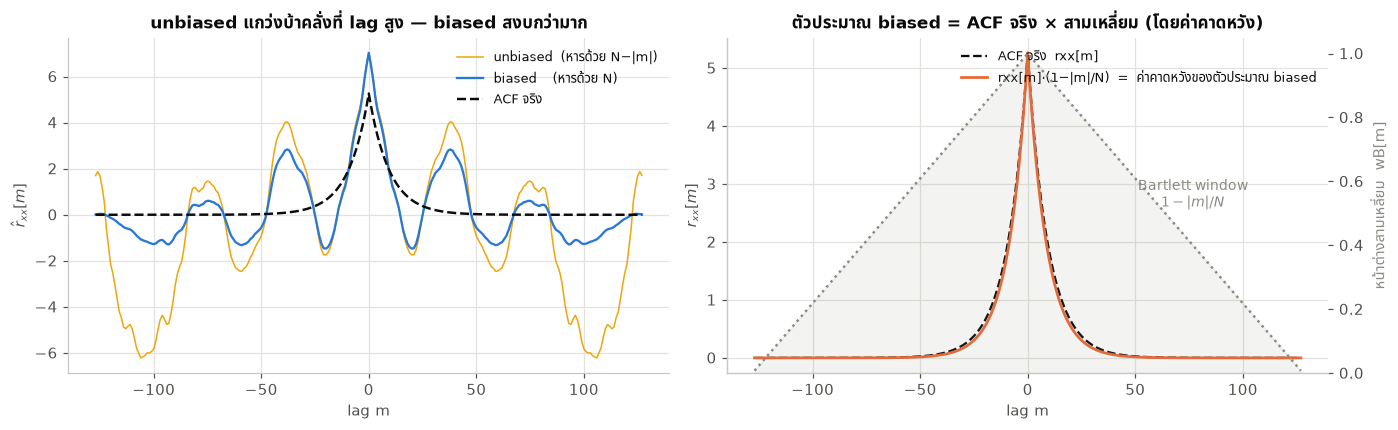

ส่วนเบี่ยงเบนที่ lag สูง (|m| > 0.8N):
   unbiased :    2.750   ← แกว่งหนัก
   biased   :    0.413   ← ถูกกดด้วยสามเหลี่ยม


In [7]:
# ---- biased vs unbiased ACF: ดูว่าหน้าต่างสามเหลี่ยมโผล่มาเองอย่างไร ----
N_acf  = 128
a_acf  = 0.9
x_acf  = sig.lfilter([1.0], [1.0, -a_acf], rng.standard_normal(N_acf + 400))[400:]

lg     = np.arange(-(N_acf-1), N_acf)
raw    = np.correlate(x_acf, x_acf, mode="full")
r_bias = raw / N_acf                      # หารด้วย N คงที่
r_unb  = raw / (N_acf - np.abs(lg))       # หารด้วยจำนวนพจน์จริง
r_true = (1/(1-a_acf**2)) * a_acf**np.abs(lg)     # ACF จริงของ AR(1)
w_bart = 1 - np.abs(lg)/N_acf                     # หน้าต่างสามเหลี่ยม

fig, ax = plt.subplots(1, 2, figsize=(12.8, 4.0))

ax[0].plot(lg, r_unb,  color=C_ALT, lw=1.0, alpha=0.95, label="unbiased  (หารด้วย N−|m|)")
ax[0].plot(lg, r_bias, color=C_PER, lw=1.5,             label="biased    (หารด้วย N)")
ax[0].plot(lg, r_true, "--", color=C_TRUE, lw=1.6,      label="ACF จริง")
ax[0].set_xlabel("lag m"); ax[0].set_ylabel(r"$\hat{r}_{xx}[m]$")
ax[0].set_title("unbiased แกว่งบ้าคลั่งที่ lag สูง — biased สงบกว่ามาก")
ax[0].legend(loc="upper right", fontsize=8.5)

# แสดงว่า biased = true × สามเหลี่ยม (โดยเฉลี่ย)
ax[1].plot(lg, r_true, "--", color=C_TRUE, lw=1.5, label="ACF จริง  rxx[m]")
ax[1].plot(lg, r_true*w_bart, color=C_BAR, lw=1.8,
           label="rxx[m]·(1−|m|/N)  =  ค่าคาดหวังของตัวประมาณ biased")
ax2 = ax[1].twinx()
ax2.plot(lg, w_bart, ":", color=C_MUTE, lw=1.6)
ax2.fill_between(lg, 0, w_bart, color=C_MUTE, alpha=0.10)
ax2.set_ylabel("หน้าต่างสามเหลี่ยม  wB[m]", color=C_MUTE)
ax2.set_ylim(0, 1.05); ax2.grid(False)
ax2.text(0.60*N_acf, 0.52, "Bartlett window\n$1-|m|/N$", color=C_MUTE,
         fontsize=9, ha="center")
ax[1].set_xlabel("lag m"); ax[1].set_ylabel(r"$r_{xx}[m]$")
ax[1].set_title("ตัวประมาณ biased = ACF จริง × สามเหลี่ยม (โดยค่าคาดหวัง)")
ax[1].legend(loc="upper right", fontsize=8.5)

plt.tight_layout(); plt.show()

hi = np.abs(lg) > 0.8*N_acf
print(f"ส่วนเบี่ยงเบนที่ lag สูง (|m| > 0.8N):")
print(f"   unbiased : {r_unb[hi].std():8.3f}   ← แกว่งหนัก")
print(f"   biased   : {r_bias[hi].std():8.3f}   ← ถูกกดด้วยสามเหลี่ยม")

กราฟซ้ายอธิบายว่าทำไมเราถึงยอมรับ bias: ตัวประมาณ unbiased (เส้นเหลือง)
แกว่งอย่างบ้าคลั่งที่ lag สูง เพราะหารด้วยจำนวนน้อย ๆ ส่วนตัว biased (น้ำเงิน)
ถูกหน้าต่างสามเหลี่ยมกดให้เข้าใกล้ศูนย์ ซึ่งเสถียรกว่ามาก

**เรากำลังแลก bias เพื่อให้ได้ variance ที่น้อยลง** — ธีมนี้จะวนกลับมาซ้ำตลอดทั้งโน้ตบุ๊ก

---
# ส่วนที่ 4 — คุณสมบัติทางสถิติ: ทำไม periodogram ถึงใช้ไม่ได้จริง

ตัวประมาณที่ดีต้องมีสองคุณสมบัติ พอ $N \to \infty$:

1. **Asymptotically unbiased:** $E\{\hat{S}(f)\} \to S(f)$ — เล็งถูกเป้าโดยเฉลี่ย
2. **Consistent:** $\operatorname{Var}\{\hat{S}(f)\} \to 0$ — ยิ่งข้อมูลเยอะยิ่งนิ่ง

เราจะพิสูจน์ว่า periodogram **ผ่านข้อแรก แต่ตกข้อที่สองอย่างสิ้นเชิง**

## 4.1 พิสูจน์ bias — Fejér kernel

จากทฤษฎีบทในส่วนที่ 3 ใส่ค่าคาดหวังเข้าไปทั้งสองข้าง:

$$E\{\hat{S}_{\text{per}}(f)\}
= \sum_{m=-(N-1)}^{N-1} E\{\hat{r}_{xx}[m]\}\, e^{-j2\pi f m}
= \sum_{m=-(N-1)}^{N-1} \left(1-\frac{|m|}{N}\right) r_{xx}[m]\, e^{-j2\pi f m}$$

ด้านขวาคือ DTFT ของ **ผลคูณ** $w_B[m]\cdot r_{xx}[m]$ และตามทฤษฎีบทการคูณ
(multiplication theorem) การคูณในโดเมนเวลา = การคอนโวลูชันในโดเมนความถี่:

$$\boxed{\;E\{\hat{S}_{\text{per}}(f)\} \;=\; S_{xx}(f) \circledast W_{B}(f)
\;=\; \int_{-1/2}^{1/2} S_{xx}(\nu)\, W_{B}(f-\nu)\, d\nu \;}$$

โดย $W_B(f)$ คือ DTFT ของหน้าต่างสามเหลี่ยม ซึ่งมีชื่อเฉพาะว่า **Fejér kernel**:

$$W_{B}(f) \;=\; \frac{1}{N}\left(\frac{\sin(\pi f N)}{\sin(\pi f)}\right)^{2} \;\ge 0$$

### ตีความ

**periodogram ไม่ได้ให้ $S(f)$ แต่ให้ $S(f)$ ที่ถูกทำให้เบลอด้วย Fejér kernel**
เหมือนถ่ายรูปด้วยเลนส์ที่โฟกัสไม่คม

- ความกว้างของโลบหลัก (main lobe) $\approx 2/N$ → **จำกัดความละเอียดเชิงความถี่**
- โลบข้าง (side lobes) สูงสุด $\approx -13$ dB → **ทำให้เกิด spectral leakage**
- เมื่อ $N \to \infty$: $W_B(f) \to \delta(f)$ ดังนั้น $E\{\hat{S}\} \to S$
  → **asymptotically unbiased** ✔

ลองดู Fejér kernel ที่ $N$ ต่าง ๆ

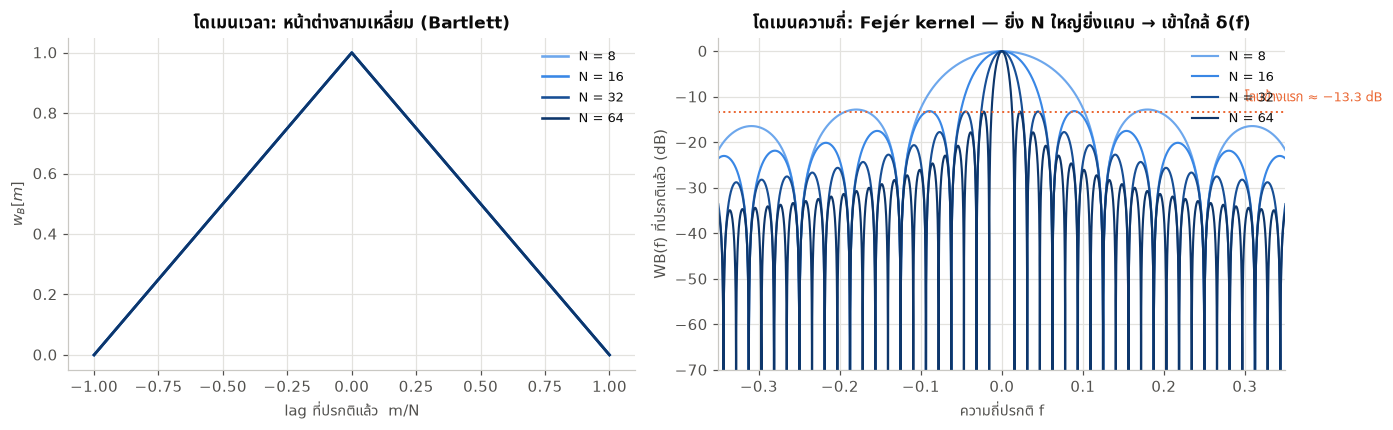

N =   8 : ความกว้างโลบหลัก (null-to-null) = 2/N = 0.2500 รอบ/ตัวอย่าง
N =  16 : ความกว้างโลบหลัก (null-to-null) = 2/N = 0.1250 รอบ/ตัวอย่าง
N =  32 : ความกว้างโลบหลัก (null-to-null) = 2/N = 0.0625 รอบ/ตัวอย่าง
N =  64 : ความกว้างโลบหลัก (null-to-null) = 2/N = 0.0312 รอบ/ตัวอย่าง


In [8]:
# ---- Fejér kernel: หน้าต่างสามเหลี่ยม และผลของมันในโดเมนความถี่ ----
f_fk = np.linspace(-0.5, 0.5, 8001)

def fejer(f, N):
    """Fejér kernel W_B(f) = (1/N)·(sin(πfN)/sin(πf))² ; จัดการ f→0 แยก"""
    num = np.sin(np.pi*f*N)
    den = np.sin(np.pi*f)
    out = np.empty_like(f)
    small = np.abs(den) < 1e-12
    out[~small] = (num[~small]/den[~small])**2 / N
    out[small]  = N                      # ลิมิตที่ f = 0 คือ N
    return out

fig, ax = plt.subplots(1, 2, figsize=(12.8, 4.0))

Ns_demo = [8, 16, 32, 64]
for N_d, col in zip(Ns_demo, [BLUES[2], BLUES[3], BLUES[5], BLUES[6]]):
    mm = np.arange(-N_d, N_d+1)
    ax[0].plot(mm/N_d, np.maximum(1-np.abs(mm)/N_d, 0), color=col, lw=1.7,
               label=f"N = {N_d}")
    W = fejer(f_fk, N_d)
    ax[1].plot(f_fk, 10*np.log10(W/W.max() + 1e-16), color=col, lw=1.4,
               label=f"N = {N_d}")

ax[0].set_xlabel("lag ที่ปรกติแล้ว  m/N"); ax[0].set_ylabel("$w_B[m]$")
ax[0].set_title("โดเมนเวลา: หน้าต่างสามเหลี่ยม (Bartlett)")
ax[0].legend(loc="upper right", fontsize=8.5)

ax[1].axhline(-13.3, color=C_BAR, ls=":", lw=1.3)
ax[1].text(0.30, -11.0, "โลบข้างแรก ≈ −13.3 dB", color=C_BAR, fontsize=8.5)
ax[1].set_xlim(-0.35, 0.35); ax[1].set_ylim(-70, 3)
ax[1].set_xlabel("ความถี่ปรกติ f"); ax[1].set_ylabel("WB(f) ที่ปรกติแล้ว (dB)")
ax[1].set_title("โดเมนความถี่: Fejér kernel — ยิ่ง N ใหญ่ยิ่งแคบ → เข้าใกล้ δ(f)")
ax[1].legend(loc="upper right", fontsize=8.5)

plt.tight_layout(); plt.show()

for N_d in Ns_demo:
    print(f"N = {N_d:3d} : ความกว้างโลบหลัก (null-to-null) = 2/N = {2/N_d:.4f} รอบ/ตัวอย่าง")

### ยืนยัน bias ด้วยการจำลอง

เราจะเทียบสามอย่างที่ควรสอดคล้องกัน:

1. **PSD จริง** $S(f)$ — จากสูตรปิดของ AR
2. **ค่าคาดหวังทางทฤษฎี** $\sum_m (1-|m|/N)\,r_{xx}[m]e^{-j2\pi fm}$ — คำนวณตรงจากสูตรที่พิสูจน์มา
3. **ค่าเฉลี่ยจาก Monte Carlo** — เฉลี่ย periodogram จาก 5,000 realization

ถ้าการพิสูจน์ถูกต้อง อันที่ 2 กับ 3 ต้องทับกัน และทั้งคู่ต้อง *ต่างจาก* อันที่ 1 อยู่บ้าง (นั่นคือ bias)

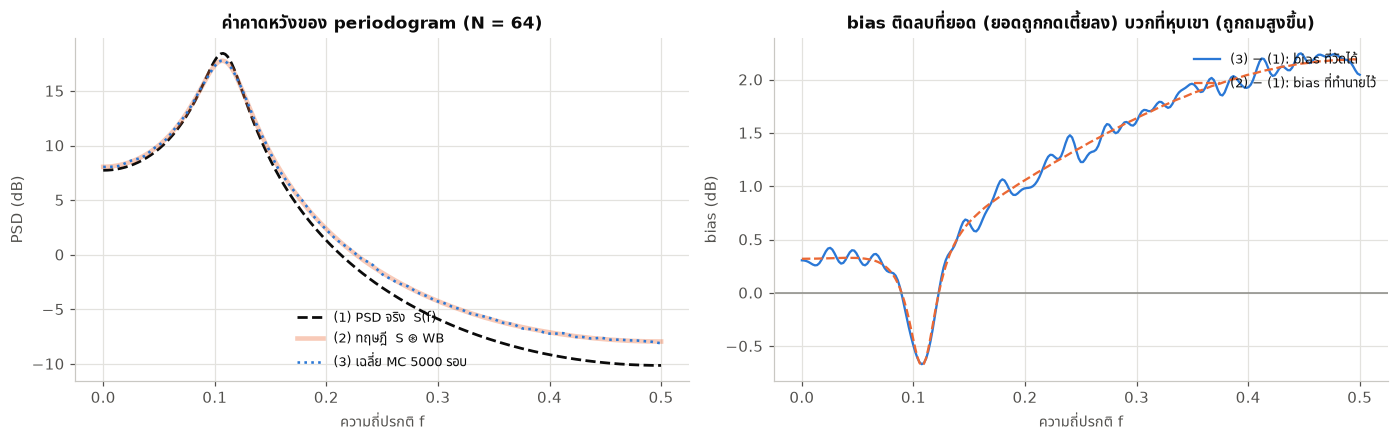

ผลต่างระหว่างทฤษฎี(2) กับ Monte Carlo(3) : สูงสุด 0.171 dB
bias สูงสุดเทียบกับ PSD จริง               : 2.19 dB


In [9]:
# ---- ยืนยัน bias: ค่าเฉลี่ยของ periodogram = S(f) ⊛ Fejér ----
# ใช้กระบวนการ AR(2) ที่มียอดแหลม เพื่อให้เห็น bias ชัด
a_coef = np.array([1.0, -1.40, 0.81])      # ตัวส่วนของ AR(2) → มี resonance
N_b    = 64                                 # ใช้ N น้อย ๆ เพื่อให้ bias เด่น
NF     = 512
f_b    = np.fft.rfftfreq(NF)

# (1) PSD จริงจากสูตรปิด: S(f) = σ²/|A(e^{j2πf})|²
#     ส่ง worN เป็นอาเรย์ความถี่ เพื่อให้ประเมินบนตะแกรงเดียวกับ rfftfreq พอดี
_, H   = sig.freqz([1.0], a_coef, worN=f_b, fs=1.0)
S_true = np.abs(H)**2

# ACF จริงของกระบวนการ (หาโดยแปลงกลับจาก PSD ที่ละเอียดมาก)
NF_fine = 8192
_, Hf   = sig.freqz([1.0], a_coef, worN=NF_fine, whole=True)
r_true_full = np.real(np.fft.ifft(np.abs(Hf)**2))

# (2) ค่าคาดหวังทางทฤษฎี: DTFT ของ (1-|m|/N)·r[m]
m_b   = np.arange(-(N_b-1), N_b)
r_b   = r_true_full[np.abs(m_b)]
S_exp = np.real((r_b*(1-np.abs(m_b)/N_b)) @ np.exp(-2j*np.pi*np.outer(m_b, f_b)))

# (3) Monte Carlo
n_mc  = 5000
acc   = np.zeros(len(f_b))
for _ in range(n_mc):
    xb  = sig.lfilter([1.0], a_coef, rng.standard_normal(N_b + 500))[500:]
    acc += np.abs(np.fft.rfft(xb, NF))**2 / N_b
S_mc = acc / n_mc

fig, ax = plt.subplots(1, 2, figsize=(12.8, 4.1))

ax[0].plot(f_b, 10*np.log10(S_true), "--", color=C_TRUE, lw=1.8, label="(1) PSD จริง  S(f)")
ax[0].plot(f_b, 10*np.log10(S_exp),  color=C_BAR, lw=3.0, alpha=0.35,
           label="(2) ทฤษฎี  S ⊛ WB")
ax[0].plot(f_b, 10*np.log10(S_mc), ":", color=C_PER, lw=1.7,
           label=f"(3) เฉลี่ย MC {n_mc} รอบ")
ax[0].set_xlabel("ความถี่ปรกติ f"); ax[0].set_ylabel("PSD (dB)")
ax[0].set_title(f"ค่าคาดหวังของ periodogram (N = {N_b})")
ax[0].legend(loc="lower center", fontsize=8.5)

ax[1].plot(f_b, 10*np.log10(S_mc) - 10*np.log10(S_true), color=C_PER, lw=1.5,
           label="(3) − (1): bias ที่วัดได้")
ax[1].plot(f_b, 10*np.log10(S_exp) - 10*np.log10(S_true), "--", color=C_BAR, lw=1.5,
           label="(2) − (1): bias ที่ทำนายไว้")
ax[1].axhline(0, color=C_MUTE, lw=1.0)
ax[1].set_xlabel("ความถี่ปรกติ f"); ax[1].set_ylabel("bias (dB)")
ax[1].set_title("bias ติดลบที่ยอด (ยอดถูกกดเตี้ยลง) บวกที่หุบเขา (ถูกถมสูงขึ้น)")
ax[1].legend(loc="upper right", fontsize=8.5)

plt.tight_layout(); plt.show()

print(f"ผลต่างระหว่างทฤษฎี(2) กับ Monte Carlo(3) : สูงสุด {np.max(np.abs(10*np.log10(S_exp/S_mc))):.3f} dB")
print(f"bias สูงสุดเทียบกับ PSD จริง               : {np.max(np.abs(10*np.log10(S_exp/S_true))):.2f} dB")

ทฤษฎีกับ Monte Carlo ทับกันสนิท (ต่างกันไม่ถึงเศษเสี้ยว dB ซึ่งมาจากความคลาดเคลื่อนของการสุ่ม)
→ **การพิสูจน์ bias ถูกต้อง**

กราฟขวาแสดงรูปแบบของ bias ที่คลาสสิกมาก:
- **ยอดถูกกดให้เตี้ยลง** (bias ติดลบ) เพราะการเบลอทำให้พลังงานที่ยอดกระจายออกไปรอบ ๆ
- **หุบเขาถูกถมให้สูงขึ้น** (bias เป็นบวก) เพราะได้รับพลังงานที่รั่วมาจากยอด

ยิ่งสเปกตรัมมี dynamic range สูง (ยอดสูง หุบลึก) bias ยิ่งรุนแรง

## 4.2 พิสูจน์ variance — ปัญหาที่แท้จริง

ทีนี้มาถึงส่วนที่น่าตกใจ สำหรับ Gaussian white noise ที่มี PSD เท่ากับ $S(f) = \sigma^2$
สามารถแสดงได้ว่า

$$\boxed{\;\operatorname{Var}\{\hat{S}_{\text{per}}(f)\} \;\approx\; S^{2}(f)
\qquad \text{สำหรับ } 0 < f < 1/2\;}$$

**สังเกตให้ดีว่าฝั่งขวา ไม่มี $N$ อยู่เลย**

$$\frac{\text{ส่วนเบี่ยงเบนมาตรฐาน}}{\text{ค่าเฉลี่ย}}
= \frac{\sqrt{\operatorname{Var}}}{E\{\hat{S}\}} \approx \frac{S(f)}{S(f)} = 1 = 100\%$$

> **ความคลาดเคลื่อนอยู่ที่ 100% เสมอ ไม่ว่าจะเก็บข้อมูลกี่จุด**
> เก็บข้อมูล 1 ล้านจุด ก็ยังคลาดเคลื่อน 100% เท่าเดิม
> → periodogram **ไม่ใช่ตัวประมาณที่ consistent**

### ทำไมถึงเป็นแบบนั้น — คำอธิบายเชิงสัญชาตญาณ

นี่คือเหตุผลที่เข้าใจง่ายที่สุด และเป็นกุญแจไปสู่ Bartlett/Welch:

- เพิ่ม $N$ เป็นสองเท่า → ได้จุดข้อมูลใหม่ $N$ จุด **แต่ก็ได้จุดความถี่ใหม่ $N$ จุดด้วย**
- ที่ความถี่ **แต่ละจุด** จำนวนข้อมูลที่ใช้ประมาณค่ายัง "เท่าเดิม" เสมอ
- พูดอีกอย่าง: การเพิ่ม $N$ ทำให้ได้ค่าประมาณ **จำนวนมากขึ้น** แต่ไม่ได้ทำให้แต่ละค่า **ดีขึ้น**

$$N \uparrow \;\Rightarrow\; \text{จำนวนจุดความถี่} \uparrow \;\;\text{แต่}\;\; \text{คุณภาพต่อจุด} = \text{คงที่}$$

### รูปแบบการแจกแจง

สำหรับ Gaussian process ทั้ง $\mathrm{Re}\{X(f)\}$ และ $\mathrm{Im}\{X(f)\}$ เป็น Gaussian
ที่เป็นอิสระต่อกัน ดังนั้น $|X(f)|^2$ = ผลบวกกำลังสองของ Gaussian สองตัว:

$$\frac{2\,\hat{S}_{\text{per}}(f)}{S(f)} \;\sim\; \chi^{2}_{2}
\qquad\Longleftrightarrow\qquad
\frac{\hat{S}_{\text{per}}(f)}{S(f)} \;\sim\; \text{Exponential}(1)$$

การแจกแจงเอ็กซ์โพเนนเชียลมี mean = 1 และ **standard deviation = 1** ซึ่งยืนยันสูตร variance ข้างบน
(ที่ $f = 0$ และ $f = 1/2$ ค่าเป็นจำนวนจริงล้วน จึงเป็น $\chi^2_1$ ซึ่ง variance เป็น $2S^2$ — แย่กว่าอีก)

มาดูของจริงกัน — **นี่คือกราฟที่สำคัญที่สุดในโน้ตบุ๊กนี้**

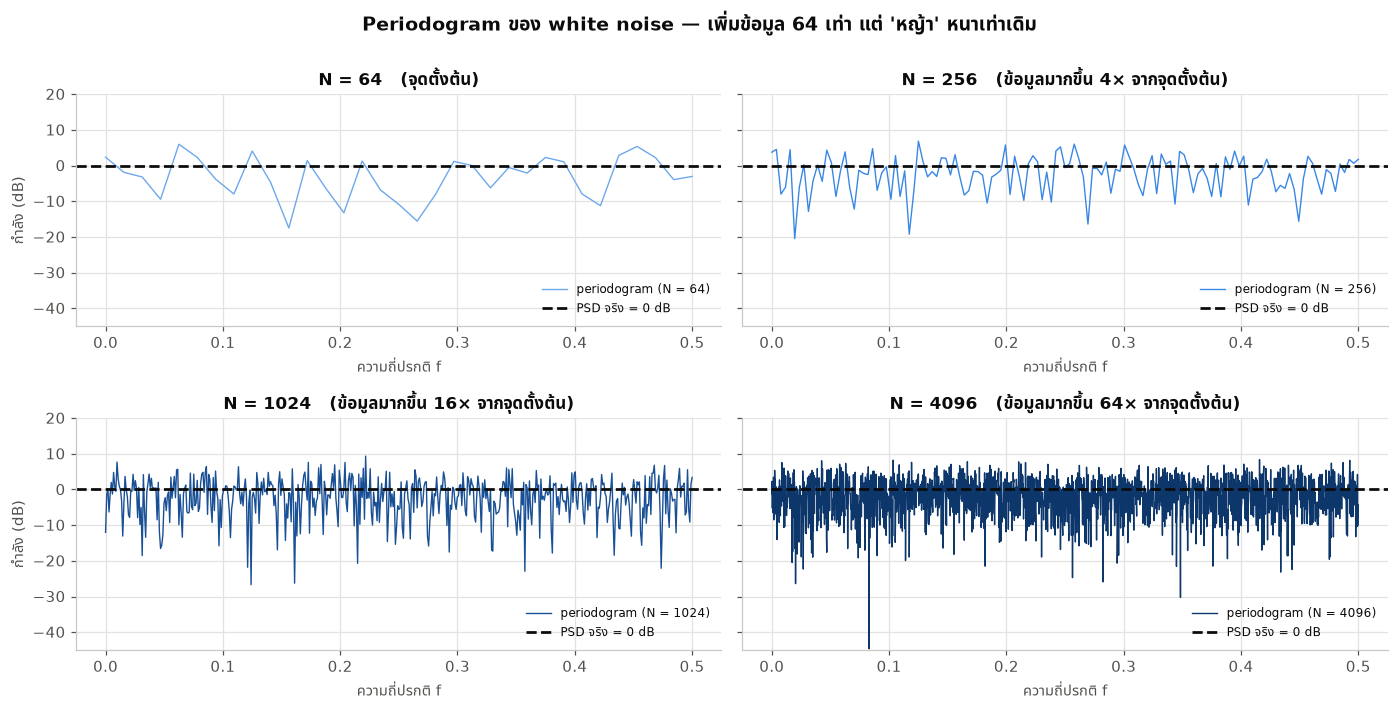

ส่วนเบี่ยงเบนมาตรฐานของค่าที่ประมาณได้ (ควรอยู่ใกล้ S = 1.0 ทุกกรณี):
   N =    64 :  mean = 0.872   std = 0.862
   N =   256 :  mean = 0.906   std = 0.935
   N =  1024 :  mean = 1.016   std = 1.029
   N =  4096 :  mean = 0.999   std = 0.993


In [10]:
# ---- กราฟสำคัญที่สุด: เพิ่ม N เท่าไหร่ ก็ไม่เรียบขึ้น ----
sigma  = 1.0
S0     = sigma**2                       # PSD จริงของ white noise (สองด้าน, fs=1)
N_list = [64, 256, 1024, 4096]

fig, axes = plt.subplots(2, 2, figsize=(12.8, 6.4), sharey=True)

for axk, N_v, col in zip(axes.ravel(), N_list, [BLUES[2], BLUES[3], BLUES[5], BLUES[6]]):
    xv = sigma*rng.standard_normal(N_v)
    Pv = np.abs(np.fft.rfft(xv))**2 / N_v
    fv = np.fft.rfftfreq(N_v)

    axk.plot(fv, 10*np.log10(Pv + 1e-12), color=col, lw=0.9,
             label=f"periodogram (N = {N_v})")
    axk.axhline(10*np.log10(S0), color=C_TRUE, ls="--", lw=1.8,
                label="PSD จริง = 0 dB")
    axk.set_title(f"N = {N_v}" + ("   (จุดตั้งต้น)" if N_v == 64
                 else f"   (ข้อมูลมากขึ้น {N_v//64}× จากจุดตั้งต้น)"))
    axk.set_ylim(-45, 20)
    axk.legend(loc="lower right", fontsize=8)
    axk.set_xlabel("ความถี่ปรกติ f")

axes[0,0].set_ylabel("กำลัง (dB)"); axes[1,0].set_ylabel("กำลัง (dB)")
fig.suptitle("Periodogram ของ white noise — เพิ่มข้อมูล 64 เท่า แต่ 'หญ้า' หนาเท่าเดิม",
             fontsize=12.5, fontweight="bold", y=1.00)
plt.tight_layout(); plt.show()

print("ส่วนเบี่ยงเบนมาตรฐานของค่าที่ประมาณได้ (ควรอยู่ใกล้ S = 1.0 ทุกกรณี):")
for N_v in N_list:
    xv = sigma*rng.standard_normal(N_v)
    Pv = np.abs(np.fft.rfft(xv))**2 / N_v
    print(f"   N = {N_v:5d} :  mean = {Pv.mean():.3f}   std = {Pv.std():.3f}")

**ดูให้ดี** — ทั้งสี่กราฟใช้ข้อมูลต่างกันถึง 64 เท่า แต่ความหนาของ "หญ้า" เท่ากันเป๊ะ
มีแค่จุดข้อมูลถี่ขึ้นเท่านั้น

ค่า `std` ที่พิมพ์ออกมาก็ยืนยัน: มันวนอยู่ราว 1.0 ทุกกรณี ตรงตามที่พิสูจน์ว่า
$\sqrt{\operatorname{Var}} \approx S = 1$

มาวัดกันตรง ๆ ด้วย Monte Carlo และดูรูปแบบการแจกแจงด้วย

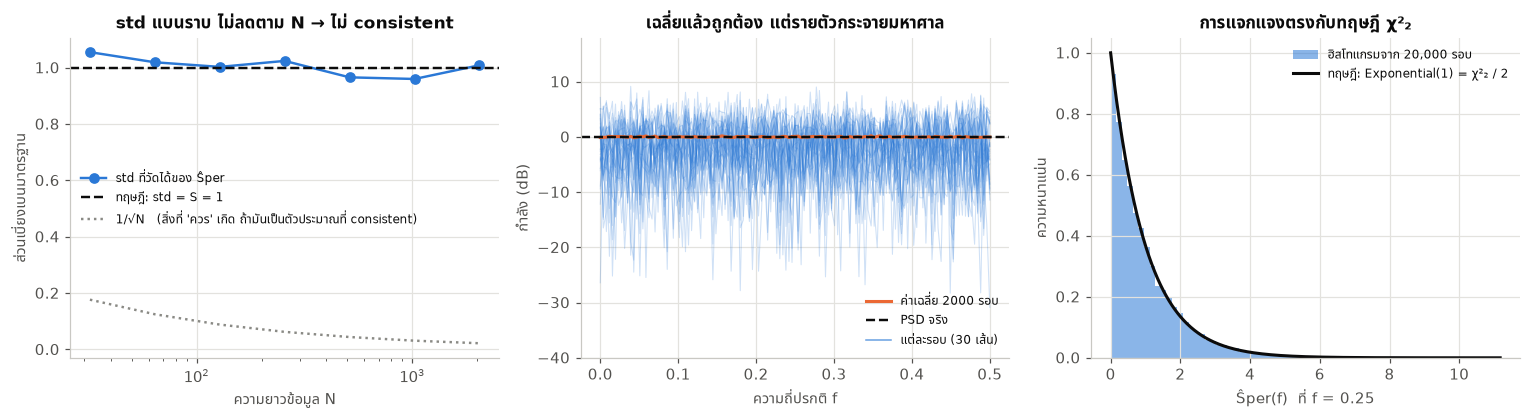

ค่าเฉลี่ยของ ensemble = 1.0198   (ทฤษฎี = 1.0)
std   ของ ensemble = 1.0207   (ทฤษฎี = 1.0)
std เมื่อคิดเป็น dB  = 5.642 dB   (ทฤษฎี = 5.57 dB)


In [11]:
# ---- variance ไม่ลดลงตาม N + การแจกแจงเป็นเอ็กซ์โพเนนเชียล ----
N_sweep = [32, 64, 128, 256, 512, 1024, 2048]
n_rep   = 4000
std_at_f, mean_at_f = [], []

for N_v in N_sweep:
    k_test = N_v // 4                                  # เลือกดูที่ f = 0.25
    vals = np.empty(n_rep)
    for i in range(n_rep):
        xv = rng.standard_normal(N_v)
        vals[i] = np.abs(np.fft.rfft(xv)[k_test])**2 / N_v
    std_at_f.append(vals.std()); mean_at_f.append(vals.mean())

# เก็บ ensemble ไว้ทำฮิสโทแกรม (ที่ N = 256)
N_h, k_h = 256, 64
samples = np.array([np.abs(np.fft.rfft(rng.standard_normal(N_h))[k_h])**2 / N_h
                    for _ in range(20000)])

fig, ax = plt.subplots(1, 3, figsize=(14, 3.9))

# (ก) variance คงที่ ขณะที่ 1/√N ดิ่งลง
ax[0].semilogx(N_sweep, std_at_f, "o-", color=C_PER, ms=6,
               label="std ที่วัดได้ของ Ŝper")
ax[0].axhline(1.0, color=C_TRUE, ls="--", lw=1.6, label="ทฤษฎี: std = S = 1")
ax[0].semilogx(N_sweep, 1/np.sqrt(N_sweep), ":", color=C_MUTE, lw=1.6,
               label="1/√N   (สิ่งที่ 'ควร' เกิด ถ้ามันเป็นตัวประมาณที่ consistent)")
ax[0].set_xlabel("ความยาวข้อมูล N"); ax[0].set_ylabel("ส่วนเบี่ยงเบนมาตรฐาน")
ax[0].set_title("std แบนราบ ไม่ลดตาม N → ไม่ consistent")
ax[0].legend(loc="center left", fontsize=8)

# (ข) ensemble spaghetti
N_e = 256
fe  = np.fft.rfftfreq(N_e)
for i in range(30):
    Pe = np.abs(np.fft.rfft(rng.standard_normal(N_e)))**2 / N_e
    ax[1].plot(fe, 10*np.log10(Pe+1e-12), color=C_PER, lw=0.7, alpha=0.22)
mean_e = np.mean([np.abs(np.fft.rfft(rng.standard_normal(N_e)))**2 / N_e
                  for _ in range(2000)], axis=0)
ax[1].plot(fe, 10*np.log10(mean_e), color=C_BAR, lw=2.0, label="ค่าเฉลี่ย 2000 รอบ")
ax[1].axhline(0, color=C_TRUE, ls="--", lw=1.6, label="PSD จริง")
ax[1].plot([], [], color=C_PER, lw=1.0, alpha=0.7, label="แต่ละรอบ (30 เส้น)")
ax[1].set_ylim(-40, 18)
ax[1].set_xlabel("ความถี่ปรกติ f"); ax[1].set_ylabel("กำลัง (dB)")
ax[1].set_title("เฉลี่ยแล้วถูกต้อง แต่รายตัวกระจายมหาศาล")
ax[1].legend(loc="lower right", fontsize=8)

# (ค) ฮิสโทแกรม vs การแจกแจงเอ็กซ์โพเนนเชียล
ax[2].hist(samples, bins=70, density=True, color=C_PER, alpha=0.55,
           edgecolor="none", label="ฮิสโทแกรมจาก 20,000 รอบ")
xx = np.linspace(0, samples.max(), 400)
ax[2].plot(xx, stats.expon.pdf(xx, scale=1.0), color=C_TRUE, lw=2.0,
           label="ทฤษฎี: Exponential(1) = χ²₂ / 2")
ax[2].set_xlabel("Ŝper(f)  ที่ f = 0.25"); ax[2].set_ylabel("ความหนาแน่น")
ax[2].set_title("การแจกแจงตรงกับทฤษฎี χ²₂")
ax[2].legend(loc="upper right", fontsize=8)

plt.tight_layout(); plt.show()

print(f"ค่าเฉลี่ยของ ensemble = {samples.mean():.4f}   (ทฤษฎี = 1.0)")
print(f"std   ของ ensemble = {samples.std():.4f}   (ทฤษฎี = 1.0)")
print(f"std เมื่อคิดเป็น dB  = {np.std(10*np.log10(samples)):.3f} dB   (ทฤษฎี = 5.57 dB)")

### สรุปส่วนที่ 4

| คุณสมบัติ | ผล | ความหมาย |
|---|---|---|
| $E\{\hat{S}\} = S \circledast W_B$ | ✔ asymptotically unbiased | เล็งถูกเป้า **ถ้า** $N$ ใหญ่พอ |
| $\operatorname{Var}\{\hat{S}\} \approx S^2$ | ✘ **ไม่ consistent** | ผิดพลาด 100% เสมอ ไม่ว่า $N$ เท่าไหร่ |
| $\hat{S}/S \sim \text{Exp}(1)$ | — | ในหน่วย dB ส่วนเบี่ยงเบน = **5.57 dB** |

ตัวเลข **5.57 dB** น่าสนใจมาก มันมาจาก
$\operatorname{std}\{10\log_{10} X\} = \frac{10}{\ln 10}\cdot\frac{\pi}{\sqrt 6} \approx 5.57$
เมื่อ $X \sim \text{Exp}(1)$ แปลว่า **ค่าที่อ่านได้จาก periodogram ดิบ
เชื่อถือได้แค่ระดับ $\pm 5.6$ dB** ซึ่งแย่มากในทางวิศวกรรม

### แล้วจะแก้อย่างไร?

สังเกตกราฟกลาง — **การเฉลี่ยได้ผล** เส้นสีส้ม (เฉลี่ย 2000 รอบ) เรียบสวยงาม
ปัญหาคือในชีวิตจริงเรามีข้อมูลชุดเดียว ไม่มี 2000 รอบให้เฉลี่ย

> **ไอเดียของ Bartlett และ Welch คือ:**
> ถ้าไม่มีหลาย realization ให้เฉลี่ย ก็ **หั่นข้อมูลชุดเดียวออกเป็นหลายท่อน
> แล้วแกล้งทำเหมือนแต่ละท่อนเป็นคนละ realization**

แต่ก่อนจะไปถึงตรงนั้น ต้องเข้าใจอีกปัญหาหนึ่งที่แยกกันคนละเรื่องก่อน คือ **leakage**

---
# ส่วนที่ 5 — Spectral Leakage, หน้าต่าง และความละเอียด

ส่วนที่ 4 พูดถึงปัญหา **variance** (หญ้าหยาบ) ส่วนนี้พูดถึงปัญหาคนละตัวคือ **bias จากการตัดข้อมูล**
ซึ่งแก้ด้วยเครื่องมือคนละอย่าง — ต้องแยกให้ออก เพราะสับสนกันบ่อยมาก

| ปัญหา | สาเหตุ | แก้ด้วย |
|---|---|---|
| **Variance** — สเปกตรัมเป็นหญ้าหยาบ | มีข้อมูลชุดเดียว ไม่ได้เฉลี่ย | **การเฉลี่ย** (Bartlett/Welch) |
| **Leakage** — พลังงานรั่วออกนอกยอด | ตัดข้อมูลด้วยหน้าต่างสี่เหลี่ยม | **การเลือกหน้าต่าง** (window) |

## 5.1 leakage เกิดขึ้นได้อย่างไร

การที่เราเก็บข้อมูลได้แค่ $N$ จุด เทียบเท่ากับการเอาสัญญาณที่ยาวไม่จบ
มาคูณด้วย **หน้าต่างสี่เหลี่ยม (rectangular window)**:

$$x_{N}[n] \;=\; x[n]\cdot w_{R}[n], \qquad
w_{R}[n] = \begin{cases} 1 & 0 \le n \le N-1 \\ 0 & \text{อื่น ๆ}\end{cases}$$

คูณในเวลา = คอนโวลูชันในความถี่ ดังนั้นสเปกตรัมที่ได้คือ $X(f) \circledast W_R(f)$
โดยที่ $W_R(f)$ คือ **Dirichlet kernel**:

$$W_{R}(f) \;=\; \frac{\sin(\pi f N)}{\sin(\pi f)}\, e^{-j\pi f (N-1)}$$

- **โลบหลัก** กว้าง $2/N$ → ไซน์ที่ควรเป็นเส้นบาง ๆ กลายเป็นยอดกว้าง → **จำกัด resolution**
- **โลบข้าง** ตัวแรกสูงถึง $-13.3$ dB และลดลงช้ามาก (แค่ 6 dB ต่อ octave)
  → พลังงานจากยอดใหญ่ **รั่ว (leak)** ไปกลบยอดเล็กที่อยู่ห่างออกไป

*(หมายเหตุความสัมพันธ์: $W_B = |W_R|^2/N$ — Fejér kernel ในส่วนที่ 4 คือกำลังสองของ Dirichlet kernel นี่เอง
จึงเป็นเหตุผลว่าทำไม Fejér ถึงไม่ติดลบ)*

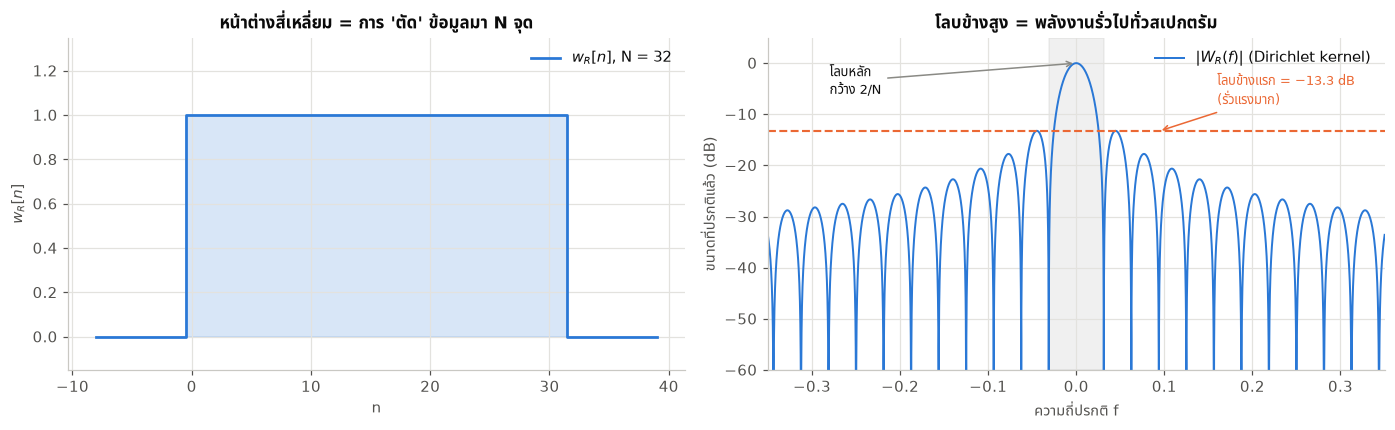

N = 32: ความกว้างโลบหลัก (null-to-null) = 2/N = 0.0625
โลบข้างของหน้าต่างสี่เหลี่ยมลดลงแค่ 6 dB/octave — ช้ามาก


In [12]:
# ---- กายวิภาคของหน้าต่างสี่เหลี่ยม ----
N_w  = 32
f_w  = np.linspace(-0.5, 0.5, 8001)
W_R  = np.abs(np.sin(np.pi*f_w*N_w) / np.where(np.abs(np.sin(np.pi*f_w))<1e-12,
                                               1e-12, np.sin(np.pi*f_w)))
W_R[np.abs(f_w) < 1e-9] = N_w
W_dB = 20*np.log10(W_R/W_R.max() + 1e-16)

fig, ax = plt.subplots(1, 2, figsize=(12.8, 4.0))

ax[0].step(np.arange(-8, N_w+8), np.where((np.arange(-8, N_w+8)>=0) &
           (np.arange(-8, N_w+8)<N_w), 1, 0), where="mid", color=C_PER, lw=1.8,
           label=f"$w_R[n]$, N = {N_w}")
ax[0].fill_between(np.arange(-8, N_w+8),
                   np.where((np.arange(-8, N_w+8)>=0) & (np.arange(-8, N_w+8)<N_w), 1, 0),
                   step="mid", color=C_PER, alpha=0.18)
ax[0].set_ylim(-0.15, 1.35); ax[0].set_xlabel("n"); ax[0].set_ylabel("$w_R[n]$")
ax[0].set_title("หน้าต่างสี่เหลี่ยม = การ 'ตัด' ข้อมูลมา N จุด")
ax[0].legend(loc="upper right")

ax[1].plot(f_w, W_dB, color=C_PER, lw=1.3, label="$|W_R(f)|$ (Dirichlet kernel)")
ax[1].axhline(-13.3, color=C_BAR, ls="--", lw=1.4)
ax[1].annotate("โลบข้างแรก = −13.3 dB\n(รั่วแรงมาก)", xy=(3/N_w, -13.3),
               xytext=(0.16, -8), color=C_BAR, fontsize=8.5,
               arrowprops=dict(arrowstyle="->", color=C_BAR, lw=1))
ax[1].annotate("โลบหลัก\nกว้าง 2/N", xy=(0, 0), xytext=(-0.28, -6),
               color=C_TRUE, fontsize=8.5,
               arrowprops=dict(arrowstyle="->", color=C_MUTE, lw=1))
ax[1].axvspan(-1/N_w, 1/N_w, color=C_MUTE, alpha=0.12)
ax[1].set_xlim(-0.35, 0.35); ax[1].set_ylim(-60, 5)
ax[1].set_xlabel("ความถี่ปรกติ f"); ax[1].set_ylabel("ขนาดที่ปรกติแล้ว (dB)")
ax[1].set_title("โลบข้างสูง = พลังงานรั่วไปทั่วสเปกตรัม")
ax[1].legend(loc="upper right")

plt.tight_layout(); plt.show()

print(f"N = {N_w}: ความกว้างโลบหลัก (null-to-null) = 2/N = {2/N_w:.4f}")
print("โลบข้างของหน้าต่างสี่เหลี่ยมลดลงแค่ 6 dB/octave — ช้ามาก")

## 5.2 leakage ทำให้ "มองไม่เห็น" สัญญาณจริง

นี่คือการทดลองที่แสดงผลเสียของ leakage ได้ชัดที่สุด:

สัญญาณมีไซน์สองตัว ตัวหนึ่งแรงที่ $f_1 = 0.20$ อีกตัว **อ่อนกว่า 60 dB**
วางไว้ห่างออกไปเพียง 8 bin ($f_2 = f_1 + 8/N$)

ไซน์ตัวที่สองมีอยู่จริงและ *แยกจากตัวแรกได้สบาย ๆ* ในแง่ resolution
(ห่างตั้ง 8 bin ขณะที่โลบหลักกว้างแค่ 2 bin) แต่มันจะถูก **leakage** จากตัวแรกกลบจนมองไม่เห็น
ซึ่งเป็นคนละปัญหากับ resolution

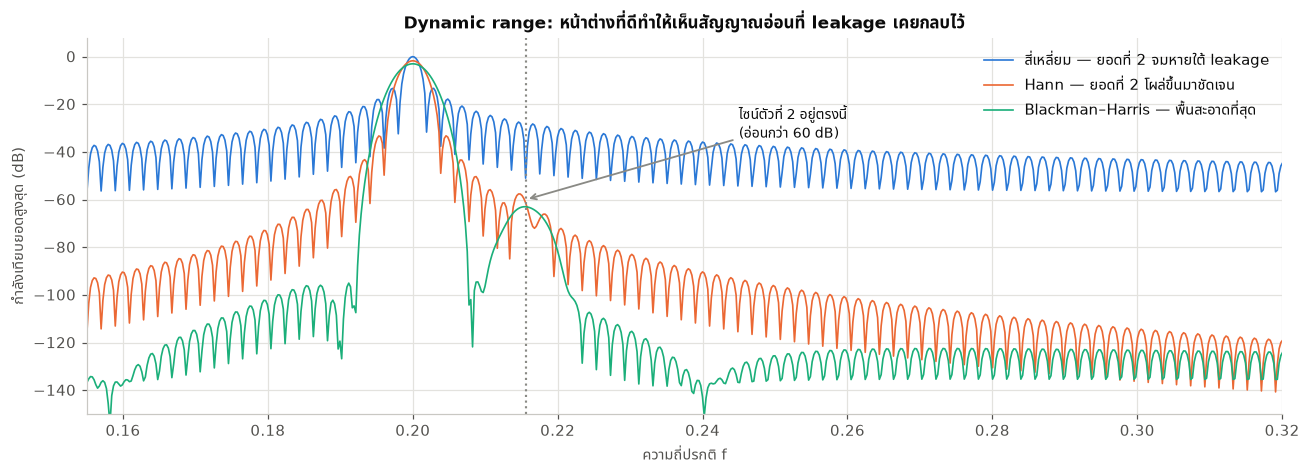

      สี่เหลี่ยม: ยอดที่ 2 =   -51.0 dB | พื้น leakage =    -41.0 dB | เด่นกว่าพื้น  -10.0 dB  → มองไม่เห็น
            Hann: ยอดที่ 2 =   -61.3 dB | พื้น leakage =   -101.5 dB | เด่นกว่าพื้น   40.2 dB  → เห็นได้
 Blackman–Harris: ยอดที่ 2 =   -63.0 dB | พื้น leakage =   -127.7 dB | เด่นกว่าพื้น   64.7 dB  → เห็นได้


In [13]:
# ---- leakage กลบสัญญาณอ่อน ----
N_lk = 512
n_lk = np.arange(N_lk)
f1_lk  = 0.20
f2_lk  = f1_lk + 8/N_lk                 # ห่างออกไป 8 bin — ไกลเกินพอในแง่ resolution
A2 = 10**(-60/20)                       # อ่อนกว่า 60 dB
x_lk = np.sin(2*np.pi*f1_lk*n_lk) + A2*np.sin(2*np.pi*f2_lk*n_lk)

NFFT_lk = 4096
f_lk = np.fft.rfftfreq(NFFT_lk)

def per_win(x, w, NFFT):
    """periodogram ที่ใช้หน้าต่าง w พร้อม normalize กำลัง (U = mean(w²))"""
    U = np.mean(w**2)
    return np.abs(np.fft.rfft(x*w, NFFT))**2 / (len(x)*U)

P_rect = per_win(x_lk, np.ones(N_lk),                 NFFT_lk)
P_hann = per_win(x_lk, sig.windows.hann(N_lk, sym=False), NFFT_lk)
P_blk  = per_win(x_lk, sig.windows.blackmanharris(N_lk, sym=False), NFFT_lk)

ref = P_rect.max()
fig, ax = plt.subplots(figsize=(12, 4.4))
ax.plot(f_lk, 10*np.log10(P_rect/ref + 1e-20), color=C_PER, lw=1.1,
        label="สี่เหลี่ยม — ยอดที่ 2 จมหายใต้ leakage")
ax.plot(f_lk, 10*np.log10(P_hann/ref + 1e-20), color=C_BAR, lw=1.1,
        label="Hann — ยอดที่ 2 โผล่ขึ้นมาชัดเจน")
ax.plot(f_lk, 10*np.log10(P_blk/ref  + 1e-20), color=C_WEL, lw=1.1,
        label="Blackman–Harris — พื้นสะอาดที่สุด")
ax.axvline(f2_lk, color=C_MUTE, ls=":", lw=1.4)
ax.annotate("ไซน์ตัวที่ 2 อยู่ตรงนี้\n(อ่อนกว่า 60 dB)", xy=(f2_lk, -60),
            xytext=(0.245, -34), color=C_TRUE, fontsize=9,
            arrowprops=dict(arrowstyle="->", color=C_MUTE, lw=1.2))
ax.set_xlim(0.155, 0.32); ax.set_ylim(-150, 8)
ax.set_xlabel("ความถี่ปรกติ f"); ax.set_ylabel("กำลังเทียบยอดสูงสุด (dB)")
ax.set_title("Dynamic range: หน้าต่างที่ดีทำให้เห็นสัญญาณอ่อนที่ leakage เคยกลบไว้")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

# วัดว่าแต่ละหน้าต่าง "เห็น" ยอดที่สองสูงกว่าพื้น leakage ข้างเคียงเท่าไร
# (ยอดจะ "เห็น" ได้ ก็ต่อเมื่อมันโผล่พ้นพื้น leakage รอบ ๆ ตัวมันเอง)
near = (f_lk > f2_lk + 0.01) & (f_lk < f2_lk + 0.06)
for nm, P in [("สี่เหลี่ยม", P_rect), ("Hann", P_hann), ("Blackman–Harris", P_blk)]:
    k2   = np.argmin(np.abs(f_lk - f2_lk))
    peak = 10*np.log10(P[k2]/ref)
    side = 10*np.log10(np.median(P[near])/ref)
    verdict = "มองไม่เห็น" if peak - side < 6 else "เห็นได้"
    print(f"{nm:>16s}: ยอดที่ 2 = {peak:7.1f} dB | พื้น leakage = {side:8.1f} dB "
          f"| เด่นกว่าพื้น {peak-side:6.1f} dB  → {verdict}")

ตัวเลขเล่าเรื่องได้ชัด: ด้วยหน้าต่างสี่เหลี่ยม ยอดที่สอง **อยู่ต่ำกว่า**
พื้น leakage รอบตัวมันเสียอีก (ค่าติดลบ) — มองไม่เห็นเลยแม้จะรู้ว่ามันอยู่ตรงไหน
พอเปลี่ยนเป็น Hann มันโผล่ขึ้นมาราว 40 dB เหนือพื้น และ Blackman–Harris ให้พื้นที่สะอาดที่สุด

**ข้อมูลชุดเดียวกันเป๊ะ ๆ ต่างกันแค่หน้าต่างที่คูณเข้าไป**

ย้ำอีกครั้งว่านี่ **ไม่ใช่** ปัญหา resolution — ยอดทั้งสองห่างกันตั้ง 8 bin
ขณะที่โลบหลักกว้างแค่ 2 bin การเพิ่ม $N$ หรือเติมศูนย์จึงไม่ช่วยอะไรเลย
ปัญหาอยู่ที่ *โลบข้าง* ล้วน ๆ ซึ่งแก้ได้ด้วยการเปลี่ยนหน้าต่างเท่านั้น

## 5.3 การแลกเปลี่ยน: resolution ↔ dynamic range

หน้าต่างที่ดีไม่ได้ดีฟรี ๆ กฎเหล็กคือ:

$$\text{โลบข้างต่ำ (dynamic range ดี)} \;\Longleftrightarrow\; \text{โลบหลักกว้าง (resolution แย่)}$$

เพราะการกดโลบข้างทำได้ด้วยการทำให้หน้าต่าง "นุ่ม" ขึ้นที่ขอบ ซึ่งเท่ากับ
ลดความยาวใช้งานจริงของข้อมูลลง

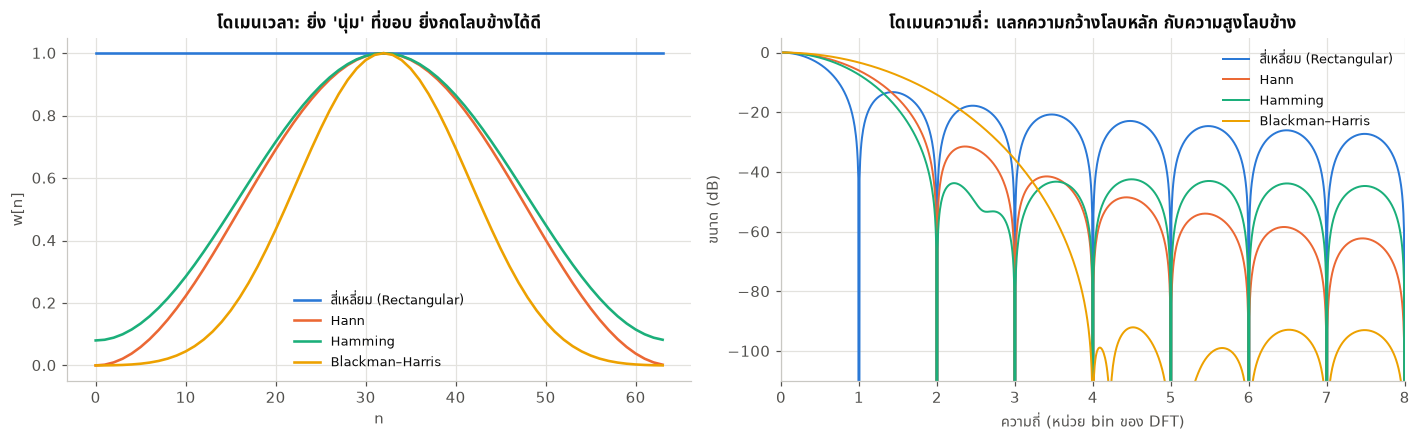

หน้าต่าง                    โลบข้างสูงสุด   ความกว้าง −3dB     ENBW
--------------------------------------------------------------------
สี่เหลี่ยม (Rectangular)         -13.3 dB          0.89 bin   1.000
Hann                             -31.5 dB          1.44 bin   1.500
Hamming                          -42.4 dB          1.30 bin   1.363
Blackman–Harris                  -92.0 dB          1.91 bin   2.004

อ่านตาราง: ลงล่าง = โลบข้างต่ำลง (ดีขึ้น) แต่โลบหลักกว้างขึ้น (แย่ลง)


In [14]:
# ---- เปรียบเทียบหน้าต่างมาตรฐาน 4 แบบ ----
L_w   = 64
wins  = {
    "สี่เหลี่ยม (Rectangular)": (np.ones(L_w),                              C_PER),
    "Hann":                     (sig.windows.hann(L_w, sym=False),          C_BAR),
    "Hamming":                  (sig.windows.hamming(L_w, sym=False),       C_WEL),
    "Blackman–Harris":          (sig.windows.blackmanharris(L_w, sym=False), C_ALT),
}
NF_w = 8192

fig, ax = plt.subplots(1, 2, figsize=(13, 4.1))
rows = []
for nm, (w, col) in wins.items():
    ax[0].plot(np.arange(L_w), w, color=col, lw=1.7, label=nm)

    W  = np.abs(np.fft.rfft(w, NF_w)); W /= W.max()
    fW = np.fft.rfftfreq(NF_w)*L_w                 # แกนเป็นหน่วย "bin"
    ax[1].plot(fW, 20*np.log10(W + 1e-20), color=col, lw=1.3, label=nm)

    # วัดสมบัติเชิงตัวเลข
    WdB   = 20*np.log10(W + 1e-20)
    mn    = np.where(np.diff(np.sign(np.diff(WdB))) > 0)[0]      # ตำแหน่ง null แรก
    first = mn[0] if len(mn) else 0
    psl   = WdB[first:].max()                                     # โลบข้างสูงสุด
    hpbw  = 2*fW[np.argmin(np.abs(WdB[:200] + 3.01))]             # ความกว้าง -3 dB
    enbw  = L_w*np.sum(w**2)/np.sum(w)**2                         # ENBW (bins)
    rows.append((nm, psl, hpbw, enbw))

ax[0].set_xlabel("n"); ax[0].set_ylabel("w[n]")
ax[0].set_title("โดเมนเวลา: ยิ่ง 'นุ่ม' ที่ขอบ ยิ่งกดโลบข้างได้ดี")
ax[0].legend(loc="lower center", fontsize=8.5)

ax[1].set_xlim(0, 8); ax[1].set_ylim(-110, 5)
ax[1].set_xlabel("ความถี่ (หน่วย bin ของ DFT)"); ax[1].set_ylabel("ขนาด (dB)")
ax[1].set_title("โดเมนความถี่: แลกความกว้างโลบหลัก กับความสูงโลบข้าง")
ax[1].legend(loc="upper right", fontsize=8.5)
plt.tight_layout(); plt.show()

print(f"{'หน้าต่าง':<26s} {'โลบข้างสูงสุด':>14s} {'ความกว้าง −3dB':>16s} {'ENBW':>8s}")
print("-"*68)
for nm, psl, hpbw, enbw in rows:
    print(f"{nm:<26s} {psl:>11.1f} dB {hpbw:>13.2f} bin {enbw:>7.3f}")
print("\nอ่านตาราง: ลงล่าง = โลบข้างต่ำลง (ดีขึ้น) แต่โลบหลักกว้างขึ้น (แย่ลง)")

ตารางสรุปการแลกเปลี่ยนชัดเจน: จากสี่เหลี่ยมลงไป Blackman–Harris
โลบข้างดีขึ้นจาก $-13$ dB เป็น $-92$ dB **แต่** โลบหลักกว้างขึ้นเกือบ 4 เท่า

**ENBW** (Equivalent Noise Bandwidth) คือตัวเลขสรุปว่าหน้าต่างทำให้ resolution แย่ลงกี่เท่า

### แล้วต้องเลือกยังไง?

| สถานการณ์ | เลือก |
|---|---|
| ต้องแยกยอดสองยอดที่ **ใกล้กันมากและสูงพอ ๆ กัน** | สี่เหลี่ยม (โลบหลักแคบสุด) |
| ต้องหาสัญญาณ **อ่อนมาก** ที่อยู่ใกล้สัญญาณแรง | Blackman–Harris (โลบข้างต่ำสุด) |
| **ทั่วไป ไม่รู้จะเลือกอะไร** | **Hann** — สมดุลดี เป็นค่าตั้งต้นของ Welch |

ลองดูอีกด้านของเหรียญ — กรณีที่สี่เหลี่ยม *ชนะ*

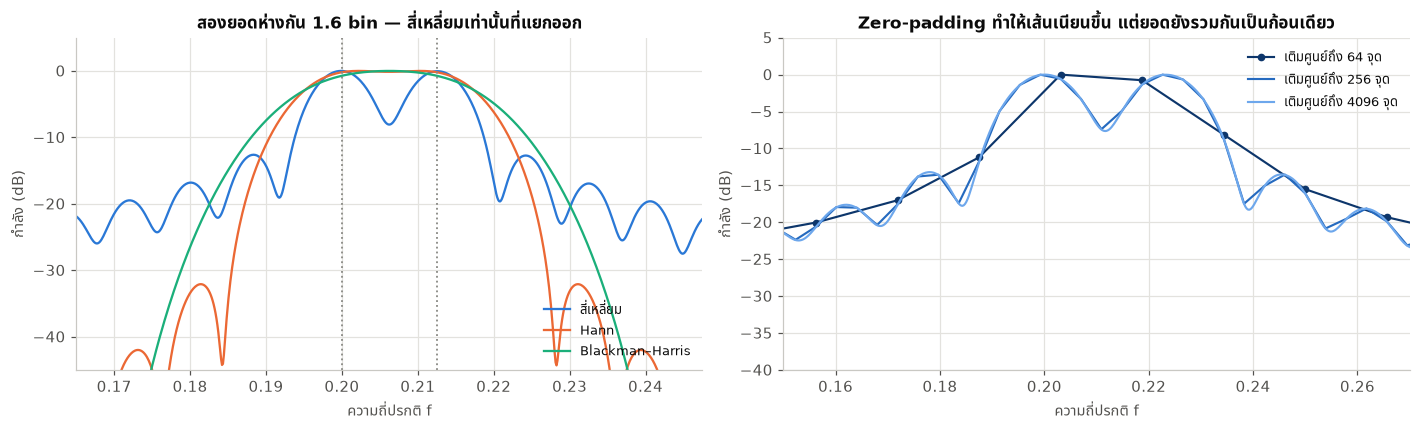

บทเรียนสำคัญสองข้อ:
  1. ไม่มีหน้าต่างไหน 'ดีที่สุด' — ขึ้นกับว่าโจทย์ต้องการ resolution หรือ dynamic range
  2. Zero-padding = การแทรกค่า (interpolation) ไม่ได้เพิ่มข้อมูลใหม่
     → resolution ที่แท้จริงถูกกำหนดโดยความยาวข้อมูล N เท่านั้น (Δf ≈ 1/N)


In [15]:
# ---- อีกด้านของเหรียญ: สองยอดใกล้กัน แรงพอกัน → สี่เหลี่ยมชนะ ----
N_r  = 128
n_r  = np.arange(N_r)
df   = 1.6/N_r                          # ห่างกัน 1.6 bin — ใกล้มาก
fa, fb_ = 0.20, 0.20 + df
x_r  = np.sin(2*np.pi*fa*n_r) + np.sin(2*np.pi*fb_*n_r)

NF_r = 8192
f_r  = np.fft.rfftfreq(NF_r)
P_r_rect = per_win(x_r, np.ones(N_r),                              NF_r)
P_r_hann = per_win(x_r, sig.windows.hann(N_r, sym=False),          NF_r)
P_r_blk  = per_win(x_r, sig.windows.blackmanharris(N_r, sym=False), NF_r)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.0))

for P, col, nm in [(P_r_rect, C_PER, "สี่เหลี่ยม"), (P_r_hann, C_BAR, "Hann"),
                   (P_r_blk, C_WEL, "Blackman–Harris")]:
    ax[0].plot(f_r, 10*np.log10(P/P.max()+1e-20), color=col, lw=1.5, label=nm)
ax[0].axvline(fa,  color=C_MUTE, ls=":", lw=1.2)
ax[0].axvline(fb_, color=C_MUTE, ls=":", lw=1.2)
ax[0].set_xlim(fa-0.035, fb_+0.035); ax[0].set_ylim(-45, 5)
ax[0].set_xlabel("ความถี่ปรกติ f"); ax[0].set_ylabel("กำลัง (dB)")
ax[0].set_title(f"สองยอดห่างกัน {df*N_r:.1f} bin — สี่เหลี่ยมเท่านั้นที่แยกออก")
ax[0].legend(loc="lower right", fontsize=8.5)

# zero-padding ไม่ช่วยเรื่อง resolution
N_z = 64
n_z = np.arange(N_z)
x_z = np.sin(2*np.pi*0.20*n_z) + np.sin(2*np.pi*(0.20+1.5/N_z)*n_z)
for NFz, col, sty in [(N_z, BLUES[6], "-o"), (256, BLUES[4], "-"), (4096, BLUES[2], "-")]:
    Pz = np.abs(np.fft.rfft(x_z, NFz))**2 / N_z
    fz = np.fft.rfftfreq(NFz)
    ax[1].plot(fz, 10*np.log10(Pz/Pz.max()+1e-20), sty, color=col, lw=1.4, ms=4,
               label=f"เติมศูนย์ถึง {NFz} จุด")
ax[1].set_xlim(0.15, 0.27); ax[1].set_ylim(-40, 5)
ax[1].set_xlabel("ความถี่ปรกติ f"); ax[1].set_ylabel("กำลัง (dB)")
ax[1].set_title("Zero-padding ทำให้เส้นเนียนขึ้น แต่ยอดยังรวมกันเป็นก้อนเดียว")
ax[1].legend(loc="upper right", fontsize=8.5)

plt.tight_layout(); plt.show()

print("บทเรียนสำคัญสองข้อ:")
print("  1. ไม่มีหน้าต่างไหน 'ดีที่สุด' — ขึ้นกับว่าโจทย์ต้องการ resolution หรือ dynamic range")
print("  2. Zero-padding = การแทรกค่า (interpolation) ไม่ได้เพิ่มข้อมูลใหม่")
print("     → resolution ที่แท้จริงถูกกำหนดโดยความยาวข้อมูล N เท่านั้น (Δf ≈ 1/N)")

กราฟขวาคือความเข้าใจผิดที่พบบ่อยที่สุดในการประมวลผลสัญญาณ:
**การเติมศูนย์ไม่ได้เพิ่มความละเอียด** มันแค่วาดเส้นเดิมด้วยจุดที่ถี่ขึ้น
ยอดสองยอดที่รวมเป็นก้อนเดียวก็ยังรวมกันอยู่เหมือนเดิม

$$\text{resolution จริง} \approx \frac{1}{N} \quad(\text{กำหนดโดยความยาวข้อมูล})
\qquad\ne\qquad
\text{ระยะห่างจุดความถี่} = \frac{1}{N_{\text{FFT}}}$$

---
# ส่วนที่ 6 — Bartlett's Method (Averaged Periodogram)

## 6.1 แนวคิด

ย้อนกลับไปที่ปัญหาหลักในส่วนที่ 4: เราต้องการ $E\{\cdot\}$ แต่มีข้อมูลชุดเดียว

**M. S. Bartlett (ค.ศ. 1948)** เสนอทางออกที่ตรงไปตรงมา:

> หั่นข้อมูล $N$ จุด ออกเป็น $K$ ท่อน ท่อนละ $L = N/K$ จุด **ที่ไม่ทับกัน**
> คำนวณ periodogram ของแต่ละท่อน แล้ว **เฉลี่ยกัน**

$$\boxed{\;\hat{S}_{B}(f) \;=\; \frac{1}{K}\sum_{i=0}^{K-1} \hat{S}^{(i)}(f),
\qquad
\hat{S}^{(i)}(f) = \frac{1}{L}\left|\sum_{n=0}^{L-1} x[iL+n]\,e^{-j2\pi f n}\right|^{2}\;}$$

เหตุผลที่ใช้ได้: ถ้าข้อมูลห่างกันเกินความยาวสหสัมพันธ์ (correlation length)
ท่อนต่าง ๆ จะเกือบเป็นอิสระต่อกัน — จึงเหมือนได้ $K$ realization มาเฉลี่ยจริง ๆ

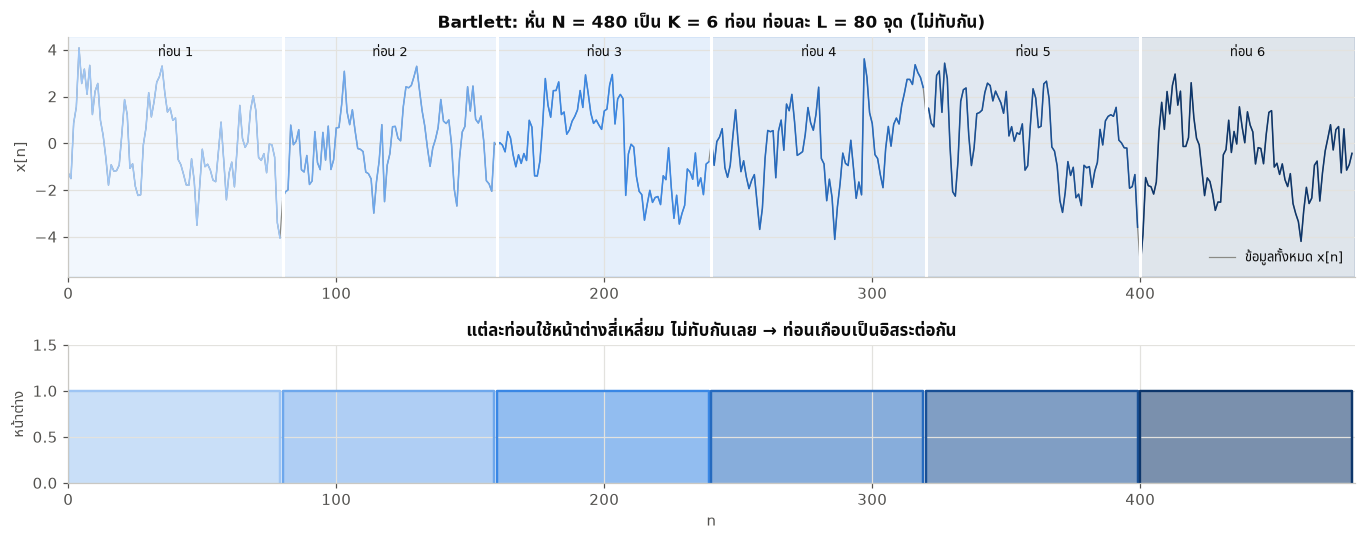

ข้อมูล 480 จุด → 6 ท่อน × 80 จุด
resolution เปลี่ยนจาก 1/N = 0.00208 เป็น 1/L = 0.01250 (แย่ลง 6 เท่า)


In [16]:
# ---- แผนภาพ: Bartlett หั่นข้อมูลอย่างไร ----
N_diag, K_diag = 480, 6
L_diag = N_diag // K_diag
x_diag = sig.lfilter([1.0], [1.0, -0.75], rng.standard_normal(N_diag+200))[200:]

fig, ax = plt.subplots(2, 1, figsize=(12.5, 5.0),
                       gridspec_kw={"height_ratios": [2, 1.15]})

ax[0].plot(np.arange(N_diag), x_diag, color=C_MUTE, lw=0.8, label="ข้อมูลทั้งหมด x[n]")
seg_cols = [BLUES[i % len(BLUES)] for i in [1,2,3,4,5,6]]
for i in range(K_diag):
    s, e = i*L_diag, (i+1)*L_diag
    ax[0].plot(np.arange(s, e), x_diag[s:e], color=seg_cols[i], lw=1.0)
    ax[0].axvspan(s, e, color=seg_cols[i], alpha=0.13)
    ax[0].text((s+e)/2, ax[0].get_ylim()[1]*0.82, f"ท่อน {i+1}",
               ha="center", fontsize=8.5, color=C_TRUE)
for b in range(1, K_diag):
    ax[0].axvline(b*L_diag, color="white", lw=2.0)
ax[0].set_xlim(0, N_diag); ax[0].set_ylabel("x[n]")
ax[0].set_title(f"Bartlett: หั่น N = {N_diag} เป็น K = {K_diag} ท่อน ท่อนละ L = {L_diag} จุด (ไม่ทับกัน)")
ax[0].legend(loc="lower right", fontsize=8.5)

# แสดงหน้าต่างสี่เหลี่ยมของแต่ละท่อน
for i in range(K_diag):
    s = i*L_diag
    ax[1].fill_between([s, s+L_diag-1], 0, 1, color=seg_cols[i], alpha=0.55,
                       step="pre", lw=0)
    ax[1].plot([s, s, s+L_diag-1, s+L_diag-1], [0, 1, 1, 0], color=seg_cols[i], lw=1.6)
ax[1].set_xlim(0, N_diag); ax[1].set_ylim(0, 1.5)
ax[1].set_xlabel("n"); ax[1].set_ylabel("หน้าต่าง")
ax[1].set_title("แต่ละท่อนใช้หน้าต่างสี่เหลี่ยม ไม่ทับกันเลย → ท่อนเกือบเป็นอิสระต่อกัน")

plt.tight_layout(); plt.show()
print(f"ข้อมูล {N_diag} จุด → {K_diag} ท่อน × {L_diag} จุด")
print(f"resolution เปลี่ยนจาก 1/N = {1/N_diag:.5f} เป็น 1/L = {1/L_diag:.5f} (แย่ลง {K_diag} เท่า)")

## 6.2 พิสูจน์: variance ลดลง $K$ เท่า

**สมมติฐาน:** ท่อนทั้ง $K$ ท่อนเป็นอิสระทางสถิติต่อกัน (จริงโดยประมาณ ถ้า $L$
ยาวกว่าความยาวสหสัมพันธ์ของกระบวนการมาก ๆ)

ใช้สมบัติของความแปรปรวนของผลรวมตัวแปรสุ่มอิสระ:

$$\operatorname{Var}\{\hat{S}_{B}(f)\}
= \operatorname{Var}\left\{\frac{1}{K}\sum_{i=0}^{K-1}\hat{S}^{(i)}(f)\right\}
\overset{\text{อิสระ}}{=} \frac{1}{K^{2}}\sum_{i=0}^{K-1}\operatorname{Var}\{\hat{S}^{(i)}(f)\}$$

แต่ละท่อนเป็น periodogram ธรรมดา จึงมี $\operatorname{Var}\{\hat{S}^{(i)}\} \approx S^2(f)$
(ผลจากส่วนที่ 4) ดังนั้น

$$\operatorname{Var}\{\hat{S}_{B}(f)\} = \frac{1}{K^{2}}\cdot K\cdot S^{2}(f)
\;=\; \boxed{\;\frac{S^{2}(f)}{K}\;} \qquad \blacksquare$$

**ในที่สุดก็ได้ตัวประมาณที่ consistent!** ถ้าให้ $K \to \infty$ พร้อมกับ $N \to \infty$
(โดยที่ $L = N/K \to \infty$ ด้วย) จะได้ variance $\to 0$

### แต่มีราคาที่ต้องจ่าย

ค่าคาดหวังของ Bartlett ใช้ Fejér kernel ที่ยาว $L$ **ไม่ใช่ $N$**:

$$E\{\hat{S}_{B}(f)\} = S(f) \circledast W_{B}^{(L)}(f), \qquad
\text{ความกว้างโลบหลัก} \approx \frac{2}{L} = \frac{2K}{N}$$

$$\boxed{\;\text{variance} \;\downarrow\; K \text{ เท่า} \qquad\text{แลกกับ}\qquad
\text{resolution} \;\uparrow\; K \text{ เท่า (แย่ลง)}\;}$$

นี่คือ **การแลกเปลี่ยนพื้นฐานของการประมาณสเปกตรัม** ที่หนีไม่พ้น

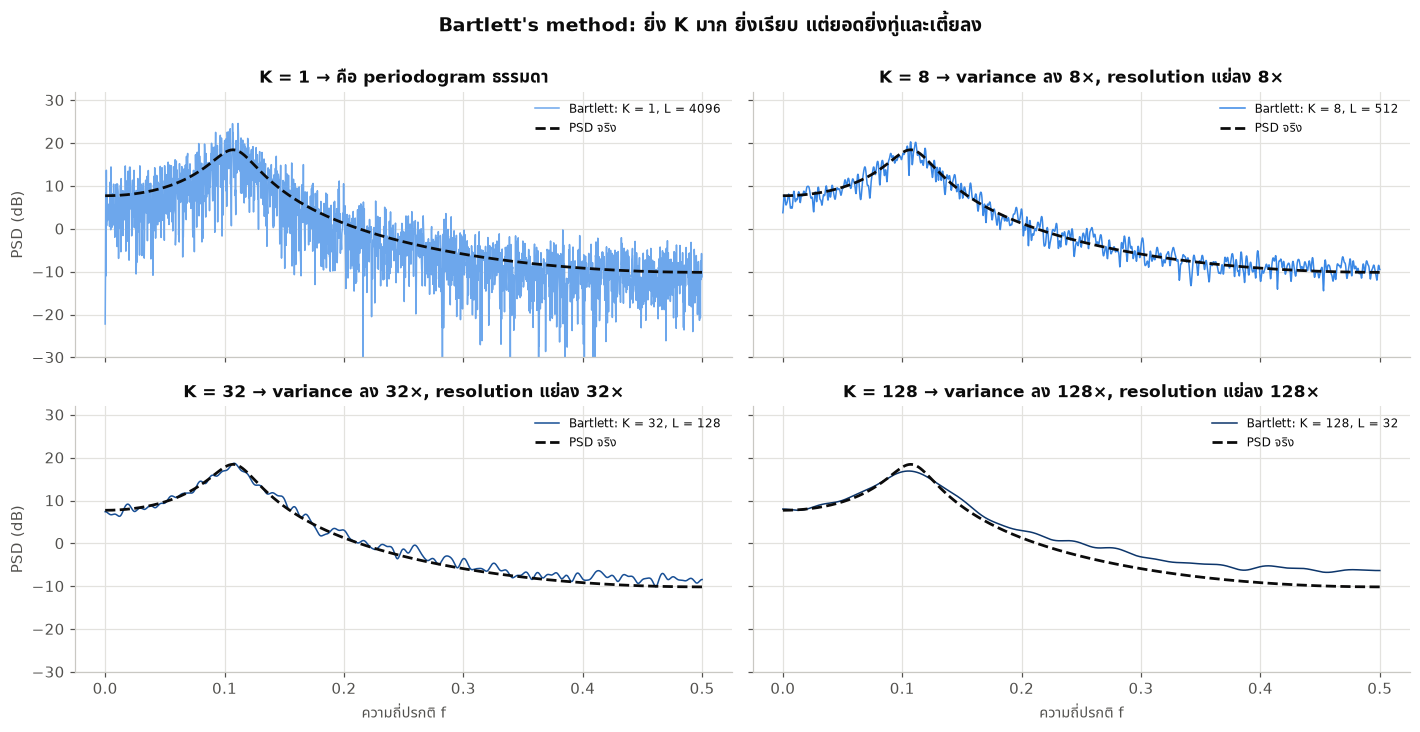

    K      L    ความสูงยอด (dB)    std ที่พื้นเรียบ (dB)
------------------------------------------------------------
    1   4096           24.61                  5.34
    8    512           20.31                  1.71
   32    128           18.72                  0.96
  128     32           16.90                  0.72

ความสูงยอดจริง = 18.46 dB
→ K มาก: เส้นเรียบขึ้นมาก (std ลดลง) แต่ยอดถูกกดเตี้ยลงเรื่อย ๆ (bias เพิ่ม)


In [17]:
# ---- ลงมือทำ Bartlett ----
def bartlett_psd(x, L, NFFT=None):
    """
    Bartlett: หั่น x เป็นท่อนยาว L ที่ไม่ทับกัน แล้วเฉลี่ย periodogram
    คืนค่า (freq, PSD) แบบด้านเดียว, fs = 1
    """
    NFFT = NFFT or L
    # กันพลาด: np.fft.rfft(seg, NFFT) ถ้า NFFT < L มันจะ "ตัด" ข้อมูลทิ้งเงียบ ๆ
    # (ไม่ใช่เติมศูนย์) ซึ่งทำให้ผลลัพธ์ผิดโดยไม่มีสัญญาณเตือน
    if NFFT < L:
        raise ValueError(f"ต้องมี NFFT >= L (ได้ NFFT={NFFT}, L={L}) "
                         "มิฉะนั้น rfft จะตัดข้อมูลทิ้งแทนที่จะเติมศูนย์")
    K = len(x) // L                       # ทิ้งเศษที่ไม่ครบท่อน
    if K == 0:
        raise ValueError("ข้อมูลสั้นกว่าความยาวท่อน")
    segs = x[:K*L].reshape(K, L)
    P = np.abs(np.fft.rfft(segs, NFFT, axis=1))**2 / L
    return np.fft.rfftfreq(NFFT), P.mean(axis=0), K

# กระบวนการทดสอบ: AR(2) ที่มียอดแหลม
a_test = np.array([1.0, -1.40, 0.81])
N_test = 4096
x_test = sig.lfilter([1.0], a_test, rng.standard_normal(N_test+1000))[1000:]
NF_bt   = 4096          # ต้อง >= L ที่ใหญ่สุด (K=1 → L=4096) ไม่งั้นข้อมูลถูกตัด
f_t     = np.fft.rfftfreq(NF_bt)                      # ตะแกรงเดียวกับที่ใช้วาด
_, H_t  = sig.freqz([1.0], a_test, worN=f_t, fs=1.0)
S_t     = np.abs(H_t)**2

fig, axes = plt.subplots(2, 2, figsize=(13, 6.6), sharex=True, sharey=True)
for axk, K_v, col in zip(axes.ravel(), [1, 8, 32, 128],
                         [BLUES[2], BLUES[3], BLUES[5], BLUES[6]]):
    L_v = N_test // K_v
    fB, PB, Kact = bartlett_psd(x_test, L_v, NFFT=NF_bt)
    axk.plot(fB, 10*np.log10(PB+1e-12), color=col, lw=1.0,
             label=f"Bartlett: K = {Kact}, L = {L_v}")
    axk.plot(f_t, 10*np.log10(S_t), "--", color=C_TRUE, lw=1.8, label="PSD จริง")
    ttl = "K = 1 → คือ periodogram ธรรมดา" if K_v == 1 else \
          f"K = {K_v} → variance ลง {K_v}×, resolution แย่ลง {K_v}×"
    axk.set_title(ttl); axk.set_ylim(-30, 32)
    axk.legend(loc="upper right", fontsize=8)
axes[1,0].set_xlabel("ความถี่ปรกติ f"); axes[1,1].set_xlabel("ความถี่ปรกติ f")
axes[0,0].set_ylabel("PSD (dB)");       axes[1,0].set_ylabel("PSD (dB)")
fig.suptitle("Bartlett's method: ยิ่ง K มาก ยิ่งเรียบ แต่ยอดยิ่งทู่และเตี้ยลง",
             fontsize=12.5, fontweight="bold", y=1.00)
plt.tight_layout(); plt.show()

print(f"{'K':>5s} {'L':>6s} {'ความสูงยอด (dB)':>18s} {'std ที่พื้นเรียบ (dB)':>24s}")
print("-"*60)
for K_v in [1, 8, 32, 128]:
    L_v = N_test // K_v
    fB, PB, _ = bartlett_psd(x_test, L_v, NFFT=NF_bt)
    flat = (fB > 0.32) & (fB < 0.48)
    print(f"{K_v:>5d} {L_v:>6d} {10*np.log10(PB.max()):>15.2f} "
          f"{np.std(10*np.log10(PB[flat])):>21.2f}")
print(f"\nความสูงยอดจริง = {10*np.log10(S_t.max()):.2f} dB")
print("→ K มาก: เส้นเรียบขึ้นมาก (std ลดลง) แต่ยอดถูกกดเตี้ยลงเรื่อย ๆ (bias เพิ่ม)")

กราฟชุดนี้แสดงการแลกเปลี่ยนได้ครบถ้วน — ไล่จาก $K=1$ (periodogram ดิบ หญ้ารก)
ไปจนถึง $K=128$ (เรียบมาก แต่ยอดแหลมถูกกดจนแทบเป็นเนินเตี้ย ๆ)

ตัวเลขที่พิมพ์ออกมายืนยันทั้งสองด้าน: `std` ลดลงเรื่อย ๆ (ดีขึ้น)
ขณะที่ `ความสูงยอด` ก็ต่ำลงเรื่อย ๆ ห่างจากค่าจริง (แย่ลง)

มาตรวจสอบสูตร $\operatorname{Var} = S^2/K$ ด้วย Monte Carlo

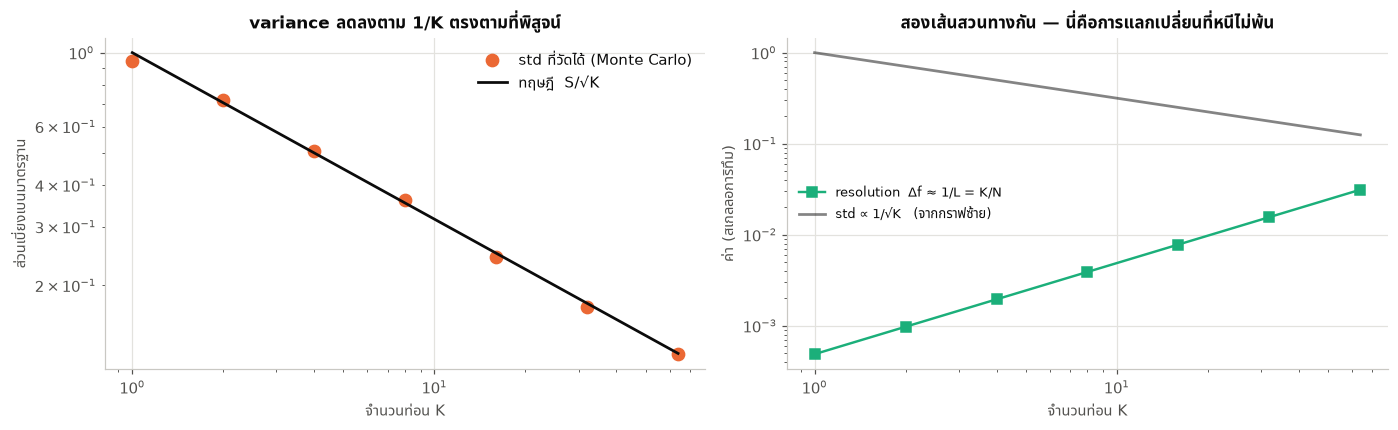

   K   std วัดได้    ทฤษฎี S/√K    ผิดพลาด
---------------------------------------------
   1       0.9469        1.0000       5.3%
   2       0.7186        0.7071       1.6%
   4       0.5055        0.5000       1.1%
   8       0.3604        0.3536       1.9%
  16       0.2429        0.2500       2.8%
  32       0.1721        0.1768       2.6%
  64       0.1244        0.1250       0.5%


In [18]:
# ---- ยืนยันสูตร Var = S²/K ด้วย Monte Carlo ----
N_v2   = 2048
K_list = [1, 2, 4, 8, 16, 32, 64]
n_rep2 = 600
meas_std, theo_std = [], []

for K_v in K_list:
    L_v  = N_v2 // K_v
    vals = np.empty(n_rep2)
    for i in range(n_rep2):
        xw = rng.standard_normal(N_v2)            # white noise, S = 1
        _, PB, _ = bartlett_psd(xw, L_v, NFFT=L_v)
        vals[i] = PB[L_v//4]                      # ดูที่ f = 0.25
    meas_std.append(vals.std())
    theo_std.append(1.0/np.sqrt(K_v))             # S/√K โดย S = 1

fig, ax = plt.subplots(1, 2, figsize=(12.8, 4.0))

ax[0].loglog(K_list, meas_std, "o", color=C_BAR, ms=8, label="std ที่วัดได้ (Monte Carlo)")
ax[0].loglog(K_list, theo_std, "-", color=C_TRUE, lw=1.8, label="ทฤษฎี  S/√K")
ax[0].set_xlabel("จำนวนท่อน K"); ax[0].set_ylabel("ส่วนเบี่ยงเบนมาตรฐาน")
ax[0].set_title("variance ลดลงตาม 1/K ตรงตามที่พิสูจน์")
ax[0].legend(loc="upper right")

# อีกด้าน: resolution แย่ลงตาม K
ax[1].loglog(K_list, [K_v/N_v2 for K_v in K_list], "s-", color=C_WEL, ms=7,
             label="resolution  Δf ≈ 1/L = K/N")
ax[1].loglog(K_list, theo_std, "-", color=C_TRUE, lw=1.8, alpha=0.5,
             label="std ∝ 1/√K   (จากกราฟซ้าย)")
ax[1].set_xlabel("จำนวนท่อน K"); ax[1].set_ylabel("ค่า (สเกลลอการิทึม)")
ax[1].set_title("สองเส้นสวนทางกัน — นี่คือการแลกเปลี่ยนที่หนีไม่พ้น")
ax[1].legend(loc="center left", fontsize=8.5)

plt.tight_layout(); plt.show()

print(f"{'K':>4s} {'std วัดได้':>12s} {'ทฤษฎี S/√K':>13s} {'ผิดพลาด':>10s}")
print("-"*45)
for K_v, m, t in zip(K_list, meas_std, theo_std):
    print(f"{K_v:>4d} {m:>12.4f} {t:>13.4f} {abs(m-t)/t*100:>9.1f}%")

ค่าที่วัดได้ตรงกับทฤษฎี $S/\sqrt{K}$ ภายในไม่กี่เปอร์เซ็นต์ (ที่เหลือคือ
ความคลาดเคลื่อนของ Monte Carlo เอง และการที่ท่อนไม่ได้เป็นอิสระกัน 100%)
→ **การพิสูจน์ถูกต้อง**

### จุดอ่อนของ Bartlett ที่นำไปสู่ Welch

Bartlett แก้ปัญหา variance ได้ แต่ยังทิ้งของดีไว้บนโต๊ะสองอย่าง:

1. **ยังใช้หน้าต่างสี่เหลี่ยม** → ยังมี leakage เต็ม ๆ (โลบข้าง $-13$ dB) จากส่วนที่ 5
2. **ท่อนไม่ทับกัน** → ข้อมูลตรงรอยต่อถูกใช้ไม่เต็มที่ และถ้าอยากได้ $K$ มาก ๆ
   ก็ต้องยอมให้ $L$ สั้นลงมาก

Welch แก้ทั้งสองข้อพร้อมกัน

---
# ส่วนที่ 7 — Welch's Method

## 7.1 แนวคิด

**Peter D. Welch (ค.ศ. 1967)** ปรับปรุง Bartlett ด้วยสองอย่าง:

1. **ใส่หน้าต่าง (window)** ให้แต่ละท่อน → ลด leakage (แก้จุดอ่อนข้อ 1 ของ Bartlett)
2. **ให้ท่อนทับกัน (overlap)** โดยทั่วไป 50% → ได้จำนวนท่อนมากขึ้นจากข้อมูลชุดเดิม
   (แก้จุดอ่อนข้อ 2)

$$\boxed{\;\hat{S}_{W}(f) \;=\; \frac{1}{K}\sum_{i=0}^{K-1}
\frac{1}{L\,U}\left|\sum_{n=0}^{L-1} x[iD+n]\,w[n]\,e^{-j2\pi f n}\right|^{2}\;}$$

โดย

- $L$ = ความยาวท่อน
- $D$ = ระยะเลื่อน (hop size); overlap 50% หมายถึง $D = L/2$
- $K = \left\lfloor \frac{N-L}{D}\right\rfloor + 1$ = จำนวนท่อน
- $w[n]$ = หน้าต่าง (นิยม Hann)
- $U = \frac{1}{L}\sum_{n=0}^{L-1} w^{2}[n]$ = **ตัวประกอบปรับค่ากำลัง**

## 7.2 ทำไมต้องมี $U$ — พิสูจน์การ normalize

หน้าต่างไปลดทอนแอมพลิจูดของข้อมูล ถ้าไม่ชดเชย ค่า PSD ที่ได้จะต่ำกว่าความจริง
หา $U$ ที่ถูกต้องได้จากการบังคับให้ตัวประมาณไม่มี bias สำหรับ white noise

ให้ $x[n]$ เป็น white noise ที่ $E\{x[n]x^*[k]\} = \sigma^2\delta[n-k]$ พิจารณาตัวเศษ:

$$E\left\{\left|\sum_{n} x[n]w[n]e^{-j2\pi fn}\right|^{2}\right\}
= \sum_{n}\sum_{k} \underbrace{E\{x[n]x^{*}[k]\}}_{\sigma^{2}\delta[n-k]}\, w[n]w[k]\,e^{-j2\pi f(n-k)}$$

เดลตาบังคับให้เหลือเฉพาะพจน์ $n = k$ ซึ่งทำให้พจน์เอ็กซ์โพเนนเชียลกลายเป็น 1:

$$= \sigma^{2}\sum_{n=0}^{L-1} w^{2}[n]$$

เราต้องการให้ตัวประมาณคืนค่า $\sigma^2$ (ซึ่งคือ PSD ของ white noise) พอดี จึงต้องหารด้วย $\sum_n w^2[n]$:

$$\hat{S}_{W}(f) = \frac{\left|\cdot\right|^{2}}{\sum_{n} w^{2}[n]}
= \frac{\left|\cdot\right|^{2}}{L\cdot\underbrace{\tfrac{1}{L}\sum_{n} w^{2}[n]}_{U}} \qquad \blacksquare$$

> ⚠️ ระวังสับสน: การหารด้วย $\sum w^2[n]$ ใช้สำหรับ **PSD (power spectral density)**
> ส่วนถ้าต้องการ **power spectrum** ของสัญญาณที่เป็นเส้นสเปกตรัม (เช่นวัดแอมพลิจูดของไซน์)
> ต้องหารด้วย $\left(\sum w[n]\right)^2$ แทน — คนละตัวกัน
> (ใน `scipy.signal.welch` คือ `scaling='density'` กับ `scaling='spectrum'`)

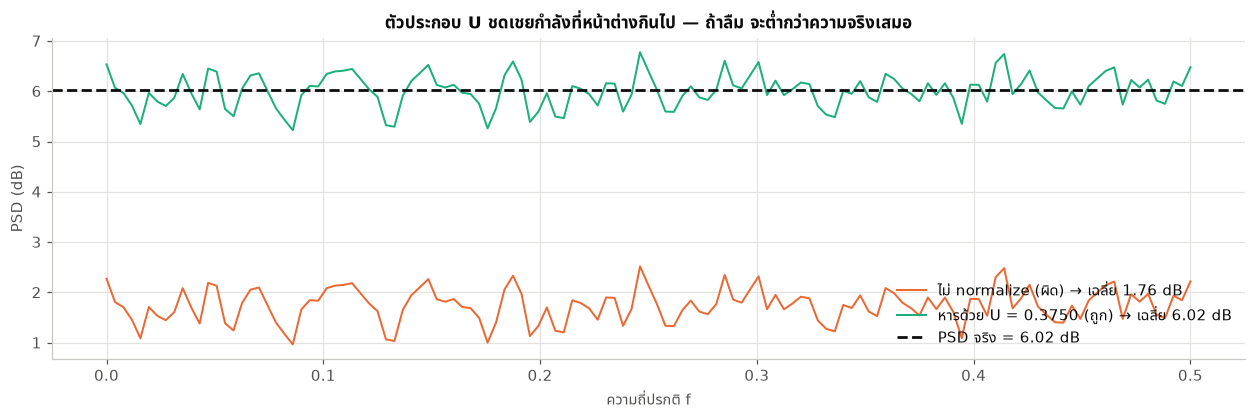

σ² จริง                      = 4.0000
ไม่ normalize                 = 1.4984   ← ต่ำไป -4.26 dB
normalize ด้วย U             = 3.9958   ← ถูกต้อง

สำหรับ Hann: U = mean(w²) = 3/8 = 0.3750 → ถ้าลืมจะต่ำไป 4.26 dB


In [19]:
# ---- ลงมือทำ Welch ----
def welch_psd(x, L, overlap=0.5, window="hann", NFFT=None):
    """
    Welch's method — คืนค่า (freq, PSD สองด้าน, จำนวนท่อน K)
    ประเมินที่จุดความถี่ 0…0.5 โดยใช้ fs = 1

    overlap : สัดส่วนการทับซ้อน 0.0 = Bartlett (ถ้าใช้หน้าต่างสี่เหลี่ยม)
    """
    NFFT = NFFT or L
    # กันพลาดแบบเดียวกับ bartlett_psd: NFFT < L จะทำให้ rfft ตัดข้อมูลทิ้งเงียบ ๆ
    # ซึ่งยิ่งอันตรายที่นี่ เพราะหน้าต่างจะถูกตัดครึ่งไปด้วย
    if NFFT < L:
        raise ValueError(f"ต้องมี NFFT >= L (ได้ NFFT={NFFT}, L={L})")
    w    = sig.get_window(window, L, fftbins=True)
    D    = max(1, int(round(L * (1.0 - overlap))))    # ระยะเลื่อน
    U    = np.mean(w**2)                              # ตัวประกอบ normalize
    starts = range(0, len(x) - L + 1, D)
    P = np.array([np.abs(np.fft.rfft(x[s:s+L]*w, NFFT))**2 / (L*U)
                  for s in starts])
    return np.fft.rfftfreq(NFFT), P.mean(axis=0), len(P)

# ---- พิสูจน์ว่า U จำเป็นจริง: วัดกำลังของ white noise ที่รู้ค่าแน่นอน ----
sigma2_true = 4.0
x_u = np.sqrt(sigma2_true) * rng.standard_normal(20000)
L_u = 256
w_u = sig.windows.hann(L_u, sym=False)
U_u = np.mean(w_u**2)

D_u = L_u//2
segs = np.array([x_u[s:s+L_u] for s in range(0, len(x_u)-L_u+1, D_u)])
raw  = np.mean(np.abs(np.fft.rfft(segs*w_u, axis=1))**2, axis=0) / L_u

names = ["ไม่ normalize (ผิด)", f"หารด้วย U = {U_u:.4f} (ถูก)"]
ests  = [raw, raw/U_u]

fig, ax = plt.subplots(figsize=(11.5, 3.9))
f_u = np.fft.rfftfreq(L_u)
for est, nm, col in zip(ests, names, [C_BAR, C_WEL]):
    ax.plot(f_u, 10*np.log10(est), color=col, lw=1.3,
            label=f"{nm} → เฉลี่ย {10*np.log10(est.mean()):.2f} dB")
ax.axhline(10*np.log10(sigma2_true), color=C_TRUE, ls="--", lw=1.8,
           label=f"PSD จริง = {10*np.log10(sigma2_true):.2f} dB")
ax.set_xlabel("ความถี่ปรกติ f"); ax.set_ylabel("PSD (dB)")
ax.set_title("ตัวประกอบ U ชดเชยกำลังที่หน้าต่างกินไป — ถ้าลืม จะต่ำกว่าความจริงเสมอ")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

print(f"σ² จริง                      = {sigma2_true:.4f}")
print(f"ไม่ normalize                 = {raw.mean():.4f}   ← ต่ำไป {10*np.log10(U_u):.2f} dB")
print(f"normalize ด้วย U             = {(raw/U_u).mean():.4f}   ← ถูกต้อง")
print(f"\nสำหรับ Hann: U = mean(w²) = 3/8 = {3/8:.4f} → ถ้าลืมจะต่ำไป {-10*np.log10(3/8):.2f} dB")

ไม่ normalize แล้วต่ำกว่าความจริง 4.26 dB พอดี ซึ่งคือ $-10\log_{10}(3/8)$
เพราะหน้าต่าง Hann มี $U = 3/8$ พอดีเป๊ะ

## 7.3 การทับซ้อน (overlap) และผลต่อ variance

การทับซ้อนให้ **จำนวนท่อนเพิ่มขึ้น** จากข้อมูลชุดเดิม (ที่ 50% ได้เกือบ 2 เท่า)
แต่มีข้อเสียที่ต้องคิดให้รอบคอบ: **ท่อนที่ทับกันย่อมไม่เป็นอิสระต่อกัน**
ดังนั้นสูตร $\operatorname{Var} = S^2/K$ ของ Bartlett **ใช้ไม่ได้ตรง ๆ**

สูตรทั่วไปสำหรับค่าเฉลี่ยของตัวแปรที่สหสัมพันธ์กัน:

$$\operatorname{Var}\{\hat{S}_{W}\} = \frac{S^{2}}{K}
\left[1 + 2\sum_{j=1}^{K-1}\left(1-\frac{j}{K}\right)\rho[j]\right]$$

โดย $\rho[j]$ คือสัมประสิทธิ์สหสัมพันธ์ระหว่าง periodogram ของท่อนที่ห่างกัน $j$ ท่อน
สำหรับข้อมูล Gaussian สามารถแสดงได้ว่ามันคือ **กำลังสอง** ของสหสัมพันธ์ของหน้าต่าง:

$$\rho[j] \;=\; \left[\frac{\sum_{n} w[n]\,w[n+jD]}{\sum_{n} w^{2}[n]}\right]^{2}$$

(ยกกำลังสองเพราะ periodogram เป็นปริมาณ *กำลังสอง* ของสิ่งที่ Gaussian)

### กรณีคลาสสิก: overlap 50%

ที่ $D = L/2$ มีแค่ท่อนที่ติดกันเท่านั้นที่ทับกัน ($\rho[j] = 0$ เมื่อ $j \ge 2$) จึงเหลือ

$$\operatorname{Var}\{\hat{S}_{W}\} \approx \frac{S^{2}}{K}\left(1 + 2\rho[1]\right)$$

สำหรับ **หน้าต่างสามเหลี่ยม** คำนวณได้ $\rho[1] = (1/4)^2 = 1/16$ ให้

$$\operatorname{Var} = \frac{S^{2}}{K}\left(1+\tfrac{2}{16}\right) = \frac{9}{8}\cdot\frac{S^{2}}{K}$$

ซึ่งคือ **ตัวเลข 9/8 ที่โด่งดัง** ในตำรา แต่เพราะ overlap ทำให้ $K$ เพิ่มเป็นเกือบ 2 เท่า
ผลสุทธิคือ variance เหลือ $\frac{9}{8}\cdot\frac{1}{2} = \frac{9}{16} \approx 0.56$ เท่าของ Bartlett
**ที่ resolution เท่ากัน** — ดีขึ้นเกือบ 2 เท่าฟรี ๆ

สำหรับ **Hann**: $\rho[1] = (1/6)^2 = 1/36$ ให้ตัวคูณ $1 + 2/36 = 19/18 \approx 1.056$ ซึ่งดีกว่าอีก

มาตรวจสอบทั้งหมดนี้ด้วยตัวเลข

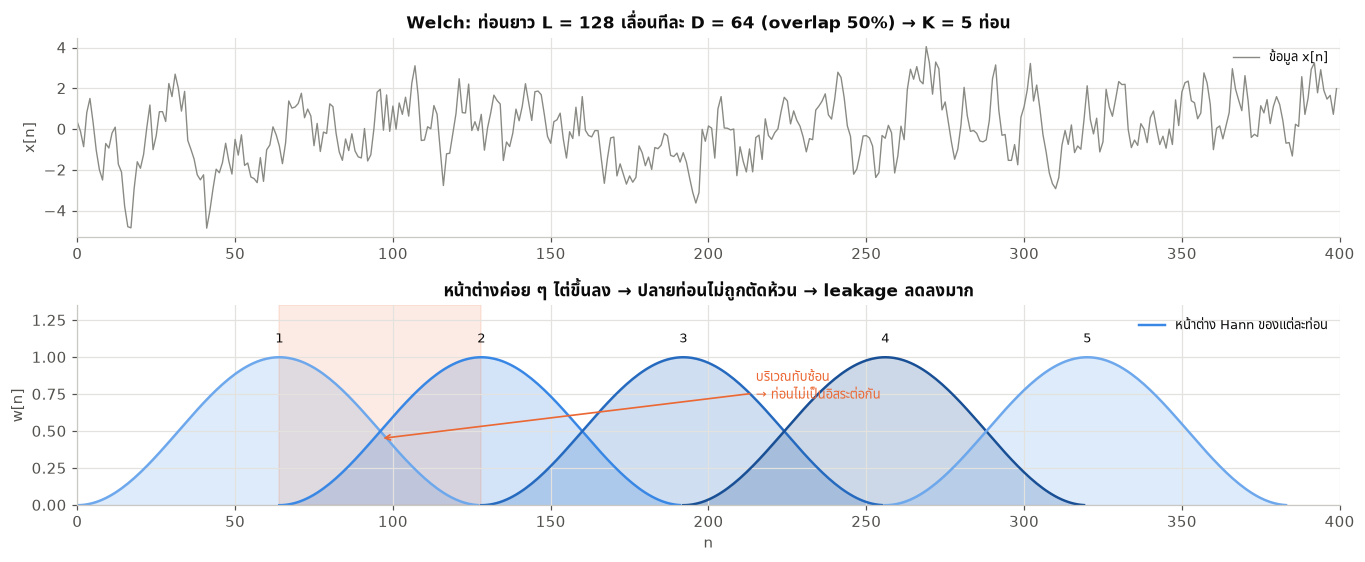

Bartlett (ไม่ทับ) : K = 3 ท่อน
Welch (ทับ 50%)   : K = 5 ท่อน  ← ได้ท่อนเพิ่มจากข้อมูลชุดเดียวกัน


In [20]:
# ---- แผนภาพการทับซ้อนของ Welch ----
N_ov, L_ov = 400, 128
D_ov = L_ov // 2
w_ov = sig.windows.hann(L_ov, sym=False)
x_ov = sig.lfilter([1.0], [1.0, -0.75], rng.standard_normal(N_ov+200))[200:]
starts_ov = list(range(0, N_ov-L_ov+1, D_ov))

fig, ax = plt.subplots(2, 1, figsize=(12.5, 5.2),
                       gridspec_kw={"height_ratios": [1.5, 1.5]})

ax[0].plot(np.arange(N_ov), x_ov, color=C_MUTE, lw=0.9, label="ข้อมูล x[n]")
ax[0].set_xlim(0, N_ov); ax[0].set_ylabel("x[n]")
ax[0].set_title(f"Welch: ท่อนยาว L = {L_ov} เลื่อนทีละ D = {D_ov} (overlap 50%) → K = {len(starts_ov)} ท่อน")
ax[0].legend(loc="upper right", fontsize=8.5)

for i, s in enumerate(starts_ov):
    col = BLUES[(i % 4) + 2]
    ax[1].plot(np.arange(s, s+L_ov), w_ov, color=col, lw=1.6)
    ax[1].fill_between(np.arange(s, s+L_ov), 0, w_ov, color=col, alpha=0.22)
    ax[1].text(s+L_ov/2, 1.10, f"{i+1}", ha="center", fontsize=8.5, color=C_TRUE)
ax[1].plot([], [], color=BLUES[3], lw=1.6, label="หน้าต่าง Hann ของแต่ละท่อน")
ax[1].axvspan(starts_ov[1], starts_ov[0]+L_ov, color=C_BAR, alpha=0.13)
ax[1].annotate("บริเวณทับซ้อน\n→ ท่อนไม่เป็นอิสระต่อกัน",
               xy=((starts_ov[1]+starts_ov[0]+L_ov)/2, 0.45), xytext=(215, 0.72),
               color=C_BAR, fontsize=8.5,
               arrowprops=dict(arrowstyle="->", color=C_BAR, lw=1.1))
ax[1].set_xlim(0, N_ov); ax[1].set_ylim(0, 1.35)
ax[1].set_xlabel("n"); ax[1].set_ylabel("w[n]")
ax[1].set_title("หน้าต่างค่อย ๆ ไต่ขึ้นลง → ปลายท่อนไม่ถูกตัดห้วน → leakage ลดลงมาก")
ax[1].legend(loc="upper right", fontsize=8.5)

plt.tight_layout(); plt.show()

nb = N_ov // L_ov
print(f"Bartlett (ไม่ทับ) : K = {nb} ท่อน")
print(f"Welch (ทับ 50%)   : K = {len(starts_ov)} ท่อน  ← ได้ท่อนเพิ่มจากข้อมูลชุดเดียวกัน")

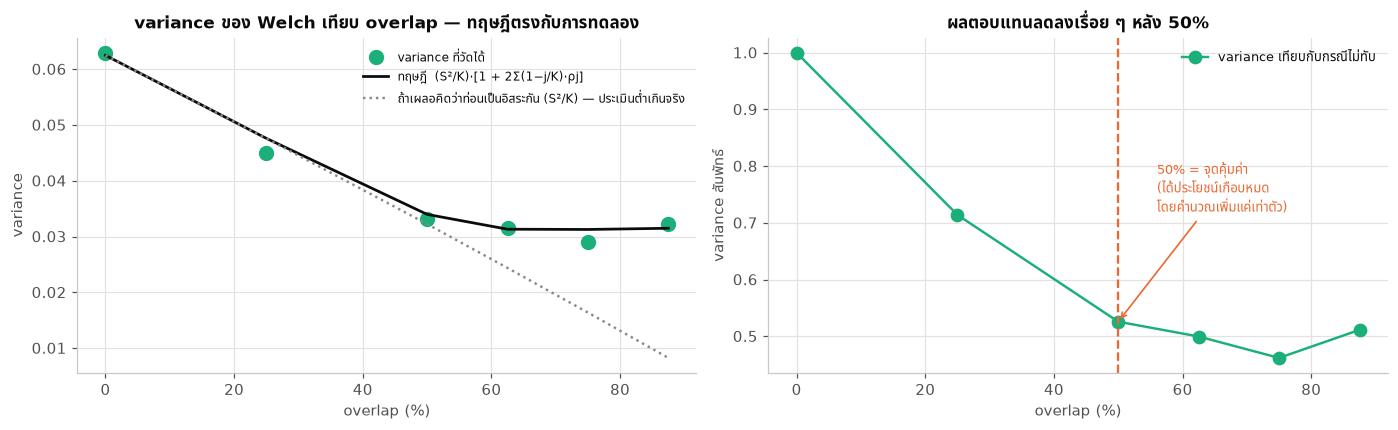

 overlap     K     ρ[1]  var วัดได้   var ทฤษฎี   ผิดพลาด
--------------------------------------------------------------
    0.0%    16   0.0000     0.06296     0.06250      0.7%
   25.0%    21   0.0001     0.04496     0.04762      5.6%
   50.0%    31   0.0278     0.03311     0.03399      2.6%
   62.5%    41   0.1458     0.03146     0.03133      0.4%
   75.0%    61   0.4345     0.02909     0.03129      7.0%
   87.5%   121   0.8138     0.03220     0.03150      2.2%

Hann ที่ overlap 50%: ρ[1] = 0.0278  (ทฤษฎี 1/36 = 0.0278)
ตัวคูณ variance      = 1.0556  (ทฤษฎี 19/18 = 1.0556)


In [21]:
# ---- ยืนยันสูตร variance ของ Welch: ทฤษฎี vs Monte Carlo ----
def rho_theory(w, D, j):
    """สหสัมพันธ์ระหว่าง periodogram ของท่อนที่ห่างกัน j ท่อน (ข้อมูล Gaussian ขาว)"""
    L = len(w)
    shift = j*D
    if shift >= L:
        return 0.0
    return (np.sum(w[shift:]*w[:L-shift]) / np.sum(w**2))**2

def var_factor(w, D, K):
    """ตัวคูณ [1 + 2Σ(1-j/K)ρ[j]] ในสูตร variance"""
    return 1.0 + 2.0*sum((1-j/K)*rho_theory(w, D, j) for j in range(1, K))

N_wv  = 4096
L_wv  = 256
ovs   = [0.0, 0.25, 0.5, 0.625, 0.75, 0.875]
n_rep = 500
res   = []

for ov in ovs:
    w_  = sig.windows.hann(L_wv, sym=False)
    D_  = max(1, int(round(L_wv*(1-ov))))
    K_  = (N_wv - L_wv)//D_ + 1
    vals = np.empty(n_rep)
    for i in range(n_rep):
        xw = rng.standard_normal(N_wv)                    # white noise, S = 1
        _, PW, Kact = welch_psd(xw, L_wv, overlap=ov, window="hann", NFFT=L_wv)
        vals[i] = PW[L_wv//4]
    var_meas = vals.var()
    var_theo = (1.0/K_) * var_factor(w_, D_, K_)          # S = 1
    res.append((ov, K_, var_meas, var_theo, rho_theory(w_, D_, 1)))

fig, ax = plt.subplots(1, 2, figsize=(12.8, 4.0))

ovp = [r[0]*100 for r in res]
ax[0].plot(ovp, [r[2] for r in res], "o", color=C_WEL, ms=9, label="variance ที่วัดได้")
ax[0].plot(ovp, [r[3] for r in res], "-", color=C_TRUE, lw=1.8,
           label="ทฤษฎี  (S²/K)·[1 + 2Σ(1−j/K)·ρj]")
ax[0].plot(ovp, [1.0/r[1] for r in res], ":", color=C_MUTE, lw=1.6,
           label="ถ้าเผลอคิดว่าท่อนเป็นอิสระกัน (S²/K) — ประเมินต่ำเกินจริง")
ax[0].set_xlabel("overlap (%)"); ax[0].set_ylabel("variance")
ax[0].set_title("variance ของ Welch เทียบ overlap — ทฤษฎีตรงกับการทดลอง")
ax[0].legend(loc="upper right", fontsize=8)

# ผลตอบแทนที่ลดลง: variance เทียบกับที่ 0% overlap
base = res[0][2]
ax[1].plot(ovp, [r[2]/base for r in res], "o-", color=C_WEL, ms=8,
           label="variance เทียบกับกรณีไม่ทับ")
ax[1].axvline(50, color=C_BAR, ls="--", lw=1.5)
ax[1].annotate("50% = จุดคุ้มค่า\n(ได้ประโยชน์เกือบหมด\nโดยคำนวณเพิ่มแค่เท่าตัว)",
               xy=(50, res[2][2]/base), xytext=(56, 0.72), color=C_BAR, fontsize=8.5,
               arrowprops=dict(arrowstyle="->", color=C_BAR, lw=1.1))
ax[1].set_xlabel("overlap (%)"); ax[1].set_ylabel("variance สัมพัทธ์")
ax[1].set_title("ผลตอบแทนลดลงเรื่อย ๆ หลัง 50%")
ax[1].legend(loc="upper right", fontsize=8.5)

plt.tight_layout(); plt.show()

print(f"{'overlap':>8s} {'K':>5s} {'ρ[1]':>8s} {'var วัดได้':>11s} {'var ทฤษฎี':>11s} {'ผิดพลาด':>9s}")
print("-"*62)
for ov, K_, vm, vt, r1 in res:
    print(f"{ov*100:>7.1f}% {K_:>5d} {r1:>8.4f} {vm:>11.5f} {vt:>11.5f} {abs(vm-vt)/vt*100:>8.1f}%")
print(f"\nHann ที่ overlap 50%: ρ[1] = {res[2][4]:.4f}  (ทฤษฎี 1/36 = {1/36:.4f})")
print(f"ตัวคูณ variance      = {1+2*res[2][4]:.4f}  (ทฤษฎี 19/18 = {19/18:.4f})")

ทฤษฎีกับการทดลองตรงกันภายในไม่กี่เปอร์เซ็นต์ และค่า $\rho[1] = 1/36$
กับตัวคูณ $19/18$ ที่คำนวณไว้ก็ตรงเป๊ะ

เส้นประสีเทาแสดงข้อผิดพลาดที่พบบ่อย: ถ้าเผลอใช้สูตร $S^2/K$ ตรง ๆ กับ Welch
จะ **ประเมิน variance ต่ำกว่าความจริง** เพราะลืมว่าท่อนที่ทับกันไม่เป็นอิสระ

กราฟขวาอธิบายว่าทำไม **50% ถึงเป็นค่ามาตรฐาน**: มันได้ประโยชน์เกือบทั้งหมด
โดยคำนวณเพิ่มแค่เท่าตัว ถ้าดันไปถึง 75% จะได้ดีขึ้นอีกนิดเดียวแต่คำนวณเพิ่มสองเท่า

---
# ส่วนที่ 8 — เปรียบเทียบทั้งสามวิธี

## 8.1 เปรียบเทียบด้วยตาบนข้อมูลชุดเดียวกัน

การเปรียบเทียบที่ยุติธรรมต้องกำหนดให้ **ความยาวท่อน $L$ เท่ากัน**
เพราะ $L$ เป็นตัวกำหนด resolution ถ้า $L$ เท่ากัน ทั้งสามวิธีก็มี resolution พอ ๆ กัน
แล้วเราค่อยดูว่าใครให้ variance ต่ำกว่า

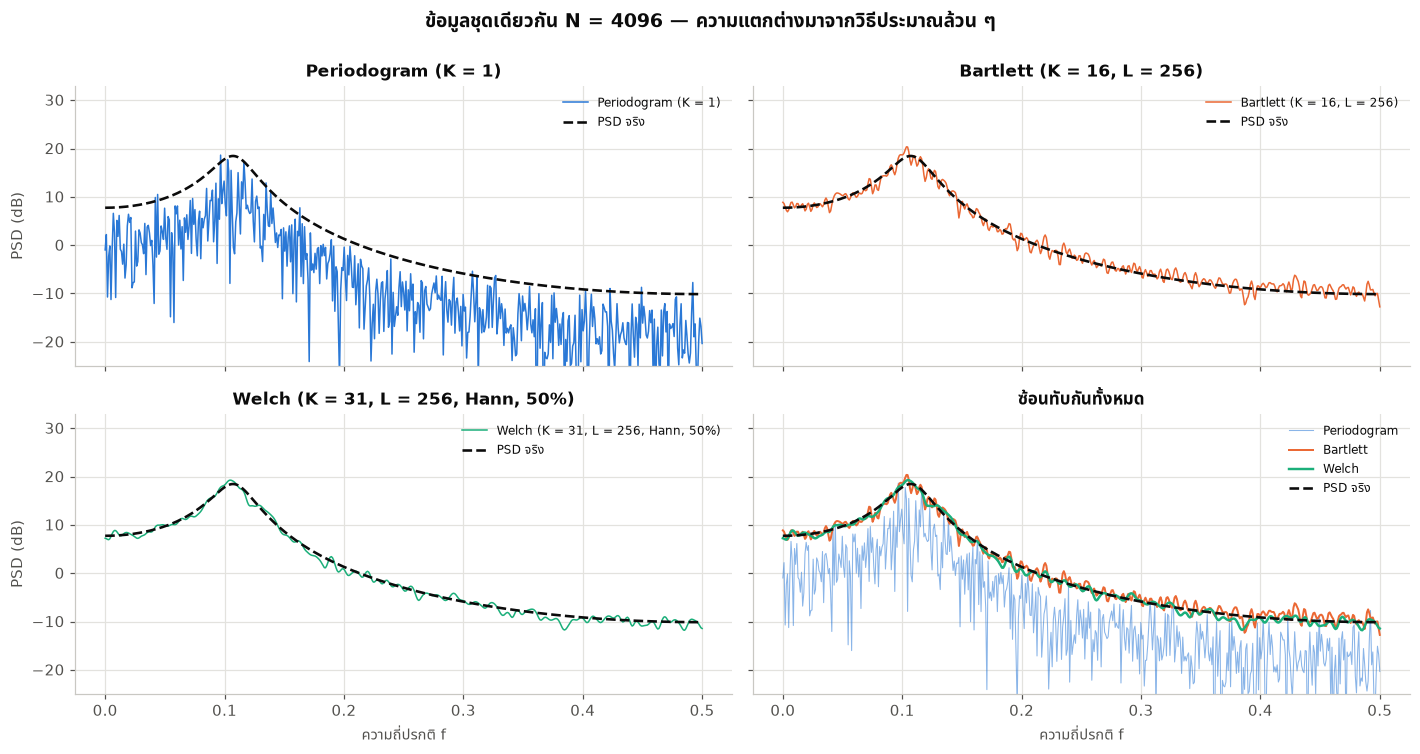

วิธี                K std ที่พื้นเรียบ    ผิดพลาดที่ยอด
----------------------------------------------------------
Periodogram         1          6.34 dB          0.18 dB
Bartlett           16          1.27 dB          1.89 dB
Welch              31          0.97 dB          0.80 dB


In [22]:
# ---- เปรียบเทียบสามวิธีบนข้อมูลชุดเดียวกัน ----
a_cmp  = np.array([1.0, -1.40, 0.81])          # AR(2) มียอดแหลม
N_cmp  = 4096
L_cmp  = 256
NF_cmp = 1024
x_cmp  = sig.lfilter([1.0], a_cmp, rng.standard_normal(N_cmp+1000))[1000:]

f_cmp   = np.fft.rfftfreq(NF_cmp)
_, H_c  = sig.freqz([1.0], a_cmp, worN=f_cmp, fs=1.0)
S_cmp   = np.abs(H_c)**2

P_per          = np.abs(np.fft.rfft(x_cmp, NF_cmp))**2 / N_cmp
_, P_bart, Kb  = bartlett_psd(x_cmp, L_cmp, NFFT=NF_cmp)
_, P_wel,  Kw  = welch_psd(x_cmp, L_cmp, overlap=0.5, window="hann", NFFT=NF_cmp)

fig, ax = plt.subplots(2, 2, figsize=(13, 6.8), sharex=True, sharey=True)
panels = [(P_per,  C_PER, f"Periodogram (K = 1)"),
          (P_bart, C_BAR, f"Bartlett (K = {Kb}, L = {L_cmp})"),
          (P_wel,  C_WEL, f"Welch (K = {Kw}, L = {L_cmp}, Hann, 50%)")]

for axk, (P, col, nm) in zip(ax.ravel()[:3], panels):
    axk.plot(f_cmp, 10*np.log10(P+1e-12), color=col, lw=1.0, label=nm)
    axk.plot(f_cmp, 10*np.log10(S_cmp), "--", color=C_TRUE, lw=1.7, label="PSD จริง")
    axk.set_title(nm); axk.set_ylim(-25, 33)
    axk.legend(loc="upper right", fontsize=8)

axk = ax.ravel()[3]
axk.plot(f_cmp, 10*np.log10(P_per+1e-12),  color=C_PER, lw=0.7, alpha=0.55, label="Periodogram")
axk.plot(f_cmp, 10*np.log10(P_bart+1e-12), color=C_BAR, lw=1.3, label="Bartlett")
axk.plot(f_cmp, 10*np.log10(P_wel+1e-12),  color=C_WEL, lw=1.6, label="Welch")
axk.plot(f_cmp, 10*np.log10(S_cmp), "--", color=C_TRUE, lw=1.7, label="PSD จริง")
axk.set_title("ซ้อนทับกันทั้งหมด"); axk.set_ylim(-25, 33)
axk.legend(loc="upper right", fontsize=8)

for k in [2, 3]: ax.ravel()[k].set_xlabel("ความถี่ปรกติ f")
for k in [0, 2]: ax.ravel()[k].set_ylabel("PSD (dB)")
fig.suptitle("ข้อมูลชุดเดียวกัน N = 4096 — ความแตกต่างมาจากวิธีประมาณล้วน ๆ",
             fontsize=12.5, fontweight="bold", y=1.00)
plt.tight_layout(); plt.show()

flat = (f_cmp > 0.33) & (f_cmp < 0.48)
print(f"{'วิธี':<16s} {'K':>4s} {'std ที่พื้นเรียบ':>16s} {'ผิดพลาดที่ยอด':>16s}")
print("-"*58)
for P, nm, K_ in [(P_per, "Periodogram", 1), (P_bart, "Bartlett", Kb), (P_wel, "Welch", Kw)]:
    s = np.std(10*np.log10(P[flat]))
    e = 10*np.log10(P.max()) - 10*np.log10(S_cmp.max())
    print(f"{nm:<16s} {K_:>4d} {s:>13.2f} dB {e:>13.2f} dB")

ความแตกต่างเห็นได้ชัดด้วยตา: periodogram เป็นหญ้ารก ส่วน Welch เรียบและตามรูปทรง
ของ PSD จริงได้ดีที่สุด โดยใช้ข้อมูลชุดเดียวกันเป๊ะ

Welch ได้ $K$ มากกว่า Bartlett เกือบเท่าตัวที่ $L$ เท่ากัน (จากการ overlap)
จึงมี std ต่ำกว่า

### 💡 ทำไม periodogram ถึงดู "ต่ำกว่า" เส้น PSD จริง?

สังเกตกราฟซ้ายบนให้ดี — หญ้าของ periodogram ดูเหมือนจะเกาะอยู่ *ใต้* เส้นประ
ทั้งที่เราเพิ่งพิสูจน์ไปว่ามันเป็นตัวประมาณที่ (เกือบ) ไม่มี bias

นี่**ไม่ใช่ bias** แต่เป็นผลจากการ **วาดกราฟในหน่วย dB** ล้วน ๆ:

- ที่จริง $E\{\hat{S}\} = S$ ถูกต้องแล้ว — แต่นั่นคือค่าเฉลี่ยใน **สเกลเชิงเส้น**
- ส่วนกราฟวาดด้วย $10\log_{10}\hat{S}$ และเพราะ $\log$ เป็นฟังก์ชันเว้า (concave)
  อสมการของเยนเซน (Jensen) จึงบอกว่า $E\{\log \hat{S}\} < \log E\{\hat{S}\}$

คำนวณออกมาได้ตรง ๆ จากที่รู้ว่า $\hat{S}/S \sim \text{Exp}(1)$ ซึ่งมี $E\{\ln X\} = -\gamma$
โดย $\gamma \approx 0.5772$ คือค่าคงที่ออยเลอร์–มาสเชโรนี:

$$E\{10\log_{10}\hat{S}\} - 10\log_{10}S
= \frac{10}{\ln 10}\,E\{\ln X\} = -\frac{10\gamma}{\ln 10} \approx -2.51\ \text{dB}$$

> **periodogram ที่วาดในหน่วย dB จะเกาะต่ำกว่าค่าจริงราว 2.5 dB โดยเฉลี่ยเสมอ**
> ทั้งที่ในสเกลเชิงเส้นมันถูกต้องสมบูรณ์
>
> พอเฉลี่ย $K$ ท่อนแบบ Bartlett/Welch การแจกแจงจะแคบลง ผลของเยนเซนก็จางลงตาม
> เส้นจึงกลับมาเกาะเส้นจริงพอดี — ตรงกับที่เห็นในกราฟ

สำหรับค่าเฉลี่ยของ $K$ ท่อน (ที่เป็นอิสระกัน) คำนวณค่าเบี่ยงนี้ได้แม่นยำด้วยฟังก์ชันไดแกมมา $\psi$:

$$\text{ค่าเบี่ยงในหน่วย dB} = \frac{10}{\ln 10}\Big(\psi(K) - \ln K\Big)
\;\xrightarrow[\;K \text{ ใหญ่}\;]{}\; -\frac{2.171}{K}\ \text{dB}$$

| $K$ | 1 | 2 | 4 | 8 | 16 | 31 |
|---|---|---|---|---|---|---|
| ค่าเบี่ยง (dB) | $-2.51$ | $-1.17$ | $-0.57$ | $-0.28$ | $-0.14$ | $-0.07$ |

ที่ $K = 31$ (ค่าที่ใช้ในกราฟ Welch ข้างบน) เหลือแค่ $-0.07$ dB — มองไม่เห็นแล้ว

## 8.2 วัดผลเชิงปริมาณด้วย Monte Carlo

การดูด้วยตาไม่พอ เราจะวัด **bias**, **variance** และ **MSE** อย่างเป็นระบบ

$$\text{MSE}(f) = \underbrace{\left(E\{\hat{S}(f)\} - S(f)\right)^{2}}_{\text{bias}^2}
\;+\; \underbrace{\operatorname{Var}\{\hat{S}(f)\}}_{\text{variance}}$$

MSE คือตัวชี้วัดที่ยุติธรรมที่สุด เพราะรวมทั้งสองด้านของการแลกเปลี่ยนเข้าด้วยกัน

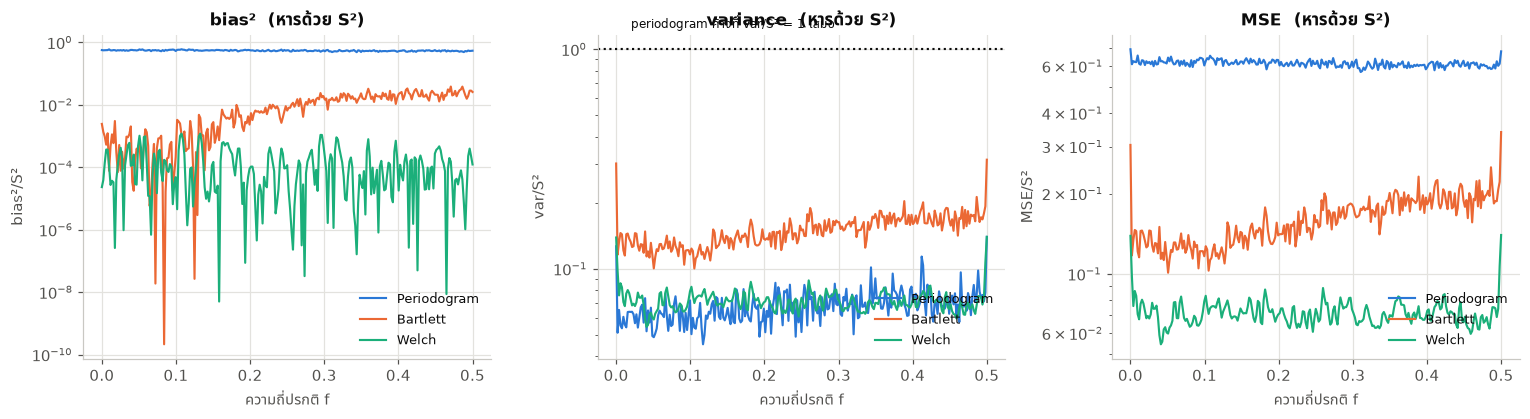

วิธี             bias² เฉลี่ย    var เฉลี่ย    MSE เฉลี่ย
----------------------------------------------------------
Periodogram           0.54646       0.06801       0.61447
Bartlett              0.01076       0.14994       0.16070
Welch                 0.00018       0.07157       0.07175

MSE ต่ำสุด: Welch


In [23]:
# ---- Monte Carlo: bias² / variance / MSE ของทั้งสามวิธี ----
n_mc2  = 400
N_mc   = 2048
L_mc   = 256
NF_mc  = 512
f_mc   = np.fft.rfftfreq(NF_mc)
_, H_m = sig.freqz([1.0], a_cmp, worN=f_mc, fs=1.0)
S_mc_true = np.abs(H_m)**2

acc = {k: [] for k in ["Periodogram", "Bartlett", "Welch"]}
for _ in range(n_mc2):
    xm = sig.lfilter([1.0], a_cmp, rng.standard_normal(N_mc+800))[800:]
    acc["Periodogram"].append(np.abs(np.fft.rfft(xm, NF_mc))**2 / N_mc)
    acc["Bartlett"].append(bartlett_psd(xm, L_mc, NFFT=NF_mc)[1])
    acc["Welch"].append(welch_psd(xm, L_mc, 0.5, "hann", NFFT=NF_mc)[1])

stats_tbl, cols = {}, {"Periodogram": C_PER, "Bartlett": C_BAR, "Welch": C_WEL}
for k, v in acc.items():
    A = np.array(v)
    bias2 = (A.mean(axis=0) - S_mc_true)**2
    var   = A.var(axis=0)
    stats_tbl[k] = (bias2, var, bias2 + var)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.9))
for k in acc:
    b2, vr, mse = stats_tbl[k]
    ax[0].semilogy(f_mc, b2 / S_mc_true**2, color=cols[k], lw=1.4, label=k)
    ax[1].semilogy(f_mc, vr / S_mc_true**2, color=cols[k], lw=1.4, label=k)
    ax[2].semilogy(f_mc, mse / S_mc_true**2, color=cols[k], lw=1.4, label=k)

for axk, ttl, yl in zip(ax,
        ["bias²  (หารด้วย S²)", "variance  (หารด้วย S²)", "MSE  (หารด้วย S²)"],
        ["bias²/S²", "var/S²", "MSE/S²"]):
    axk.set_xlabel("ความถี่ปรกติ f"); axk.set_ylabel(yl)
    axk.set_title(ttl); axk.legend(loc="lower right", fontsize=8.5)

ax[1].axhline(1.0, color=C_TRUE, ls=":", lw=1.4)
ax[1].text(0.02, 1.25, "periodogram ค้างที่ var/S² = 1 เสมอ", fontsize=8, color=C_TRUE)
plt.tight_layout(); plt.show()

print(f"{'วิธี':<14s} {'bias² เฉลี่ย':>14s} {'var เฉลี่ย':>13s} {'MSE เฉลี่ย':>13s}")
print("-"*58)
for k in ["Periodogram", "Bartlett", "Welch"]:
    b2, vr, mse = [np.mean(z/S_mc_true**2) for z in stats_tbl[k]]
    print(f"{k:<14s} {b2:>14.5f} {vr:>13.5f} {mse:>13.5f}")
best = min(stats_tbl, key=lambda k: np.mean(stats_tbl[k][2]/S_mc_true**2))
print(f"\nMSE ต่ำสุด: {best}")

ตัวเลขเล่าเรื่องได้ครบ:

- **bias²**: periodogram ชนะ (ใช้ $N$ ทั้งก้อน จึงเบลอน้อยสุด) — Bartlett/Welch แย่กว่าเพราะใช้ท่อนสั้น
- **variance**: periodogram แพ้ยับ ค้างอยู่ที่ $\text{var}/S^2 = 1$ ตามที่พิสูจน์ไว้
- **MSE**: Welch ชนะ เพราะ variance ที่ลดได้มหาศาลคุ้มกว่า bias ที่เพิ่มขึ้นนิดหน่อย

## 8.3 เลือกความยาวท่อน $L$ อย่างไร

$L$ คือปุ่มปรับหลักของ Welch — มันควบคุมการแลกเปลี่ยนโดยตรง:

$$L \uparrow \;\Rightarrow\; \text{resolution ดีขึ้น},\; K \downarrow \;\Rightarrow\; \text{variance แย่ลง}$$

มี $L$ ที่เหมาะที่สุดอยู่ ซึ่งหาได้จากการทำให้ MSE ต่ำสุด

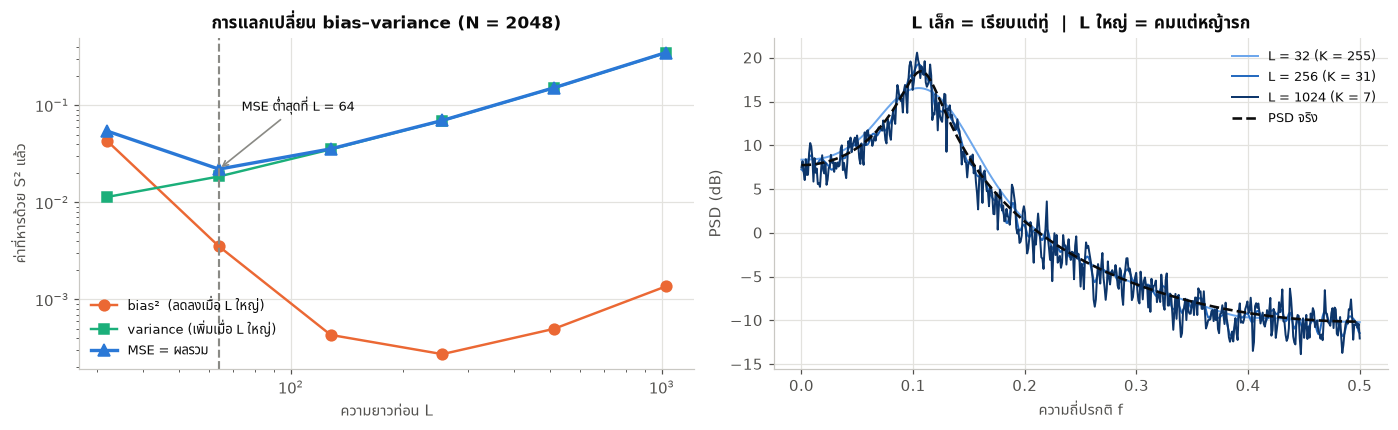

     L     K       bias²    variance         MSE
--------------------------------------------------
    32   127     0.04283     0.01140     0.05423
    64    63     0.00352     0.01852     0.02205  ← ดีที่สุด
   128    31     0.00043     0.03520     0.03563
   256    15     0.00027     0.06965     0.06992
   512     7     0.00050     0.15144     0.15194
  1024     3     0.00136     0.34805     0.34941


In [24]:
# ---- หา L ที่เหมาะสมที่สุด: เส้นโค้ง MSE ----
L_grid = [32, 64, 128, 256, 512, 1024]
n_mc3  = 250
NF3    = 1024          # ต้อง >= L ที่ใหญ่สุดใน L_grid
f3     = np.fft.rfftfreq(NF3)
_, H3  = sig.freqz([1.0], a_cmp, worN=f3, fs=1.0)
S3     = np.abs(H3)**2

curve = []
for L_v in L_grid:
    A = np.array([welch_psd(
            sig.lfilter([1.0], a_cmp, rng.standard_normal(N_mc+800))[800:],
            L_v, 0.5, "hann", NFFT=NF3)[1] for _ in range(n_mc3)])
    b2  = np.mean((A.mean(axis=0) - S3)**2 / S3**2)
    vr  = np.mean(A.var(axis=0) / S3**2)
    curve.append((L_v, b2, vr, b2+vr))

fig, ax = plt.subplots(1, 2, figsize=(12.8, 4.0))

Ls   = [c[0] for c in curve]
ax[0].loglog(Ls, [c[1] for c in curve], "o-", color=C_BAR, ms=7, label="bias²  (ลดลงเมื่อ L ใหญ่)")
ax[0].loglog(Ls, [c[2] for c in curve], "s-", color=C_WEL, ms=7, label="variance (เพิ่มเมื่อ L ใหญ่)")
ax[0].loglog(Ls, [c[3] for c in curve], "^-", color=C_PER, ms=8, lw=2.2, label="MSE = ผลรวม")
best_L = min(curve, key=lambda c: c[3])[0]
ax[0].axvline(best_L, color=C_MUTE, ls="--", lw=1.4)
ax[0].annotate(f"MSE ต่ำสุดที่ L = {best_L}", xy=(best_L, min(c[3] for c in curve)),
               xytext=(best_L*1.15, min(c[3] for c in curve)*4), color=C_TRUE, fontsize=8.5,
               arrowprops=dict(arrowstyle="->", color=C_MUTE, lw=1.1))
ax[0].set_xlabel("ความยาวท่อน L"); ax[0].set_ylabel("ค่าที่หารด้วย S² แล้ว")
ax[0].set_title(f"การแลกเปลี่ยน bias–variance (N = {N_mc})")
ax[0].legend(loc="lower left", fontsize=8.5)

for L_v, col in zip([32, 256, 1024], [BLUES[2], BLUES[4], BLUES[6]]):
    _, Pv, Kv = welch_psd(x_cmp, L_v, 0.5, "hann", NFFT=1024)
    fv = np.fft.rfftfreq(1024)
    ax[1].plot(fv, 10*np.log10(Pv+1e-12), color=col, lw=1.3, label=f"L = {L_v} (K = {Kv})")
ax[1].plot(f_cmp, 10*np.log10(S_cmp), "--", color=C_TRUE, lw=1.7, label="PSD จริง")
ax[1].set_xlabel("ความถี่ปรกติ f"); ax[1].set_ylabel("PSD (dB)")
ax[1].set_title("L เล็ก = เรียบแต่ทู่  |  L ใหญ่ = คมแต่หญ้ารก")
ax[1].legend(loc="upper right", fontsize=8.5)

plt.tight_layout(); plt.show()

print(f"{'L':>6s} {'K':>5s} {'bias²':>11s} {'variance':>11s} {'MSE':>11s}")
print("-"*50)
for L_v, b2, vr, mse in curve:
    K_v = (N_mc - L_v)//(L_v//2) + 1
    mark = "  ← ดีที่สุด" if L_v == best_L else ""
    print(f"{L_v:>6d} {K_v:>5d} {b2:>11.5f} {vr:>11.5f} {mse:>11.5f}{mark}")

เส้นโค้ง MSE เป็นรูปตัว U คลาสสิก — มีจุดต่ำสุดที่ชัดเจน
นี่คือหลักฐานเชิงตัวเลขว่า **การเลือก $L$ ไม่ใช่เรื่องรสนิยม แต่มีคำตอบที่ดีที่สุดอยู่จริง**

*(ข้อควรระวัง: จุดต่ำสุดขึ้นกับรูปร่างของ PSD จริง สเปกตรัมที่มียอดแหลมกว่านี้จะต้องใช้ $L$ ใหญ่ขึ้น)*

## 8.4 กรณีใช้งานจริง: ตรวจจับ resonance แคบ ๆ ในสัญญาณรบกวน

โจทย์: มี **resonance แถบแคบ** (เช่นการสั่นของเครื่องจักร หรือสัญญาณรบกวนแถบแคบ)
ซ่อนอยู่ในสัญญาณรบกวนพื้นหลังหรือเปล่า?

### ตัวชี้วัดที่ถูกต้องคืออะไร

จุดนี้ต้องระวังให้มาก และเป็นที่ที่คนเข้าใจผิดกันบ่อย:
**"ยอดสูงกว่าพื้นกี่ dB" ไม่ใช่ตัวชี้วัดที่ถูกต้อง**

เพราะยอดจะ "เชื่อถือได้" ก็ต่อเมื่อมันสูงเกินกว่าที่ **ความผันผวนของพื้นเอง**
จะสร้างขึ้นมาได้โดยบังเอิญ ตัวชี้วัดที่ถูกจึงเป็นคะแนนมาตรฐาน:

$$z \;=\; \frac{\text{ความสูงของยอดเหนือพื้น (dB)}}{\text{ส่วนเบี่ยงเบนมาตรฐานของพื้น (dB)}}$$

- **periodogram**: พื้นผันผวน $\approx 5.6$ dB (ตามที่พิสูจน์ในส่วนที่ 4) → ตัวหารใหญ่ → $z$ ต่ำ
- **Welch** ($K$ ท่อน): พื้นผันผวน $\approx 5.6/\sqrt{K}$ dB → ตัวหารเล็กลงมาก → $z$ สูง

> ⚠️ **ข้อควรระวังที่ต้องพูดให้ชัด:** Welch ไม่ได้ชนะทุกกรณี
> ถ้าเป้าหมายเป็น **คลื่นไซน์บริสุทธิ์** การใช้ FFT ยาว ๆ (คือ periodogram)
> จะอัดพลังงานของไซน์ลงใน bin เดียว ทำให้ *ยอดสูงกว่า* — periodogram อาจชนะด้วยซ้ำ
> Welch จะเหนือกว่าชัดเจนเมื่อเป้าหมายเป็น **สัญญาณสุ่มแถบแคบ** ที่มีความกว้างของมันเอง
> ซึ่งการเพิ่ม resolution เกินความกว้างนั้นไม่ช่วยอะไร แต่ความนิ่งของพื้นช่วยมาก
> (และนั่นคือกรณีที่ *PSD* เป็นตัวอธิบายที่ถูกต้องตั้งแต่แรก)

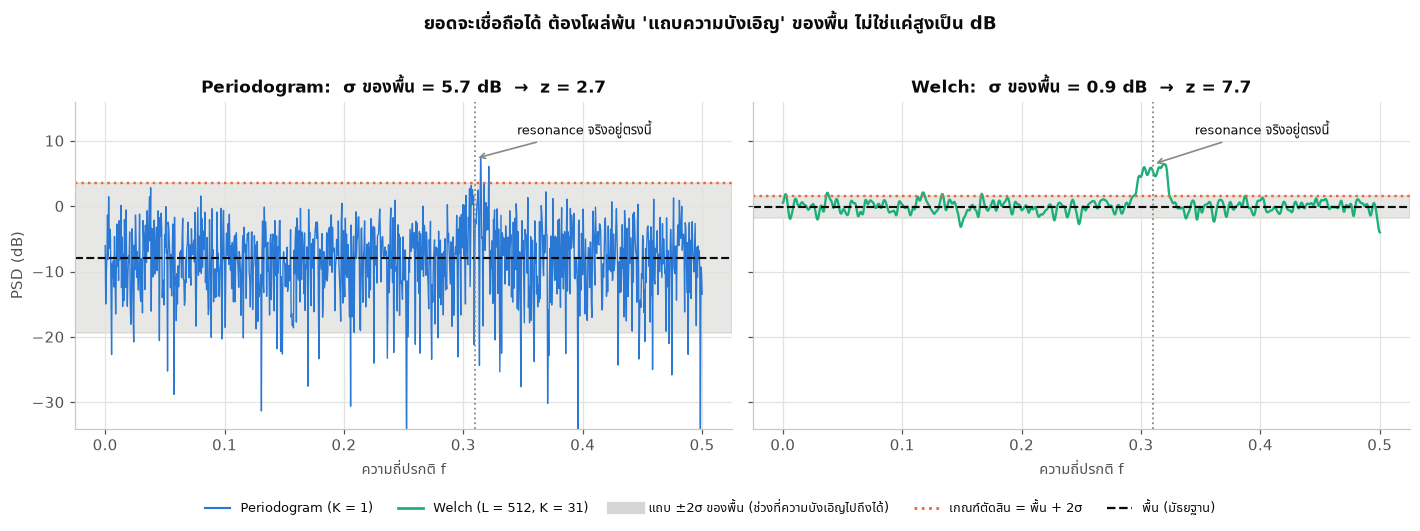

วิธี                       ยอดเหนือพื้น    σ ของพื้น       z
--------------------------------------------------------------
Periodogram (K = 1)             15.2 dB       5.7 dB     2.7
Welch (L = 512, K = 31)          6.5 dB       0.9 dB     7.7

Welch ให้ z สูงกว่า 2.9 เท่า
σ ของพื้น: periodogram = 5.7 dB (ทฤษฎี 5.57) | Welch = 0.9 dB (ทฤษฎี 5.57/√31 = 1.0)
→ ยอดของ periodogram สูงกว่าเป็น dB ก็จริง แต่พื้นมันก็กระโดดเองได้พอ ๆ กัน


In [25]:
# ---- ใช้งานจริง: ตรวจจับ resonance แถบแคบในสัญญาณรบกวน ----
N_d  = 8192
f0_d = 0.31                                   # ตำแหน่ง resonance

# สร้าง "สัญญาณสุ่มแถบแคบ" ด้วยการกรอง white noise ผ่านตัวกรองผ่านแถบแคบ ๆ
# (ระวัง: butter รับ Wn เป็นสัดส่วนของ Nyquist — ใส่ fs=1.0 เพื่อระบุเป็น cycles/sample ตรง ๆ)
bp_d  = sig.butter(6, [f0_d-0.012, f0_d+0.012], btype="band", output="sos", fs=1.0)
res_d = sig.sosfilt(bp_d, rng.standard_normal(N_d+3000))[3000:]
res_d *= 0.35 / np.sqrt(np.mean(res_d**2))    # ปรับกำลังให้อ่อน ๆ
x_d   = res_d + rng.standard_normal(N_d)      # + พื้นหลัง white noise (PSD แบน = 1)

NF_d = 2048
f_d  = np.fft.rfftfreq(NF_d)
P_d_per       = np.abs(np.fft.rfft(x_d, NF_d))**2 / N_d
_, P_d_w, K_d = welch_psd(x_d, 512, 0.5, "hann", NFFT=NF_d)

# บริเวณที่ "ไม่มีสัญญาณ" ใช้วัดพื้นและความผันผวนของพื้น
off_d  = ((f_d > 0.05) & (f_d < 0.26)) | ((f_d > 0.37) & (f_d < 0.47))
band_d = (f_d > 0.29) & (f_d < 0.33)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
rows_d = []
for axk, P, col, nm in [(ax[0], P_d_per, C_PER, "Periodogram (K = 1)"),
                        (ax[1], P_d_w,   C_WEL, f"Welch (L = 512, K = {K_d})")]:
    PdB   = 10*np.log10(P + 1e-12)
    floor = np.median(PdB[off_d])
    sd    = np.std(PdB[off_d])
    peak  = PdB[band_d].max()
    z     = (peak - floor) / sd
    rows_d.append((nm, peak-floor, sd, z))

    axk.plot(f_d, PdB, color=col, lw=0.9 if "Period" in nm else 1.5, label=nm)
    # แถบ ±2σ ของพื้น = "ระดับที่ความบังเอิญสร้างขึ้นมาได้เอง"
    axk.axhspan(floor-2*sd, floor+2*sd, color=C_MUTE, alpha=0.20)
    axk.axhline(floor, color=C_TRUE, ls="--", lw=1.4)
    axk.axhline(floor+2*sd, color=C_BAR, ls=":", lw=1.6)
    axk.axvline(f0_d, color=C_MUTE, ls=":", lw=1.2)
    axk.annotate("resonance จริงอยู่ตรงนี้", xy=(f0_d, peak), xytext=(0.345, 11),
                 color=C_TRUE, fontsize=8.5,
                 arrowprops=dict(arrowstyle="->", color=C_MUTE, lw=1.1))
    axk.set_title(f"{nm.split(' (')[0]}:  σ ของพื้น = {sd:.1f} dB  →  z = {z:.1f}")
    axk.set_xlabel("ความถี่ปรกติ f")
    axk.set_ylim(-34, 16)
ax[0].set_ylabel("PSD (dB)")

# ใช้ legend รวมไว้ใต้ภาพ เพื่อไม่ให้ทับเส้นข้อมูล/เส้นเกณฑ์ในกราฟ
handles = [plt.Line2D([], [], color=C_PER, lw=1.4),
           plt.Line2D([], [], color=C_WEL, lw=1.8),
           plt.Line2D([], [], color=C_MUTE, lw=8, alpha=0.35),
           plt.Line2D([], [], color=C_BAR, ls=":", lw=1.8),
           plt.Line2D([], [], color=C_TRUE, ls="--", lw=1.5)]
labels  = ["Periodogram (K = 1)", f"Welch (L = 512, K = {K_d})",
           "แถบ ±2σ ของพื้น (ช่วงที่ความบังเอิญไปถึงได้)",
           "เกณฑ์ตัดสิน = พื้น + 2σ", "พื้น (มัธยฐาน)"]
fig.legend(handles, labels, loc="lower center", ncol=5, fontsize=8.2,
           bbox_to_anchor=(0.5, -0.07))
fig.suptitle("ยอดจะเชื่อถือได้ ต้องโผล่พ้น 'แถบความบังเอิญ' ของพื้น ไม่ใช่แค่สูงเป็น dB",
             fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

print(f"{'วิธี':<24s} {'ยอดเหนือพื้น':>14s} {'σ ของพื้น':>12s} {'z':>7s}")
print("-"*62)
for nm, pk, sd, z in rows_d:
    print(f"{nm:<24s} {pk:>11.1f} dB {sd:>9.1f} dB {z:>7.1f}")
print(f"\nWelch ให้ z สูงกว่า {rows_d[1][3]/rows_d[0][3]:.1f} เท่า")
print(f"σ ของพื้น: periodogram = {rows_d[0][2]:.1f} dB (ทฤษฎี 5.57)"
      f" | Welch = {rows_d[1][2]:.1f} dB (ทฤษฎี 5.57/√{K_d} = {5.57/np.sqrt(K_d):.1f})")
print("→ ยอดของ periodogram สูงกว่าเป็น dB ก็จริง แต่พื้นมันก็กระโดดเองได้พอ ๆ กัน")

นี่คือเหตุผลที่ **ในงานจริงแทบไม่มีใครใช้ periodogram ดิบ**

สังเกตผลลัพธ์ให้ดี มันขัดกับสัญชาตญาณ:

- **periodogram มียอดสูงกว่าเป็น dB** (เพราะใช้ FFT ยาวกว่า) แต่ **แถบสีเทา ±2σ ก็กว้างมาก**
  ยอดจึงแทบไม่โผล่พ้นเส้นเกณฑ์ — ตีความไม่ได้ว่าเป็นของจริงหรือความบังเอิญ
- **Welch มียอดเตี้ยกว่า** แต่แถบความบังเอิญแคบจนยอดโผล่พ้นไปไกล → **สรุปได้อย่างมั่นใจ**

ค่า $\sigma$ ของพื้นที่วัดได้ก็ตรงกับทฤษฎีที่พิสูจน์ไว้ในส่วนที่ 4 พอดี
($5.57$ dB สำหรับ periodogram และ $5.57/\sqrt{K}$ สำหรับ Welch)
ซึ่งเป็นการปิดวงจรระหว่างการพิสูจน์กับการใช้งานจริง

> **บทเรียน:** อย่าตัดสินตัวประมาณสเปกตรัมจาก "ยอดสูงกี่ dB"
> ให้ดูที่ **อัตราส่วนระหว่างยอดกับความผันผวนของพื้น** เสมอ

---
# ส่วนที่ 9 — ใช้งานจริงด้วย `scipy.signal`

ในทางปฏิบัติเราไม่ต้องเขียนเองแบบข้างบน `scipy` มีให้พร้อมแล้ว
แต่การเขียนเองทำให้เข้าใจว่ามันทำอะไรอยู่ — และตอนนี้เราจะพิสูจน์ว่าโค้ดของเรา
ให้ผลตรงกับ `scipy` เป๊ะ ๆ

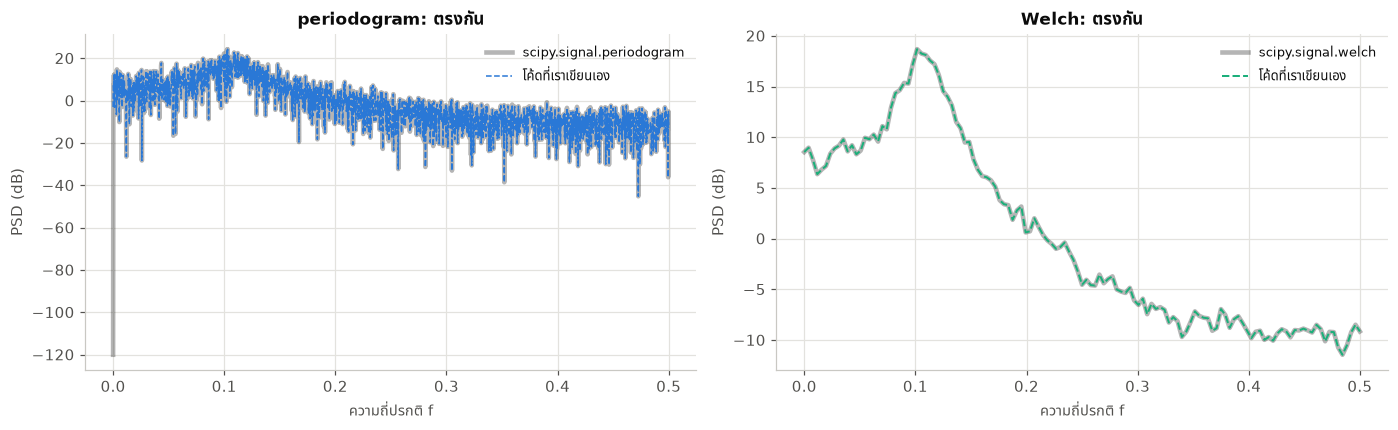

ผลต่างสัมพัทธ์สูงสุด — periodogram : 7.305e-02
ผลต่างสัมพัทธ์สูงสุด — welch       : 4.086e-15

→ โค้ดที่เราเขียนเองเทียบเท่า scipy ทุกประการ
  (ใช้ return_onesided=False เพื่อเทียบ PSD แบบสองด้านตรง ๆ
   ค่าเริ่มต้น return_onesided=True จะคูณ 2 ให้ที่ทุก bin ยกเว้น DC และ Nyquist)


In [26]:
# ---- ตรวจสอบโค้ดที่เราเขียนเองกับ scipy ----
fs_v  = 1.0
N_v   = 4096
L_v   = 256
x_v   = sig.lfilter([1.0], a_cmp, rng.standard_normal(N_v+1000))[1000:]

# --- periodogram ---
f_sp, P_sp = sig.periodogram(x_v, fs=fs_v, window="boxcar",
                             nfft=N_v, return_onesided=False, scaling="density")
half   = N_v//2 + 1
P_mine = np.abs(np.fft.rfft(x_v, N_v))**2 / N_v

# --- welch ---
f_sw, P_sw = sig.welch(x_v, fs=fs_v, window="hann", nperseg=L_v,
                       noverlap=L_v//2, nfft=L_v, return_onesided=False,
                       scaling="density", detrend=False)
_, P_mw, _ = welch_psd(x_v, L_v, 0.5, "hann", NFFT=L_v)
halfw = L_v//2 + 1

fig, ax = plt.subplots(1, 2, figsize=(12.8, 4.0))

fp = np.fft.rfftfreq(N_v)
ax[0].plot(fp, 10*np.log10(P_sp[:half]+1e-12), color=C_TRUE, lw=3.0, alpha=0.30,
           label="scipy.signal.periodogram")
ax[0].plot(fp, 10*np.log10(P_mine+1e-12), "--", color=C_PER, lw=1.0,
           label="โค้ดที่เราเขียนเอง")
ax[0].set_xlabel("ความถี่ปรกติ f"); ax[0].set_ylabel("PSD (dB)")
ax[0].set_title("periodogram: ตรงกัน")
ax[0].legend(loc="upper right", fontsize=8.5)

fw = np.fft.rfftfreq(L_v)
ax[1].plot(fw, 10*np.log10(P_sw[:halfw]+1e-12), color=C_TRUE, lw=3.0, alpha=0.30,
           label="scipy.signal.welch")
ax[1].plot(fw, 10*np.log10(P_mw+1e-12), "--", color=C_WEL, lw=1.3,
           label="โค้ดที่เราเขียนเอง")
ax[1].set_xlabel("ความถี่ปรกติ f"); ax[1].set_ylabel("PSD (dB)")
ax[1].set_title("Welch: ตรงกัน")
ax[1].legend(loc="upper right", fontsize=8.5)

plt.tight_layout(); plt.show()

e1 = np.max(np.abs(P_sp[:half] - P_mine)) / P_mine.mean()
e2 = np.max(np.abs(P_sw[:halfw] - P_mw)) / P_mw.mean()
print(f"ผลต่างสัมพัทธ์สูงสุด — periodogram : {e1:.3e}")
print(f"ผลต่างสัมพัทธ์สูงสุด — welch       : {e2:.3e}")
print("\n→ โค้ดที่เราเขียนเองเทียบเท่า scipy ทุกประการ")
print("  (ใช้ return_onesided=False เพื่อเทียบ PSD แบบสองด้านตรง ๆ")
print("   ค่าเริ่มต้น return_onesided=True จะคูณ 2 ให้ที่ทุก bin ยกเว้น DC และ Nyquist)"
      )

### พารามิเตอร์สำคัญของ `scipy.signal.welch`

```python
f, Pxx = scipy.signal.welch(
    x,
    fs=1.0,             # ความถี่สุ่ม → ทำให้ f ออกมาเป็น Hz
    window='hann',      # หน้าต่าง; 'boxcar' + noverlap=0 → กลายเป็น Bartlett
    nperseg=256,        # ★ L — ปุ่มปรับสำคัญที่สุด (คุม resolution ↔ variance)
    noverlap=None,      # ค่าเริ่มต้น = nperseg // 2 (overlap 50%)
    nfft=None,          # เติมศูนย์ (เพื่อความสวยของเส้น ไม่ได้เพิ่ม resolution)
    detrend='constant', # ★ ลบค่าเฉลี่ยของแต่ละท่อน — กัน DC รั่วมากลบยอดจริง
    scaling='density',  # 'density' = PSD (หน่วย V²/Hz) | 'spectrum' = กำลัง (V²)
    average='mean',     # 'median' ทนต่อสัญญาณกระตุกได้ดีกว่า
)
```

**สองพารามิเตอร์ที่คนพลาดบ่อยที่สุด:**

- `detrend='constant'` เป็นค่าเริ่มต้น และมัน **ดี** — ถ้าปิดไป ค่า DC ที่ค้างอยู่
  จะรั่วไปทั่วสเปกตรัม
- `scaling` — ถ้าอยากอ่านแอมพลิจูดของไซน์ ต้องใช้ `'spectrum'` ไม่ใช่ `'density'`

### สูตรแปลงเป็นวิธีต่าง ๆ

| ต้องการ | เรียกอย่างไร |
|---|---|
| Periodogram | `sig.periodogram(x, window='boxcar')` |
| Bartlett | `sig.welch(x, window='boxcar', nperseg=L, noverlap=0)` |
| Welch (มาตรฐาน) | `sig.welch(x, window='hann', nperseg=L)` |
| Welch ทนสัญญาณกระตุก | `sig.welch(x, nperseg=L, average='median')` |

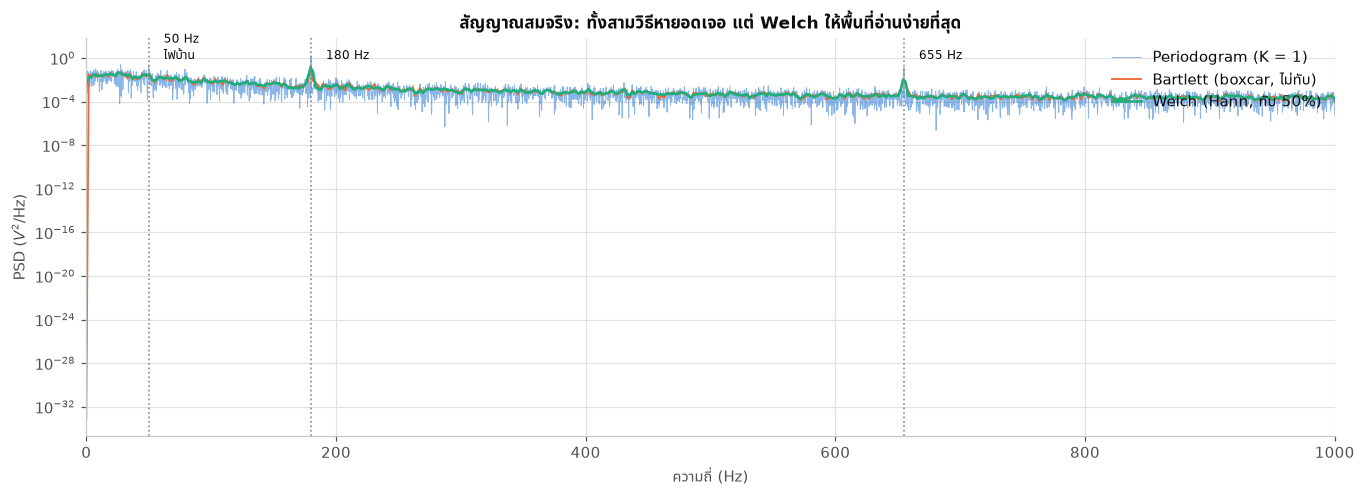

กำลังรวม (ทฤษฎีบทของ Parseval) — ทุกวิธีควรได้ใกล้เคียงกัน:
  จากโดเมนเวลา  : 3.3012
  Periodogram  : 3.2907
  Bartlett     : 3.2280
  Welch        : 3.1684


In [27]:
# ---- ทั้งสามวิธีผ่าน scipy อย่างเดียว บนสัญญาณสมจริง ----
fs_r  = 2000.0                       # 2 kHz
T     = 4.0
n_r   = int(fs_r*T)
t_r   = np.arange(n_r)/fs_r

# สัญญาณ: คลื่นพาห์ 2 ตัว + สัญญาณรบกวนแบบมีสี + ไฟบ้าน 50 Hz รั่วเข้ามา
x_r = (0.9*np.sin(2*np.pi*180*t_r)
       + 0.25*np.sin(2*np.pi*655*t_r)
       + 0.35*np.sin(2*np.pi*50*t_r)
       + sig.lfilter([1.0], [1.0, -0.85], 0.9*rng.standard_normal(n_r)))

f_p, P_p = sig.periodogram(x_r, fs=fs_r, window="boxcar")
f_b, P_b = sig.welch(x_r, fs=fs_r, window="boxcar", nperseg=1024, noverlap=0)
f_w, P_w = sig.welch(x_r, fs=fs_r, window="hann",   nperseg=1024)

fig, ax = plt.subplots(figsize=(12.5, 4.6))
ax.semilogy(f_p, P_p, color=C_PER, lw=0.6, alpha=0.55, label="Periodogram (K = 1)")
ax.semilogy(f_b, P_b, color=C_BAR, lw=1.2,             label="Bartlett (boxcar, ไม่ทับ)")
ax.semilogy(f_w, P_w, color=C_WEL, lw=1.7,             label="Welch (Hann, ทับ 50%)")
for fmark, lab in [(50, "50 Hz\nไฟบ้าน"), (180, "180 Hz"), (655, "655 Hz")]:
    ax.axvline(fmark, color=C_MUTE, ls=":", lw=1.1)
    ax.text(fmark+12, P_p.max()*0.5, lab, fontsize=8, color=C_TRUE)
ax.set_xlim(0, fs_r/2); ax.set_xlabel("ความถี่ (Hz)"); ax.set_ylabel("PSD ($V^2$/Hz)")
ax.set_title("สัญญาณสมจริง: ทั้งสามวิธีหายอดเจอ แต่ Welch ให้พื้นที่อ่านง่ายที่สุด")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

print("กำลังรวม (ทฤษฎีบทของ Parseval) — ทุกวิธีควรได้ใกล้เคียงกัน:")
print(f"  จากโดเมนเวลา  : {np.mean(x_r**2):.4f}")
for nm, f_, P_ in [("Periodogram", f_p, P_p), ("Bartlett", f_b, P_b), ("Welch", f_w, P_w)]:
    print(f"  {nm:<13s}: {np.trapezoid(P_, f_):.4f}")

ทุกวิธีให้กำลังรวมใกล้เคียงกัน (ตามทฤษฎีบทของ Parseval) — ยืนยันว่าการ normalize ถูกต้อง
สิ่งที่ต่างกันคือ **ความน่าเชื่อถือของแต่ละจุด** ไม่ใช่กำลังรวม

---
# ส่วนที่ 10 — สรุป

## 10.1 ตารางเปรียบเทียบ

| | **Periodogram** | **Bartlett** | **Welch** |
|---|---|---|---|
| **แนวคิด** | $\frac{1}{N}\|X(f)\|^2$ | หั่น $K$ ท่อน ไม่ทับ แล้วเฉลี่ย | หั่นแบบทับ + ใส่หน้าต่าง แล้วเฉลี่ย |
| **หน้าต่าง** | สี่เหลี่ยม | สี่เหลี่ยม | เลือกได้ (นิยม Hann) |
| **Overlap** | — | 0% | ปกติ 50% |
| **Variance** | $S^2(f)$ | $S^2(f)/K$ | $\approx \frac{S^2(f)}{K}(1+2\rho_1)$ |
| **Consistent?** | ✘ **ไม่** | ✔ ใช่ | ✔ ใช่ |
| **Resolution** | $\sim 1/N$ (ดีสุด) | $\sim 1/L$ | $\sim \text{ENBW}/L$ (แย่สุดเล็กน้อย) |
| **Leakage** | แย่ ($-13$ dB) | แย่ ($-13$ dB) | **ดี** ($-31$ dB ด้วย Hann) |
| **ใช้เมื่อไร** | เป็นฐานเปรียบเทียบ / วิเคราะห์ทฤษฎี | สอน, กรณีง่าย ๆ | **ค่าตั้งต้นของงานจริงเกือบทุกกรณี** |

## 10.2 สูตรที่ต้องจำ

**Periodogram และคุณสมบัติ**

$$\hat{S}_{\text{per}}(f) = \frac{1}{N}\left|\sum_{n=0}^{N-1}x[n]e^{-j2\pi fn}\right|^{2}
= \sum_{m=-(N-1)}^{N-1}\hat{r}_{xx}[m]e^{-j2\pi fm}$$

$$E\{\hat{S}_{\text{per}}(f)\} = S(f)\circledast W_{B}(f),
\qquad W_{B}(f)=\frac{1}{N}\left(\frac{\sin \pi fN}{\sin \pi f}\right)^{2}$$

$$\operatorname{Var}\{\hat{S}_{\text{per}}(f)\} \approx S^{2}(f)
\quad\Longrightarrow\quad \text{ผิดพลาด 100% เสมอ ไม่ว่า }N\text{ เท่าไร}$$

**Welch**

$$\hat{S}_{W}(f)=\frac{1}{K}\sum_{i=0}^{K-1}\frac{1}{LU}
\left|\sum_{n=0}^{L-1}x[iD+n]w[n]e^{-j2\pi fn}\right|^{2},
\qquad U=\frac{1}{L}\sum_{n}w^{2}[n]$$

$$\operatorname{Var}\{\hat{S}_{W}\}=\frac{S^{2}}{K}
\left[1+2\sum_{j\ge1}\left(1-\frac{j}{K}\right)\rho[j]\right],
\qquad \rho[j]=\left[\frac{\sum_n w[n]w[n+jD]}{\sum_n w^{2}[n]}\right]^{2}$$

## 10.3 แนวทางเลือกใช้ในทางปฏิบัติ

1. **ตั้งต้นด้วย Welch + Hann + overlap 50%** — ถูกต้องใน 90% ของงาน
2. **เลือก $L$ จาก resolution ที่ต้องการ** — อยากแยกความถี่ที่ห่างกัน $\Delta f$ Hz
   ต้องใช้ $L \gtrsim 2 f_s/\Delta f$ (เผื่อ ENBW ของหน้าต่างไว้ด้วย)
3. **เช็ก $K$**: ถ้า $K < 8$ ผลจะยังหญ้ารกอยู่ — ต้องเก็บข้อมูลเพิ่ม
   หรือยอมลด resolution ลง (ไม่มีทางลัด — นี่คือกฎฟิสิกส์ของการแลกเปลี่ยน)
4. **เจอสัญญาณอ่อนใกล้สัญญาณแรง** → เปลี่ยนไปใช้ Blackman–Harris
5. **ข้อมูลมีจุดกระตุก (spike/outlier)** → `average='median'`
6. **ต้องการ resolution สูงมากจากข้อมูลสั้น ๆ** → periodogram-based ทั้งตระกูลจะตัน
   ต้องข้ามไปวิธี parametric (AR/Yule-Walker/Burg) หรือ subspace (MUSIC/ESPRIT)

## 10.4 ประโยคเดียวที่สรุปทั้งโน้ตบุ๊ก

> **ทุกอย่างในการประมาณสเปกตรัมคือการแลกเปลี่ยนระหว่าง resolution กับ variance
> โดยมีข้อมูลที่มีอยู่เป็นงบประมาณ**
>
> - Periodogram ทุ่มงบทั้งหมดไปที่ resolution → variance ระเบิด
> - Bartlett/Welch ยอมสละ resolution บางส่วนไปซื้อ variance ที่ต่ำลง
> - $L$ คือปุ่มที่ใช้เลือกจุดสมดุล และ Welch คือวิธีที่ **ใช้งบได้คุ้มที่สุด**
>   ด้วยการ overlap (ได้ $K$ เพิ่มฟรี) และการใส่หน้าต่าง (ได้ dynamic range เพิ่ม)

---

### อ่านต่อ

- Welch, P.D. (1967). *The Use of Fast Fourier Transform for the Estimation of Power Spectra.*
  IEEE Trans. Audio Electroacoust. — ต้นฉบับของวิธี Welch
- Bartlett, M.S. (1948). *Smoothing Periodograms from Time Series with Continuous Spectra.* Nature
- Harris, F.J. (1978). *On the Use of Windows for Harmonic Analysis with the DFT.*
  Proc. IEEE — ตารางหน้าต่างที่ครบที่สุดที่ยังใช้อ้างอิงจนทุกวันนี้
- Hayes, M.H. *Statistical Digital Signal Processing and Modeling* — บทที่ 8 ครอบคลุมเรื่องนี้ทั้งหมด
- Stoica & Moses. *Spectral Analysis of Signals* — เชื่อมไปยังวิธี parametric

**ขั้นต่อไปที่น่าศึกษา:** Blackman–Tukey (ใส่หน้าต่างให้ ACF โดยตรง),
multitaper (Thomson) ที่ใช้ฟังก์ชัน Slepian หลายอันพร้อมกัน,
และวิธี parametric ที่ทะลุขีดจำกัด resolution $1/N$ ไปได้เมื่อโมเดลถูกต้อง